In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import json

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")

assert PROJECT_ROOT.exists(), f"Project not found: {PROJECT_ROOT}"

REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Notebook: 06_ML_Evaluation_Audit.ipynb")
print("Read-only audit: Original datasets will not be modified.")

Project: /Users/naitikdonda/Desktop/CasualMark v3
Notebook: 06_ML_Evaluation_Audit.ipynb
Read-only audit: Original datasets will not be modified.


In [2]:
SEARCH_TERMS = [
    "prediction", "audit", "auuc", "qini",
    "uplift", "metric", "evaluation", "policy"
]

IGNORE_DIRS = {
    ".git", ".venv", "venv", "__pycache__",
    "node_modules"
}

matched_files = []

for path in PROJECT_ROOT.rglob("*"):
    if not path.is_file():
        continue

    if any(part in IGNORE_DIRS for part in path.parts):
        continue

    if path.suffix.lower() not in {
        ".csv", ".json", ".parquet", ".py", ".ipynb"
    }:
        continue

    if any(term in path.name.lower() for term in SEARCH_TERMS):
        matched_files.append(path)

for path in sorted(matched_files):
    print(path.relative_to(PROJECT_ROOT))

print(f"\nTotal matching files: {len(matched_files)}")

backend/uplift_service.py
data/evaluation/causalmark_evaluation_report.json
data/evaluation/causalmark_evaluation_summary.csv
data/evaluation/causalmark_final_evaluation_package.json
data/evaluation/causalmark_final_model_metrics.csv
data/evaluation/criteo_evaluation_summary.json
data/evaluation/criteo_model_evaluation.json
data/evaluation/criteo_prediction_column_audit.json
data/evaluation/criteo_prediction_quality_audit.json
data/evaluation/criteo_uplift_decile_quality.csv
data/evaluation/criteo_uplift_decile_summary.csv
data/evaluation/criteo_uplift_final_summary.json
data/evaluation/criteo_uplift_prediction_quality.csv
data/evaluation/criteo_uplift_ranking_summary.csv
data/evaluation/criteo_uplift_strategy_comparison.csv
data/evaluation/criteo_uplift_targeting_quality.csv
data/evaluation/evaluation_artifact_inventory.csv
data/evaluation/notebook_05_post_copy_audit.csv
data/knowledge_base/hillstrom_evidence_review_metrics.json
data/knowledge_base/hillstrom_rag_evaluation.json
data/k

In [3]:
csv_files = [
    p for p in matched_files
    if p.suffix.lower() == ".csv"
]

audit_results = []

for path in sorted(csv_files):
    try:
        df = pd.read_csv(path, low_memory=False)

        result = {
            "file": str(path.relative_to(PROJECT_ROOT)),
            "rows": len(df),
            "columns": len(df.columns),
            "exact_duplicate_rows": int(df.duplicated().sum()),
            "total_missing_cells": int(df.isna().sum().sum()),
            "columns_list": df.columns.tolist()
        }

        audit_results.append(result)

        print("\n" + "=" * 70)
        print("FILE:", result["file"])
        print("Shape:", df.shape)
        print("Exact duplicate rows:", result["exact_duplicate_rows"])
        print("Missing cells:", result["total_missing_cells"])
        print("Columns:", df.columns.tolist())

        if "prediction" in path.name.lower() or "audit" in path.name.lower():
            print("\nSample:")
            print(df.head(3).to_string(index=False))

    except Exception as e:
        print(f"\nCould not inspect {path.name}: {e}")

audit_summary = pd.DataFrame(audit_results)
print("\nAudit summary:")
display(audit_summary)


FILE: data/evaluation/causalmark_evaluation_summary.csv
Shape: (10, 2)
Exact duplicate rows: 0
Missing cells: 0
Columns: ['metric', 'value']

FILE: data/evaluation/causalmark_final_model_metrics.csv
Shape: (5, 2)
Exact duplicate rows: 0
Missing cells: 0
Columns: ['Metric', 'Value']

FILE: data/evaluation/criteo_uplift_decile_quality.csv
Shape: (10, 6)
Exact duplicate rows: 0
Missing cells: 0
Columns: ['uplift_decile', 'customers', 'mean_predicted_uplift', 'median_predicted_uplift', 'min_predicted_uplift', 'max_predicted_uplift']

FILE: data/evaluation/criteo_uplift_decile_summary.csv
Shape: (10, 6)
Exact duplicate rows: 0
Missing cells: 0
Columns: ['uplift_decile', 'customers', 'mean_predicted_uplift', 'median_predicted_uplift', 'minimum_uplift', 'maximum_uplift']

FILE: data/evaluation/criteo_uplift_prediction_quality.csv
Shape: (13, 2)
Exact duplicate rows: 0
Missing cells: 0
Columns: ['metric', 'value']

Sample:
           metric            value
prediction_column predicted_uplift


,file,rows,columns,exact_duplicate_rows,total_missing_cells,columns_list
0,data/evaluation/causalmark_evaluation_summary.csv,10,2,0,0,"[metric, value]"
1,data/evaluation/causalmark_final_model_metrics...,5,2,0,0,"[Metric, Value]"
2,data/evaluation/criteo_uplift_decile_quality.csv,10,6,0,0,"[uplift_decile, customers, mean_predicted_upli..."
3,data/evaluation/criteo_uplift_decile_summary.csv,10,6,0,0,"[uplift_decile, customers, mean_predicted_upli..."
4,data/evaluation/criteo_uplift_prediction_quali...,13,2,0,0,"[metric, value]"
5,data/evaluation/criteo_uplift_ranking_summary.csv,1,8,0,0,"[uplift_column, valid_predictions, positive_pr..."
6,data/evaluation/criteo_uplift_strategy_compari...,6,6,0,0,"[strategy, target_fraction, customers_targeted..."
7,data/evaluation/criteo_uplift_targeting_qualit...,6,6,0,0,"[target_fraction, customers_selected, mean_pre..."
8,data/evaluation/evaluation_artifact_inventory.csv,6,4,0,1,"[file, exists, size_bytes, path]"
9,data/evaluation/notebook_05_post_copy_audit.csv,73,6,0,6,"[cell_number, type, lines, contains_criteo, co..."


In [4]:
import ast

SOURCE_DIRS = [
    PROJECT_ROOT / "src",
    PROJECT_ROOT / "notebooks"
]

KEYWORDS = [
    "auuc", "qini", "uplift",
    "treatment", "outcome",
    "predicted_uplift", "criteo"
]

for directory in SOURCE_DIRS:
    if not directory.exists():
        continue

    for path in sorted(directory.rglob("*")):
        if not path.is_file():
            continue

        if path.suffix.lower() not in {".py", ".ipynb"}:
            continue

        if any(part in IGNORE_DIRS for part in path.parts):
            continue

        try:
            if path.suffix.lower() == ".py":
                content = path.read_text(errors="ignore")
            else:
                notebook = json.loads(path.read_text())
                content = "\n".join(
                    "".join(cell.get("source", []))
                    for cell in notebook.get("cells", [])
                    if cell.get("cell_type") == "code"
                )

            lines = content.splitlines()
            matches = [
                (i + 1, line.strip())
                for i, line in enumerate(lines)
                if any(keyword in line.lower() for keyword in KEYWORDS)
            ]

            if matches:
                print("\n" + "=" * 70)
                print("FILE:", path.relative_to(PROJECT_ROOT))

                for line_no, line in matches:
                    print(f"{line_no}: {line[:220]}")

        except Exception as e:
            print(f"Could not inspect {path.name}: {e}")


FILE: src/causalmark/analysis_engine.py
5: def calculate_lift(treatment_conversions, treatment_users,
7: if treatment_users <= 0 or control_users <= 0:
10: if not 0 <= treatment_conversions <= treatment_users:
11: raise ValueError("Invalid treatment conversions.")
16: treatment_rate = treatment_conversions / treatment_users
19: absolute_lift_pp = (treatment_rate - control_rate) * 100
21: (treatment_rate - control_rate) / control_rate * 100
26: "treatment_rate_pct": round(treatment_rate * 100, 4),
36: def test_conversion_significance(treatment_conversions, treatment_users,
39: if treatment_users <= 0 or control_users <= 0:
42: if not 0 <= treatment_conversions <= treatment_users:
43: raise ValueError("Invalid treatment conversions.")
51: p_t = treatment_conversions / treatment_users
54: treatment_conversions + control_conversions
55: ) / (treatment_users + control_users)
59: (1 / treatment_users + 1 / control_users)
73: def analyze_experiment(treatment_conversions, treatment_users,
78:

In [5]:
import re

patterns = [
    r"def\s+\w*(auuc|qini|uplift|policy_value)\w*\s*\(",
    r"(auuc|qini|uplift_auc|qini_auc)",
    r"cumulative_gain|cumulative_response"
]

for path in (PROJECT_ROOT / "src").rglob("*.py"):
    if any(part in IGNORE_DIRS for part in path.parts):
        continue

    try:
        lines = path.read_text(errors="ignore").splitlines()

        for i, line in enumerate(lines):
            if any(re.search(p, line, re.IGNORECASE) for p in patterns):
                start = max(0, i - 2)
                end = min(len(lines), i + 5)

                print(f"\n--- {path.relative_to(PROJECT_ROOT)}:{i + 1} ---")
                for j in range(start, end):
                    print(f"{j + 1}: {lines[j]}")
    except Exception as e:
        print("Skipped:", path, e)


--- src/causalmark/uplift/metrics.py:5 ---
3: from typing import Dict, Any
4: 
5: def compute_cumulative_gain_curve(
6:     y_true: np.ndarray,
7:     treatment: np.ndarray,
8:     uplift_score: np.ndarray
9: ) -> pd.DataFrame:

--- src/causalmark/uplift/metrics.py:11 ---
9: ) -> pd.DataFrame:
10:     """
11:     Computes a numerically robust cumulative uplift and Qini gain curve.
12:     Guarantees:
13:     - Zero NaNs at initial fractions
14:     - Unbiased random ordering when scores are tied
15:     - Anchors exactly at (0.0, 0.0)

--- src/causalmark/uplift/metrics.py:50 ---
48:     fractions = np.arange(1, n + 1) / n
49: 
50:     # Qini Gain: Y_t(k) - Y_c(k) * (N_t(k) / max(N_c(k), 1))
51:     scale_factor = cum_treated_total / np.maximum(cum_control_total, 1)
52:     qini_gain = cum_treated_y - cum_control_y * scale_factor
53:     qini_gain[cum_control_total == 0] = cum_treated_y[cum_control_total == 0]
54: 

--- src/causalmark/uplift/metrics.py:52 ---
50:     # Qini Gain: Y_t(k

In [6]:
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"

for path in sorted(NOTEBOOK_DIR.glob("*.ipynb")):
    try:
        notebook = json.loads(path.read_text())

        for cell_no, cell in enumerate(notebook.get("cells", []), start=1):
            if cell.get("cell_type") != "code":
                continue

            source = "".join(cell.get("source", []))
            lines = source.splitlines()

            if any(
                term in source.lower()
                for term in [
                    "auuc", "qini", "predicted_uplift",
                    "treatment", "outcome", "train_test_split"
                ]
            ):
                print(f"\n{'=' * 70}")
                print(f"{path.name} | Cell {cell_no}")

                for line_no, line in enumerate(lines, start=1):
                    if any(
                        term in line.lower()
                        for term in [
                            "auuc", "qini", "predicted_uplift",
                            "treatment", "outcome",
                            "train_test_split", "drop_duplicates"
                        ]
                    ):
                        print(f"{line_no}: {line[:200]}")

    except Exception as e:
        print(f"Could not inspect {path.name}: {e}")


01_Causal_Experiment_Engine.ipynb | Cell 1
9: from sklearn.model_selection import train_test_split

01_Causal_Experiment_Engine.ipynb | Cell 4
10: print("\nTreatment groups:")
13: print("\nOutcome summary:")

01_Causal_Experiment_Engine.ipynb | Cell 5
18: print("Treatment groups:", df["segment"].unique())

01_Causal_Experiment_Engine.ipynb | Cell 6
1: treatment_value = "Mens E-Mail"
5:     df["segment"].isin([treatment_value, control_value])
8: experiment_df["treatment"] = (
9:     experiment_df["segment"] == treatment_value
13: print("Treatment customers:", (experiment_df["treatment"] == 1).sum())
14: print("Control customers:", (experiment_df["treatment"] == 0).sum())

01_Causal_Experiment_Engine.ipynb | Cell 7
5:     "treatment"
17: T = experiment_df["treatment"].to_numpy()
21: print("Treatment shape:", T.shape)
22: print("Outcome shape:", Y.shape)

01_Causal_Experiment_Engine.ipynb | Cell 8
2:     experiment_df["treatment"] == 0, "conversion"
6:     experiment_df["treatment"] == 1

In [7]:
for path in sorted(csv_files):
    if not any(
        term in path.name.lower()
        for term in ["prediction", "audit", "uplift", "criteo"]
    ):
        continue

    try:
        df = pd.read_csv(path, low_memory=False)

        treatment_cols = [
            c for c in df.columns
            if "treatment" in c.lower()
            or c.lower() in {"t", "w", "treat"}
        ]

        outcome_cols = [
            c for c in df.columns
            if "outcome" in c.lower()
            or "conversion" in c.lower()
            or c.lower() in {"y", "target", "label"}
        ]

        print(f"\nFILE: {path.relative_to(PROJECT_ROOT)}")
        print("Rows:", len(df))

        for col in treatment_cols + outcome_cols:
            print(f"\n{col}:")
            print(df[col].value_counts(dropna=False).head(20).to_dict())

    except Exception as e:
        print(f"Could not inspect {path.name}: {e}")


FILE: data/evaluation/criteo_uplift_decile_quality.csv
Rows: 10

FILE: data/evaluation/criteo_uplift_decile_summary.csv
Rows: 10

FILE: data/evaluation/criteo_uplift_prediction_quality.csv
Rows: 13

FILE: data/evaluation/criteo_uplift_ranking_summary.csv
Rows: 1

FILE: data/evaluation/criteo_uplift_strategy_comparison.csv
Rows: 6

FILE: data/evaluation/criteo_uplift_targeting_quality.csv
Rows: 6

FILE: data/evaluation/notebook_05_post_copy_audit.csv
Rows: 73

FILE: notebooks/artifacts/metrics/criteo_final_metrics.csv
Rows: 4

FILE: notebooks/artifacts/metrics/criteo_model_metrics.csv
Rows: 4

FILE: notebooks/artifacts/metrics/criteo_policy_curve.csv
Rows: 10

Observed Conversion Difference:
{0.0026893054834803663: 1, 0.00231037363523752: 1, 0.0011870941558441558: 1, 0.0010320662849297967: 1, 0.0009475683856952728: 1, 0.0007754077199584046: 1, 0.0007551285078990356: 1, 0.0007142857142857142: 1, 0.000673267324542119: 1, 0.0007265602942087184: 1}

FILE: notebooks/artifacts/metrics/criteo

In [9]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "reports").exists():
    PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")

IGNORE_DIRS = {
    ".git", ".venv", "venv", "__pycache__", "node_modules"
}

audit_files = []

for path in PROJECT_ROOT.rglob("*.csv"):
    if any(part in IGNORE_DIRS for part in path.parts):
        continue

    if any(
        word in path.name.lower()
        for word in ["audit", "prediction"]
    ):
        audit_files.append(path)

print("Audit files found:", len(audit_files))

for path in sorted(audit_files):
    try:
        df = pd.read_csv(path, low_memory=False)

        print("\n" + "=" * 70)
        print("FILE:", path.relative_to(PROJECT_ROOT))
        print("Total rows:", len(df))
        print("Exact duplicate rows:", int(df.duplicated().sum()))

        id_cols = [
            c for c in df.columns
            if any(term in c.lower() for term in [
                "id", "row_index", "sample",
                "observation", "customer", "user"
            ])
        ]

        print("Possible ID columns:", id_cols)

        for col in id_cols:
            print(
                f"{col}: unique={df[col].nunique(dropna=False)}, "
                f"repeated rows={int(df[col].duplicated().sum())}"
            )

    except Exception as e:
        print("Error reading file:", path.name, repr(e))

Audit files found: 4

FILE: data/evaluation/criteo_uplift_prediction_quality.csv
Total rows: 13
Exact duplicate rows: 0
Possible ID columns: []

FILE: data/evaluation/notebook_05_post_copy_audit.csv
Total rows: 73
Exact duplicate rows: 0
Possible ID columns: []

FILE: notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv
Total rows: 35000
Exact duplicate rows: 27189
Possible ID columns: []

FILE: results/nlp_finetuning/base_vs_finetuned_predictions.csv
Total rows: 100
Exact duplicate rows: 0
Possible ID columns: []


In [10]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path("/Users/naitikdonda/Desktop/CasualMark v3")

PREDICTION_FILE = (
    PROJECT_ROOT
    / "notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv"
)

df_pred = pd.read_csv(PREDICTION_FILE, low_memory=False)

print("Shape:", df_pred.shape)
print("\nColumns:")
print(df_pred.columns.tolist())

print("\nFirst 10 rows:")
display(df_pred.head(10))

print("\nLast 10 rows:")
display(df_pred.tail(10))

print("\nData types:")
print(df_pred.dtypes.to_string())

Shape: (35000, 3)

Columns:
['treatment', 'conversion', 'predicted_uplift']

First 10 rows:


,treatment,conversion,predicted_uplift
0,1,1,0.222333
1,1,0,0.216299
2,0,0,0.210274
3,1,0,0.208174
4,1,1,0.207844
5,1,1,0.206023
6,1,0,0.205077
7,1,0,0.201189
8,1,1,0.200577
9,1,0,0.199944



Last 10 rows:


,treatment,conversion,predicted_uplift
34990,1,0,-0.121290
34991,0,0,-0.122924
34992,1,1,-0.124541
34993,1,0,-0.125226
34994,1,0,-0.126875
34995,1,0,-0.128584
34996,1,0,-0.133597
34997,0,0,-0.134981
34998,1,0,-0.141792
34999,1,0,-0.149117



Data types:
treatment             int64
conversion            int64
predicted_uplift    float64


In [11]:
print("Total rows:", len(df_pred))
print("Exact duplicate rows:", int(df_pred.duplicated().sum()))
print("Unique complete rows:", len(df_pred.drop_duplicates()))

print("\nDuplicate rows by occurrence:")
print(
    df_pred.value_counts(dropna=False)
    .head(15)
    .rename("occurrences")
    .to_string()
)

print("\nColumns with only one unique value:")
for col in df_pred.columns:
    if df_pred[col].nunique(dropna=False) == 1:
        print(f"{col}: {df_pred[col].iloc[0]}")

Total rows: 35000
Exact duplicate rows: 27189
Unique complete rows: 7811

Duplicate rows by occurrence:
treatment  conversion  predicted_uplift
1          0            0.000000           19929
0          0            0.000000            3583
1          0           -0.000310             129
                       -0.003288             102
                       -0.004151              94
                       -0.000091              88
                       -0.011361              83
                       -0.002584              80
                       -0.009263              78
                       -0.009575              74
                       -0.004519              71
                       -0.010105              53
                       -0.001504              43
                       -0.000087              39
                       -0.000353              39

Columns with only one unique value:


In [12]:
print("Numeric columns:")
print(df_pred.select_dtypes(include=np.number).columns.tolist())

for col in df_pred.columns:
    if any(term in col.lower() for term in [
        "treatment", "outcome", "uplift",
        "prediction", "prob", "score", "effect"
    ]):
        print(f"\nColumn: {col}")
        print("Unique values:", df_pred[col].nunique(dropna=False))
        print("Missing:", int(df_pred[col].isna().sum()))

        if df_pred[col].nunique(dropna=False) <= 20:
            print(df_pred[col].value_counts(dropna=False).to_dict())

numeric_df = df_pred.select_dtypes(include=np.number)

if not numeric_df.empty:
    print("\nNon-finite values in numeric columns:")
    print(
        pd.DataFrame({
            "missing": numeric_df.isna().sum(),
            "infinite": np.isinf(numeric_df).sum()
        })
    )

Numeric columns:
['treatment', 'conversion', 'predicted_uplift']

Column: treatment
Unique values: 2
Missing: 0
{1: 29774, 0: 5226}

Column: predicted_uplift
Unique values: 7466
Missing: 0

Non-finite values in numeric columns:
                  missing  infinite
treatment               0         0
conversion              0         0
predicted_uplift        0         0


In [13]:
import json

SEARCH_DIRS = [
    PROJECT_ROOT / "src",
    PROJECT_ROOT / "notebooks"
]

search_terms = [
    "criteo_test_uplift_predictions.csv",
    "predicted_uplift",
    "to_csv(",
    "predict_proba",
    "treatment_effect"
]

for directory in SEARCH_DIRS:
    if not directory.exists():
        continue

    for path in sorted(directory.rglob("*")):
        if not path.is_file():
            continue

        if path.suffix.lower() not in {".py", ".ipynb"}:
            continue

        if any(part in {
            ".git", ".venv", "venv", "__pycache__"
        } for part in path.parts):
            continue

        try:
            if path.suffix.lower() == ".py":
                content = path.read_text(errors="ignore")
            else:
                notebook = json.loads(path.read_text())
                content = "\n".join(
                    "".join(cell.get("source", []))
                    for cell in notebook.get("cells", [])
                    if cell.get("cell_type") == "code"
                )

            matched = [
                (i + 1, line.strip())
                for i, line in enumerate(content.splitlines())
                if any(term.lower() in line.lower()
                       for term in search_terms)
            ]

            if matched:
                print(f"\n--- {path.relative_to(PROJECT_ROOT)} ---")
                for line_no, line in matched:
                    print(f"{line_no}: {line[:220]}")

        except Exception as e:
            print(f"Could not inspect {path.name}: {e}")


--- src/causalmark/rag/grounding.py ---
15: "mean_predicted_uplift": "+0.036%",

--- notebooks/.ipynb_checkpoints/03_NLP_Finetuning_Small_Model-checkpoint.ipynb ---
52: train_df.to_csv(PROCESSED_DIR / "emotion_train.csv", index=False)
53: test_df.to_csv(PROCESSED_DIR / "emotion_test.csv", index=False)
445: eval_df.to_csv(OUTPUT_PATH, index=False)
530: eval_df.to_csv(BASE_DIR / "qwen3_emotion_evaluation_full.csv", index=False)
687: comparison_df.to_csv(
692: results.to_csv(
1627: criteo_summary.to_csv(SUMMARY_PATH, index=False)
1690: sample_df.to_csv(SAMPLE_PATH, index=False)
3956: latest.to_csv(dashboard_path, index=False)
4048: evaluation_df.to_csv(evaluation_path, index=False)
4153: quality_df.to_csv(quality_path, index=False)
4164: evaluation_df.to_csv(final_metrics_path, index=False)
4265: completion_df.to_csv(checklist_path, index=False)
5395: pd.DataFrame(summary["questions"]).to_csv(details_path, index=False)
6729: sample.to_csv(CSV_PATH, index=False)
6767: results_df.to_csv(OU

In [14]:
import json
from pathlib import Path

target = "criteo_test_uplift_predictions.csv"

for path in PROJECT_ROOT.rglob("*"):
    if not path.is_file():
        continue

    if path.suffix.lower() not in {".py", ".ipynb"}:
        continue

    if any(part in IGNORE_DIRS for part in path.parts):
        continue

    try:
        if path.suffix == ".py":
            lines = path.read_text(errors="ignore").splitlines()
        else:
            nb = json.loads(path.read_text())
            lines = []
            for cell in nb.get("cells", []):
                if cell.get("cell_type") == "code":
                    lines.extend("".join(cell.get("source", [])).splitlines())

        matches = [
            i for i, line in enumerate(lines)
            if target in line
        ]

        for i in matches:
            print(f"\n{'=' * 70}")
            print("FILE:", path.relative_to(PROJECT_ROOT))

            start = max(0, i - 15)
            end = min(len(lines), i + 16)

            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")

    except Exception as e:
        print("Skipped:", path.name, repr(e))


FILE: notebooks/02_Uplift_Statistical_and_Criteo.ipynb
1712:     {
1713:         "treated_model": model_treated,
1714:         "control_model": model_control,
1715:         "feature_columns": X.columns.tolist()
1716:     },
1717:     model_dir / "criteo_uplift_models.joblib"
1718: )
1719: 
1720: print("Model saved.")
1721: from pathlib import Path
1722: 
1723: metrics_dir = Path("artifacts/metrics")
1724: metrics_dir.mkdir(parents=True, exist_ok=True)
1725: 
1726: uplift_test_df.to_csv(
1727:     metrics_dir / "criteo_test_uplift_predictions.csv",
1728:     index=False
1729: )
1730: 
1731: print("Predictions saved.")
1732: from sklearn.metrics import mean_squared_error, mean_absolute_error
1733: import numpy as np
1734: import pandas as pd
1735: 
1736: pred_treated = model_treated.predict(X_test)
1737: pred_control = model_control.predict(X_test)
1738: 
1739: factual_predictions = np.where(
1740:     T_test == 1,
1741:     pred_treated,
1742:     pred_control

FILE: notebooks/02_Uplif

In [15]:
DATA_DIR = PROJECT_ROOT / "data"

criteo_files = []

for path in DATA_DIR.rglob("*"):
    if not path.is_file():
        continue

    if any(part in IGNORE_DIRS for part in path.parts):
        continue

    if "criteo" in str(path).lower():
        criteo_files.append(path)

print("Criteo-related files:", len(criteo_files))

for path in sorted(criteo_files):
    print(
        path.relative_to(PROJECT_ROOT),
        "|",
        f"{path.stat().st_size:,} bytes"
    )

Criteo-related files: 27
data/evaluation/criteo_conversion_confidence_intervals.csv | 285 bytes
data/evaluation/criteo_evaluation_summary.json | 276 bytes
data/evaluation/criteo_model_evaluation.json | 1,578 bytes
data/evaluation/criteo_observed_conversion_by_decile.csv | 534 bytes
data/evaluation/criteo_observed_conversion_difference.csv | 289 bytes
data/evaluation/criteo_prediction_column_audit.json | 429 bytes
data/evaluation/criteo_prediction_quality_audit.json | 549 bytes
data/evaluation/criteo_targeting_recommendations.json | 2,111 bytes
data/evaluation/criteo_targeting_strategy_summary.csv | 516 bytes
data/evaluation/criteo_targeting_validation.csv | 206 bytes
data/evaluation/criteo_treatment_group_summary.csv | 337 bytes
data/evaluation/criteo_uplift_decile_quality.csv | 594 bytes
data/evaluation/criteo_uplift_decile_summary.csv | 582 bytes
data/evaluation/criteo_uplift_final_summary.json | 568 bytes
data/evaluation/criteo_uplift_prediction_quality.csv | 439 bytes
data/evaluati

In [16]:
for path in sorted(criteo_files):
    if path.suffix.lower() not in {".csv", ".parquet"}:
        continue

    print(f"\n{'=' * 70}")
    print("FILE:", path.relative_to(PROJECT_ROOT))

    try:
        if path.suffix.lower() == ".csv":
            sample = pd.read_csv(path, nrows=1000)
        else:
            sample = pd.read_parquet(path)

        print("Sample shape:", sample.shape)
        print("Columns:", sample.columns.tolist())

        for col in sample.columns:
            name = col.lower()

            if any(term in name for term in [
                "treatment", "conversion", "visit",
                "exposure", "outcome", "label"
            ]):
                print(f"\n{col} distribution:")
                print(sample[col].value_counts(dropna=False).head(15))

    except Exception as e:
        print("Inspection failed:", repr(e))


FILE: data/evaluation/criteo_conversion_confidence_intervals.csv
Sample shape: (2, 7)
Columns: ['treatment', 'customers', 'conversions', 'conversion_rate', 'conversion_rate_pct', 'ci_95_lower_pct', 'ci_95_upper_pct']

treatment distribution:
treatment
0    1
1    1
Name: count, dtype: int64

conversions distribution:
conversions
17     1
125    1
Name: count, dtype: int64

conversion_rate distribution:
conversion_rate
0.002247    1
0.002946    1
Name: count, dtype: int64

conversion_rate_pct distribution:
conversion_rate_pct
0.224719    1
0.294568    1
Name: count, dtype: int64

FILE: data/evaluation/criteo_observed_conversion_by_decile.csv
Sample shape: (20, 4)
Columns: ['uplift_decile', 'treatment', 'customers', 'conversion_rate']

treatment distribution:
treatment
0    10
1    10
Name: count, dtype: int64

conversion_rate distribution:
conversion_rate
0.000000    7
0.000338    2
0.016327    1
0.018605    1
0.001905    1
0.000672    1
0.000672    1
0.000339    1
0.000334    1
0.0003

In [17]:
df = pd.read_csv(PREDICTION_FILE, low_memory=False)

zero_mask = df["predicted_uplift"].eq(0)

print("Total predictions:", len(df))
print("Zero uplift:", int(zero_mask.sum()))
print("Zero uplift percentage:", round(zero_mask.mean() * 100, 2), "%")

print("\nTreatment and outcome distribution among zero predictions:")
display(
    pd.crosstab(
        df.loc[zero_mask, "treatment"],
        df.loc[zero_mask, "conversion"],
        margins=True
    )
)

print("\nTreatment and outcome distribution among nonzero predictions:")
display(
    pd.crosstab(
        df.loc[~zero_mask, "treatment"],
        df.loc[~zero_mask, "conversion"],
        margins=True
    )
)

print("\nPrediction quantiles:")
print(
    df["predicted_uplift"].quantile(
        [0, 0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 1]
    )
)

Total predictions: 35000
Zero uplift: 23520
Zero uplift percentage: 67.2 %

Treatment and outcome distribution among zero predictions:


conversion,0,1,All
treatment,,,
0,3583,1,3584
1,19929,7,19936
All,23512,8,23520



Treatment and outcome distribution among nonzero predictions:


conversion,0,1,All
treatment,,,
0,1631,11,1642
1,9755,83,9838
All,11386,94,11480



Prediction quantiles:
0.00   -0.149117
0.01   -0.012852
0.10   -0.001149
0.25    0.000000
0.50    0.000000
0.75    0.000000
0.90    0.001674
0.99    0.024809
1.00    0.222333
Name: predicted_uplift, dtype: float64


In [18]:
import json
from pathlib import Path

source_notebook = (
    PROJECT_ROOT / "notebooks"
    / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with open(source_notebook, "r", encoding="utf-8") as f:
    nb02 = json.load(f)

for cell_no, cell in enumerate(nb02["cells"], start=1):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if "uplift_test_df" in source:
        print(f"\n{'=' * 70}")
        print(f"Cell {cell_no}")

        for line_no, line in enumerate(source.splitlines(), start=1):
            print(f"{line_no}: {line}")


Cell 97
1: uplift_test = (
2:     model_treated.predict(X_test)
3:     - model_control.predict(X_test)
4: )
5: 
6: uplift_test_df = pd.DataFrame({
7:     "treatment": T_test,
8:     "conversion": Y_test,
9:     "predicted_uplift": uplift_test
10: })
11: 
12: uplift_test_df = uplift_test_df.sort_values(
13:     "predicted_uplift", ascending=False
14: ).reset_index(drop=True)
15: 
16: display(uplift_test_df.head(10))

Cell 99
1: from pathlib import Path
2: 
3: metrics_dir = Path("artifacts/metrics")
4: metrics_dir.mkdir(parents=True, exist_ok=True)
5: 
6: uplift_test_df.to_csv(
7:     metrics_dir / "criteo_test_uplift_predictions.csv",
8:     index=False
9: )
10: 
11: print("Predictions saved.")

Cell 110
1: from pathlib import Path
2: import pandas as pd
3: 
4: figures_dir = Path("artifacts/figures")
5: figures_dir.mkdir(parents=True, exist_ok=True)
6: 
7: selected_rows = max(1, int(len(uplift_test_df) * 0.2))
8: top_20 = uplift_test_df.head(selected_rows)
9: 
10: segment_summary = pd.

In [19]:
search_terms = [
    "read_csv",
    "read_parquet",
    "read_csv",
    "train_test_split",
    "X_test",
    "T_test",
    "y_test",
    "treatment",
    "conversion",
    "visit",
    "exposure",
    "model_treated",
    "model_control"
]

for cell_no, cell in enumerate(nb02["cells"], start=1):
    if cell.get("cell_type") != "code":
        continue

    lines = "".join(cell.get("source", [])).splitlines()

    matches = [
        (i + 1, line)
        for i, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in search_terms)
    ]

    if matches:
        print(f"\n{'=' * 70}")
        print(f"Cell {cell_no}")

        for line_no, line in matches:
            print(f"{line_no}: {line}")


Cell 1
6: from sklearn.model_selection import train_test_split

Cell 3
1: experiment_df = pd.read_csv(
5: ate_results = pd.read_csv(

Cell 4
1: T = experiment_df["treatment"].to_numpy()
2: Y = experiment_df["conversion"].to_numpy()
5:     raise ValueError("Both treatment and control groups are required.")
8:     raise ValueError("Binary conversion outcomes are required.")
10: print("Treatment customers:", int(T.sum()))
12: print("Treatment conversion rate:", Y[T == 1].mean())
13: print("Control conversion rate:", Y[T == 0].mean())

Cell 5
8: T = experiment_df["treatment"].to_numpy()
9: Y = experiment_df["conversion"].to_numpy()
20:         ["treatment", "conversion", "predicted_uplift"]

Cell 7
1: def calculate_uplift_gain(data, score_col, treatment_col, outcome_col):
13:         treated = selected[selected[treatment_col] == 1]
14:         control = selected[selected[treatment_col] == 0]
35:     "treatment",
36:     "conversion"

Cell 9
5:     treated = selected[selected["treatment"] 

In [20]:
search_terms = [
    "read_csv",
    "read_parquet",
    "read_csv",
    "train_test_split",
    "X_test",
    "T_test",
    "y_test",
    "treatment",
    "conversion",
    "visit",
    "exposure",
    "model_treated",
    "model_control"
]

for cell_no, cell in enumerate(nb02["cells"], start=1):
    if cell.get("cell_type") != "code":
        continue

    lines = "".join(cell.get("source", [])).splitlines()

    matches = [
        (i + 1, line)
        for i, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in search_terms)
    ]

    if matches:
        print(f"\n{'=' * 70}")
        print(f"Cell {cell_no}")

        for line_no, line in matches:
            print(f"{line_no}: {line}")


Cell 1
6: from sklearn.model_selection import train_test_split

Cell 3
1: experiment_df = pd.read_csv(
5: ate_results = pd.read_csv(

Cell 4
1: T = experiment_df["treatment"].to_numpy()
2: Y = experiment_df["conversion"].to_numpy()
5:     raise ValueError("Both treatment and control groups are required.")
8:     raise ValueError("Binary conversion outcomes are required.")
10: print("Treatment customers:", int(T.sum()))
12: print("Treatment conversion rate:", Y[T == 1].mean())
13: print("Control conversion rate:", Y[T == 0].mean())

Cell 5
8: T = experiment_df["treatment"].to_numpy()
9: Y = experiment_df["conversion"].to_numpy()
20:         ["treatment", "conversion", "predicted_uplift"]

Cell 7
1: def calculate_uplift_gain(data, score_col, treatment_col, outcome_col):
13:         treated = selected[selected[treatment_col] == 1]
14:         control = selected[selected[treatment_col] == 0]
35:     "treatment",
36:     "conversion"

Cell 9
5:     treated = selected[selected["treatment"] 

In [21]:
import gzip
import pandas as pd

RAW_FILE = (
    PROJECT_ROOT / "data" / "marketing_instructions"
    / "raw" / "criteo-research-uplift-v2.1.csv.gz"
)

if not RAW_FILE.exists():
    raise FileNotFoundError(f"Raw Criteo dataset not found: {RAW_FILE}")

with gzip.open(RAW_FILE, "rt", encoding="utf-8") as f:
    raw_sample = pd.read_csv(f, nrows=5000)

print("Sample shape:", raw_sample.shape)
print("Columns:", raw_sample.columns.tolist())

display(raw_sample.head())

for col in raw_sample.columns:
    if col.lower() in {
        "treatment", "conversion", "visit", "exposure"
    }:
        print(f"\n{col} distribution:")
        print(raw_sample[col].value_counts(dropna=False))

Sample shape: (5000, 16)
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0



treatment distribution:
treatment
1    5000
Name: count, dtype: int64

conversion distribution:
conversion
0    4976
1      24
Name: count, dtype: int64

visit distribution:
visit
0    4904
1      96
Name: count, dtype: int64

exposure distribution:
exposure
0    4884
1     116
Name: count, dtype: int64


In [22]:
SAMPLE_FILE = (
    PROJECT_ROOT / "data" / "marketing_instructions"
    / "criteo_sample_50000.csv"
)

sample_df = pd.read_csv(SAMPLE_FILE, nrows=5000)

print("Sample shape:", sample_df.shape)
print("Prediction shape:", df_pred.shape)

print("\nSample columns:", sample_df.columns.tolist())
print("\nPrediction columns:", df_pred.columns.tolist())

print("\nSample exact duplicate rows:", sample_df.duplicated().sum())
print("Sample unique rows:", len(sample_df.drop_duplicates()))

feature_cols = [
    c for c in sample_df.columns
    if c.startswith("f") and c[1:].isdigit()
]

print("\nFeature columns:", feature_cols)
print("Number of feature columns:", len(feature_cols))

if feature_cols:
    print(
        "\nRows with all feature values equal to zero:",
        int(sample_df[feature_cols].eq(0).all(axis=1).sum())
    )

print(
    "\nImportant: Do not join these datasets by row position. "
    "We must recover the exact test split first."
)

Sample shape: (5000, 16)
Prediction shape: (35000, 3)

Sample columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

Prediction columns: ['treatment', 'conversion', 'predicted_uplift']

Sample exact duplicate rows: 0
Sample unique rows: 5000

Feature columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
Number of feature columns: 12

Rows with all feature values equal to zero: 0

Important: Do not join these datasets by row position. We must recover the exact test split first.


In [23]:
import json

notebook_path = (
    PROJECT_ROOT / "notebooks"
    / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    nb02 = json.load(f)

for cell_no, cell in enumerate(nb02["cells"], start=1):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    terms = [
        "uplift_test_df",
        "train_test_split",
        "X_test",
        "T_test",
        "y_test",
        "predict(X_test)",
        "pred_treated",
        "pred_control",
    ]

    if any(term in source for term in terms):
        print(f"\n{'=' * 70}")
        print(f"Cell {cell_no}")
        print(source)


Cell 1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

Cell 68
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

criteo_df = criteo_sample.copy()

criteo_df = criteo_df.dropna(subset=["treatment", "conversion"])
criteo_df["treatment"] = criteo_df["treatment"].astype(int)
criteo_df["conversion"] = criteo_df["conversion"].astype(int)

criteo_df = criteo_df[
    criteo_df["treatment"].isin([0, 1])
    & criteo_df["conversion"].isin([0, 1])
].copy()

Cell 70
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X,
    T,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=T
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Cell 71
from sklearn.ensemble import RandomForestRegressor

model_treated = RandomForestRegressor(
 

In [24]:
import gzip
import pandas as pd

raw_path = (
    PROJECT_ROOT / "data" / "marketing_instructions"
    / "raw" / "criteo-research-uplift-v2.1.csv.gz"
)

with gzip.open(raw_path, "rt", encoding="utf-8") as f:
    raw_df = pd.read_csv(f, nrows=100_000)

print("Rows inspected:", len(raw_df))
print("Columns:", raw_df.columns.tolist())

for col in ["treatment", "conversion", "visit", "exposure"]:
    if col in raw_df.columns:
        print(f"\n{col}:")
        print(raw_df[col].value_counts(dropna=False))
        print("Missing:", raw_df[col].isna().sum())

Rows inspected: 100000
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

treatment:
treatment
1    100000
Name: count, dtype: int64
Missing: 0

conversion:
conversion
0    99494
1      506
Name: count, dtype: int64
Missing: 0

visit:
visit
0    97486
1     2514
Name: count, dtype: int64
Missing: 0

exposure:
exposure
0    97390
1     2610
Name: count, dtype: int64
Missing: 0


In [25]:
import joblib

model_path = (
    PROJECT_ROOT / "notebooks"
    / "artifacts" / "models"
    / "criteo_uplift_models.joblib"
)

candidate_paths = [
    PROJECT_ROOT / "models" / "causal" / "criteo_uplift_models.joblib",
    PROJECT_ROOT / "notebooks" / "artifacts" / "models" / "criteo_uplift_models.joblib",
    PROJECT_ROOT / "notebooks" / "models" / "causal" / "criteo_uplift_models.joblib",
]

for path in candidate_paths:
    print(path.relative_to(PROJECT_ROOT), "exists:", path.exists())

    if path.exists():
        try:
            artifact = joblib.load(path)

            print("Artifact type:", type(artifact).__name__)

            if isinstance(artifact, dict):
                print("Saved keys:", list(artifact.keys()))

                for key, value in artifact.items():
                    if hasattr(value, "shape"):
                        print(key, "shape:", value.shape)
                    elif isinstance(value, list):
                        print(key, "length:", len(value))
        except Exception as e:
            print("Could not load artifact:", repr(e))

models/causal/criteo_uplift_models.joblib exists: False
notebooks/artifacts/models/criteo_uplift_models.joblib exists: False
notebooks/models/causal/criteo_uplift_models.joblib exists: True
Artifact type: dict
Saved keys: ['treated_model', 'control_model', 'feature_columns', 'dataset']
feature_columns length: 12


/Users/naitikdonda/qwen3-env/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/naitikdonda/qwen3-env/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [26]:
import pandas as pd

prediction_path = (
    PROJECT_ROOT / "notebooks" / "artifacts"
    / "metrics" / "criteo_test_uplift_predictions.csv"
)

predictions = pd.read_csv(prediction_path, low_memory=False)

print("Prediction rows:", len(predictions))
print("Exact duplicates:", predictions.duplicated().sum())
print("Unique prediction rows:", len(predictions.drop_duplicates()))

print("\nAvailable provenance columns:")
provenance_terms = [
    "id", "index", "row", "sample",
    "split", "run", "seed", "model"
]

provenance_cols = [
    col for col in predictions.columns
    if any(term in col.lower() for term in provenance_terms)
]

print(provenance_cols or "None found")

print("\nRequired information to rebuild the audit:")
print("- Exact test indices or a reproducible test split")
print("- The original treatment and outcome arrays")
print("- The fitted treated/control models")
print("- The feature-column list and preprocessing configuration")

Prediction rows: 35000
Exact duplicates: 27189
Unique prediction rows: 7811

Available provenance columns:
None found

Required information to rebuild the audit:
- Exact test indices or a reproducible test split
- The original treatment and outcome arrays
- The fitted treated/control models
- The feature-column list and preprocessing configuration


In [27]:
import numpy as np
import pandas as pd

def calculate_uplift_curve(
    treatment,
    outcome,
    predicted_uplift
):
    treatment = np.asarray(treatment)
    outcome = np.asarray(outcome)
    predicted_uplift = np.asarray(predicted_uplift)

    if not (
        len(treatment) == len(outcome) == len(predicted_uplift)
    ):
        raise ValueError("Input arrays must have equal lengths.")

    if len(treatment) == 0:
        raise ValueError("Input arrays cannot be empty.")

    if not np.isfinite(predicted_uplift).all():
        raise ValueError("Predicted uplift contains NaN or infinity.")

    if not set(np.unique(treatment)).issubset({0, 1}):
        raise ValueError("Treatment must contain only 0 and 1.")

    if not set(np.unique(outcome)).issubset({0, 1}):
        raise ValueError("Outcome must contain only 0 and 1.")

    if len(np.unique(treatment)) != 2:
        raise ValueError("Both treatment groups are required.")

    df = pd.DataFrame({
        "treatment": treatment,
        "outcome": outcome,
        "score": predicted_uplift
    }).sort_values("score", ascending=False).reset_index(drop=True)

    df["treated_n"] = (df["treatment"] == 1).cumsum()
    df["control_n"] = (df["treatment"] == 0).cumsum()

    df["treated_y"] = (
        df["outcome"] * (df["treatment"] == 1)
    ).cumsum()

    df["control_y"] = (
        df["outcome"] * (df["treatment"] == 0)
    ).cumsum()

    n_t = int((treatment == 1).sum())
    n_c = int((treatment == 0).sum())

    df["treated_rate"] = df["treated_y"] / df["treated_n"].replace(0, np.nan)
    df["control_rate"] = df["control_y"] / df["control_n"].replace(0, np.nan)

    # Standardized cumulative gain: scale each group's cumulative
    # conversion count to its full group size.
    df["gain"] = (
        df["treated_y"] / n_t
        - df["control_y"] / n_c
    )

    fraction = np.arange(1, len(df) + 1) / len(df)

    curve = pd.DataFrame({
        "fraction_targeted": fraction,
        "gain": df["gain"].to_numpy()
    })

    return curve

In [28]:
rng = np.random.default_rng(42)

n = 20000

# Randomized treatment assignment
treatment = rng.binomial(1, 0.5, n)

# A customer characteristic determines genuine treatment benefit.
benefit = rng.normal(size=n)

# Treatment has positive effect for high-benefit customers.
base_probability = 0.05
effect = 0.04 * benefit

probability = np.clip(
    base_probability + treatment * effect,
    0.001,
    0.95
)

outcome = rng.binomial(1, probability)

scores = {
    "positive": benefit,
    "null": rng.permutation(benefit),
    "negative": -benefit
}

synthetic_data = {
    "treatment": treatment,
    "outcome": outcome
}

print("Rows:", n)
print("Treatment counts:")
print(pd.Series(treatment).value_counts().sort_index())

print("\nOutcome rates:")
print(pd.DataFrame({
    "treatment": treatment,
    "outcome": outcome
}).groupby("treatment")["outcome"].mean())

Rows: 20000
Treatment counts:
0     9938
1    10062
Name: count, dtype: int64

Outcome rates:
treatment
0    0.048098
1    0.051779
Name: outcome, dtype: float64


In [29]:
results = []
curves = {}

for name, score in scores.items():
    curve = calculate_uplift_curve(
        treatment,
        outcome,
        score
    )

    # Include the origin so the integral starts at zero.
    x = np.r_[0.0, curve["fraction_targeted"].to_numpy()]
    y = np.r_[0.0, curve["gain"].to_numpy()]

    area = np.trapezoid(y, x)

    curves[name] = curve

    results.append({
        "ranking": name,
        "curve_area": area,
        "final_gain": float(curve["gain"].iloc[-1])
    })

synthetic_results = pd.DataFrame(results)
display(synthetic_results)

,ranking,curve_area,final_gain
0,positive,0.011980,0.003681
1,null,0.000599,0.003681
2,negative,-0.008299,0.003681


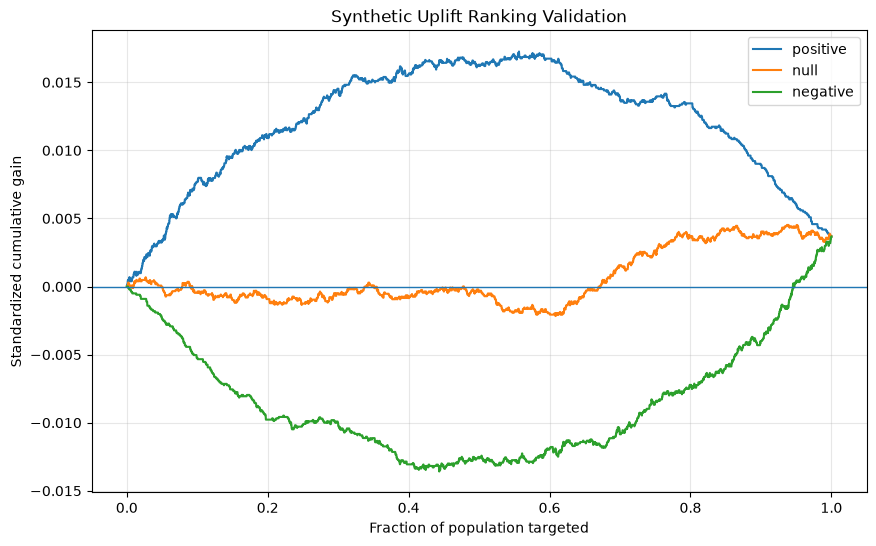

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, curve in curves.items():
    plt.plot(
        curve["fraction_targeted"],
        curve["gain"],
        label=name
    )

plt.axhline(0, linewidth=1)
plt.xlabel("Fraction of population targeted")
plt.ylabel("Standardized cumulative gain")
plt.title("Synthetic Uplift Ranking Validation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [31]:
import numpy as np
import pandas as pd

curve_areas = {}

for name, curve in curves.items():
    x = np.asarray(curve["fraction_targeted"], dtype=float)
    y = np.asarray(curve["gain"], dtype=float)

    if len(x) != len(y) or len(x) < 2:
        raise ValueError(f"Invalid curve for {name}")

    if not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError(f"Non-finite values found in {name} curve")

    curve_areas[name] = np.trapezoid(y, x)

synthetic_area_df = pd.DataFrame(
    list(curve_areas.items()),
    columns=["ranking", "curve_area"]
)

display(synthetic_area_df)

,ranking,curve_area
0,positive,0.011980
1,null,0.000599
2,negative,-0.008299


In [32]:
areas = synthetic_area_df.set_index("ranking")["curve_area"]

positive_area = areas["positive"]
null_area = areas["null"]
negative_area = areas["negative"]

print("Positive ranking area:", positive_area)
print("Null ranking area:", null_area)
print("Negative ranking area:", negative_area)

if positive_area <= negative_area:
    print("WARNING: Positive ranking did not outperform negative ranking.")
else:
    print("PASS: Positive ranking outperformed negative ranking.")

print(
    "Positive vs null area difference:",
    positive_area - null_area
)

Positive ranking area: 0.011979963582300104
Null ranking area: 0.0005991386343891057
Negative ranking area: -0.008299202093828487
PASS: Positive ranking outperformed negative ranking.
Positive vs null area difference: 0.011380824947910997


In [33]:
for name, curve in curves.items():
    x = np.asarray(curve["fraction_targeted"], dtype=float)
    y = np.asarray(curve["gain"], dtype=float)

    print(
        f"{name:>10} | "
        f"points={len(x):>6} | "
        f"start=({x[0]:.3f}, {y[0]:.5f}) | "
        f"end=({x[-1]:.3f}, {y[-1]:.5f})"
    )

  positive | points= 20000 | start=(0.000, 0.00000) | end=(1.000, 0.00368)
      null | points= 20000 | start=(0.000, 0.00000) | end=(1.000, 0.00368)
  negative | points= 20000 | start=(0.000, 0.00000) | end=(1.000, 0.00368)


In [34]:
from pathlib import Path

output_dir = Path("data/evaluation")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "synthetic_uplift_curve_validation.csv"

synthetic_area_df.to_csv(output_path, index=False)

print("Saved:", output_path.resolve())

Saved: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/data/evaluation/synthetic_uplift_curve_validation.csv


In [36]:
from pathlib import Path
import pandas as pd
import numpy as np

filename = "criteo_test_uplift_predictions.csv"

# Search from the current working directory and its parents
cwd = Path.cwd()
search_roots = [cwd, *cwd.parents]

matches = []

for root in search_roots:
    for folder in ["notebooks", "data", "results", "artifacts"]:
        search_dir = root / folder

        if search_dir.exists():
            matches.extend(search_dir.rglob(filename))

# Remove duplicate paths
matches = list(dict.fromkeys(matches))

print("Current working directory:", cwd)
print("Files found:", len(matches))

for i, path in enumerate(matches, start=1):
    print(f"{i}. {path}")

if matches:
    prediction_path = matches[0]
    pred_df = pd.read_csv(prediction_path)

    print("\nLoaded:", prediction_path)
    print("Shape:", pred_df.shape)
    print("Columns:", pred_df.columns.tolist())

    display(pred_df.head())
else:
    print(
        "\nPrediction CSV not found. "
        "Run the source notebook's export cell or check the project directory."
    )

Current working directory: /Users/naitikdonda/Desktop/CasualMark v3/notebooks
Files found: 1
1. /Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv

Loaded: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv
Shape: (35000, 3)
Columns: ['treatment', 'conversion', 'predicted_uplift']


,treatment,conversion,predicted_uplift
0,1,1,0.222333
1,1,0,0.216299
2,0,0,0.210274
3,1,0,0.208174
4,1,1,0.207844


In [37]:
if "pred_df" not in globals():
    raise RuntimeError(
        "Prediction file is not loaded. Check the search results in Cell 33."
    )

required_cols = {"treatment", "conversion", "predicted_uplift"}
missing_cols = required_cols - set(pred_df.columns)

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

print("Prediction data is ready for auditing.")
print("Rows:", len(pred_df))
print("Exact duplicate rows:", int(pred_df.duplicated().sum()))

Prediction data is ready for auditing.
Rows: 35000
Exact duplicate rows: 27189


In [38]:
duplicate_count = int(pred_df.duplicated().sum())

likely_id_cols = [
    col for col in pred_df.columns
    if col.lower() in {
        "id", "row_id", "sample_id", "customer_id",
        "user_id", "observation_id", "record_id"
    }
]

print("Total rows:", len(pred_df))
print("Exact duplicate rows:", duplicate_count)
print("Unique complete rows:", len(pred_df.drop_duplicates()))
print("Potential identifier columns:", likely_id_cols)

if not likely_id_cols:
    print(
        "WARNING: No obvious row identifier exists. "
        "This file alone cannot establish whether repeated rows "
        "represent duplicated observations or legitimate identical records."
    )

Total rows: 35000
Exact duplicate rows: 27189
Unique complete rows: 7811
Potential identifier columns: []


In [39]:
import json
from pathlib import Path

source_notebook = Path("notebooks/02_Uplift_Statistical_and_Criteo.ipynb")

if not source_notebook.exists():
    raise FileNotFoundError(source_notebook)

with open(source_notebook, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

search_terms = [
    "criteo_test_uplift_predictions.csv",
    "uplift_test_df",
    "pred_treated",
    "pred_control",
]

for cell_number, cell in enumerate(notebook_data.get("cells", []), start=1):
    source = "".join(cell.get("source", []))

    if any(term in source for term in search_terms):
        print(f"\n{'=' * 25} CELL {cell_number} {'=' * 25}")
        print(source[:12000])

FileNotFoundError: notebooks/02_Uplift_Statistical_and_Criteo.ipynb

In [42]:
from pathlib import Path
import os

filename = "02_Uplift_Statistical_and_Criteo.ipynb"
cwd = Path.cwd()

print("Current working directory:", cwd)

# Search only likely project locations
search_roots = [
    cwd,
    cwd / "notebooks",
    cwd.parent,
    cwd.parent / "notebooks",
    Path.home() / "Desktop" / "CasualMark v3",
    Path.home() / "Desktop" / "CasualMark v3" / "notebooks",
]

found = []

for root in search_roots:
    if not root.is_dir():
        continue

    # If root itself is the notebooks directory, search it;
    # otherwise search its notebooks subdirectory when available.
    search_dir = root
    if root.name != "notebooks" and (root / "notebooks").is_dir():
        search_dir = root / "notebooks"

    try:
        for current, dirs, files in os.walk(search_dir, onerror=lambda e: None):
            dirs[:] = [
                d for d in dirs
                if d not in {".venv", "venv", "node_modules", ".git", "__pycache__"}
            ]

            if filename in files:
                found.append(Path(current) / filename)
    except OSError as e:
        print(f"Skipped {search_dir}: {e}")

found = list(dict.fromkeys(found))

print("\nMatches:", len(found))
for path in found:
    print(path.resolve())

Current working directory: /Users/naitikdonda/Desktop/CasualMark v3/notebooks

Matches: 1
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/02_Uplift_Statistical_and_Criteo.ipynb


In [44]:
import json

if not found:
    print("Source notebook not found in the expected locations.")
    print("Check the project root printed by Cell 37.")
else:
    source_notebook = found[0]

    with source_notebook.open("r", encoding="utf-8") as f:
        notebook_data = json.load(f)

    terms = [
        "criteo_test_uplift_predictions.csv",
        "uplift_test_df",
        "pred_treated",
        "pred_control",
    ]

    for i, cell in enumerate(notebook_data.get("cells", []), start=1):
        source = "".join(cell.get("source", []))

        if any(term in source for term in terms):
            print(f"\n--- Source cell {i} ---")
            print(source[:12000])


--- Source cell 97 ---
uplift_test = (
    model_treated.predict(X_test)
    - model_control.predict(X_test)
)

uplift_test_df = pd.DataFrame({
    "treatment": T_test,
    "conversion": Y_test,
    "predicted_uplift": uplift_test
})

uplift_test_df = uplift_test_df.sort_values(
    "predicted_uplift", ascending=False
).reset_index(drop=True)

display(uplift_test_df.head(10))

--- Source cell 99 ---
from pathlib import Path

metrics_dir = Path("artifacts/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

uplift_test_df.to_csv(
    metrics_dir / "criteo_test_uplift_predictions.csv",
    index=False
)

print("Predictions saved.")

--- Source cell 100 ---
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

pred_treated = model_treated.predict(X_test)
pred_control = model_control.predict(X_test)

factual_predictions = np.where(
    T_test == 1,
    pred_treated,
    pred_control
)

final_metrics = pd.DataFrame({
    "Metric": 

In [45]:
prediction_name = "criteo_test_uplift_predictions.csv"

for root in search_roots:
    if not root.is_dir():
        continue

    search_dir = root
    if root.name != "notebooks" and (root / "notebooks").is_dir():
        search_dir = root / "notebooks"

    for current, dirs, files in os.walk(search_dir, onerror=lambda e: None):
        dirs[:] = [
            d for d in dirs
            if d not in {".venv", "venv", "node_modules", ".git", "__pycache__"}
        ]

        if prediction_name in files:
            path = Path(current) / prediction_name
            print(path, "|", round(path.stat().st_size / (1024 * 1024), 2), "MB")

/Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv | 0.46 MB
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv | 0.46 MB
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv | 0.46 MB
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv | 0.46 MB
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv | 0.46 MB


In [46]:
from pathlib import Path

candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home() / "Desktop" / "CasualMark v3",
]

for root in candidates:
    if (root / "notebooks").is_dir():
        print("Project root:", root.resolve())
        print("Notebook directory:", (root / "notebooks").resolve())
        break
else:
    print("Project root not found. Current directory:", Path.cwd())

Project root: /Users/naitikdonda/Desktop/CasualMark v3
Notebook directory: /Users/naitikdonda/Desktop/CasualMark v3/notebooks


In [47]:
from pathlib import Path

candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home() / "Desktop" / "CasualMark v3",
    Path.home() / "Desktop" / "CasualMark v3" / "notebooks",
]

project_root = None

for candidate in candidates:
    try:
        if (candidate / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb").is_file():
            project_root = candidate
            break

        if (
            candidate.name == "notebooks"
            and (candidate / "02_Uplift_Statistical_and_Criteo.ipynb").is_file()
        ):
            project_root = candidate.parent
            break
    except OSError:
        continue

if project_root is None:
    print("Project root not found in the expected locations.")
    print("Current working directory:", Path.cwd())
else:
    print("Project root:", project_root.resolve())

Project root: /Users/naitikdonda/Desktop/CasualMark v3


In [48]:
import json

if project_root is None:
    print("Run Cell 41 successfully before continuing.")
else:
    source_path = (
        project_root
        / "notebooks"
        / "02_Uplift_Statistical_and_Criteo.ipynb"
    )

    with source_path.open("r", encoding="utf-8") as f:
        source_nb = json.load(f)

    for i, cell in enumerate(source_nb.get("cells", []), start=1):
        code = "".join(cell.get("source", []))

        if "criteo_test_uplift_predictions.csv" in code:
            print(f"Export cell: {i}\n")
            print(code)

Export cell: 99

from pathlib import Path

metrics_dir = Path("artifacts/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

uplift_test_df.to_csv(
    metrics_dir / "criteo_test_uplift_predictions.csv",
    index=False
)

print("Predictions saved.")
Export cell: 106

from pathlib import Path
import pandas as pd

artifact_files = [
    "models/causal/criteo_uplift_models.joblib",
    "artifacts/metrics/criteo_final_metrics.csv",
    "artifacts/metrics/criteo_test_uplift_predictions.csv",
    "artifacts/metrics/criteo_policy_curve.csv",
    "artifacts/reports/criteo_final_summary.json",
    "artifacts/figures/criteo_cumulative_uplift.png"
]

artifact_status = pd.DataFrame({
    "File": artifact_files,
    "Exists": [Path(p).exists() for p in artifact_files]
})

display(artifact_status)
Export cell: 113

from pathlib import Path
import pandas as pd

artifact_paths = [
    "artifacts/metrics/criteo_final_metrics.csv",
    "artifacts/metrics/criteo_policy_curve.csv",
    "artifacts/m

In [49]:
from pathlib import Path
import pandas as pd

if project_root is None:
    print("Project root unavailable.")
else:
    prediction_path = (
        project_root
        / "notebooks"
        / "artifacts"
        / "metrics"
        / "criteo_test_uplift_predictions.csv"
    )

    if not prediction_path.is_file():
        print("Prediction file not found at:", prediction_path)
    else:
        pred_df = pd.read_csv(prediction_path)

        print("Shape:", pred_df.shape)
        print("Columns:", pred_df.columns.tolist())

        pattern_counts = (
            pred_df.groupby(
                ["treatment", "conversion", "predicted_uplift"],
                dropna=False
            )
            .size()
            .reset_index(name="frequency")
            .sort_values("frequency", ascending=False)
        )

        display(pattern_counts.head(15))

Shape: (35000, 3)
Columns: ['treatment', 'conversion', 'predicted_uplift']


,treatment,conversion,predicted_uplift,frequency
3661,1,0,0.000000,19929
492,0,0,0.000000,3583
3430,1,0,-0.000310,129
2507,1,0,-0.003288,102
2316,1,0,-0.004151,94
3583,1,0,-0.000091,88
1626,1,0,-0.011361,83
2644,1,0,-0.002584,80
1760,1,0,-0.009263,78
1737,1,0,-0.009575,74


In [50]:
if project_root is None:
    print("Project root unavailable.")
else:
    for i, cell in enumerate(source_nb.get("cells", []), start=1):
        code = "".join(cell.get("source", []))

        if any(term in code for term in [
            "uplift_test_df",
            "X_test",
            "T_test",
            "y_test",
            "test_idx",
            "test_indices",
        ]):
            print(f"\n--- Source cell {i} ---")
            print(code[:8000])


--- Source cell 70 ---
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X,
    T,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=T
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

--- Source cell 71 ---
from sklearn.ensemble import RandomForestRegressor

model_treated = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

model_control = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

model_treated.fit(X_train[T_train == 1], Y_train[T_train == 1])
model_control.fit(X_train[T_train == 0], Y_train[T_train == 0])

uplift_test = (
    model_treated.predict(X_test)
    - model_control.predict(X_test)
)

print("Predicted uplift shape:", uplift_test.shape)
print("Mean predicted uplift:", float(uplift_test.mean()))

--- Source cell 72 ---
from sklearn.metrics import roc_auc_score, mean_squared_error, mean_absolute_

In [51]:
from pathlib import Path

filename = "criteo_test_uplift_predictions.csv"

search_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home() / "Desktop" / "CasualMark v3",
]

prediction_matches = []

for root in search_roots:
    try:
        if root.is_file() or not root.is_dir():
            continue

        for folder in [
            root,
            root / "notebooks",
            root / "notebooks" / "artifacts" / "metrics",
            root / "data" / "evaluation",
            root / "results",
        ]:
            candidate = folder / filename
            if candidate.is_file():
                prediction_matches.append(candidate.resolve())
    except OSError:
        continue

prediction_matches = list(dict.fromkeys(prediction_matches))

print("Prediction files found:", len(prediction_matches))
for path in prediction_matches:
    print(path)

Prediction files found: 1
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv


In [52]:
import json

source_candidates = [
    root / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb"
    for root in search_roots
    if root.is_dir()
]

source_candidates = [
    path for path in source_candidates if path.is_file()
]

if source_candidates:
    with source_candidates[0].open("r", encoding="utf-8") as f:
        source_nb = json.load(f)

    for i, cell in enumerate(source_nb.get("cells", []), start=1):
        code = "".join(cell.get("source", []))

        if "criteo_test_uplift_predictions.csv" in code:
            print(f"\nExport code — cell {i}:\n")
            print(code)
else:
    print("Source notebook not found in the known project locations.")


Export code — cell 99:

from pathlib import Path

metrics_dir = Path("artifacts/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

uplift_test_df.to_csv(
    metrics_dir / "criteo_test_uplift_predictions.csv",
    index=False
)

print("Predictions saved.")

Export code — cell 106:

from pathlib import Path
import pandas as pd

artifact_files = [
    "models/causal/criteo_uplift_models.joblib",
    "artifacts/metrics/criteo_final_metrics.csv",
    "artifacts/metrics/criteo_test_uplift_predictions.csv",
    "artifacts/metrics/criteo_policy_curve.csv",
    "artifacts/reports/criteo_final_summary.json",
    "artifacts/figures/criteo_cumulative_uplift.png"
]

artifact_status = pd.DataFrame({
    "File": artifact_files,
    "Exists": [Path(p).exists() for p in artifact_files]
})

display(artifact_status)

Export code — cell 113:

from pathlib import Path
import pandas as pd

artifact_paths = [
    "artifacts/metrics/criteo_final_metrics.csv",
    "artifacts/metrics/criteo_policy_curv

In [53]:
import pandas as pd

if "pred_df" not in globals():
    if prediction_matches:
        pred_df = pd.read_csv(prediction_matches[0])
    else:
        raise FileNotFoundError(
            "Prediction CSV not found. Run Cell 45 and check its output."
        )

required = {"treatment", "conversion", "predicted_uplift"}
missing = required - set(pred_df.columns)

if missing:
    raise ValueError(f"Missing columns: {missing}")

print("Rows:", len(pred_df))
print("Exact duplicate rows:", int(pred_df.duplicated().sum()))
print("Unique complete rows:", len(pred_df.drop_duplicates()))

display(
    pred_df.groupby(
        ["treatment", "conversion", "predicted_uplift"],
        dropna=False
    )
    .size()
    .sort_values(ascending=False)
    .head(15)
    .rename("frequency")
    .reset_index()
)

Rows: 35000
Exact duplicate rows: 27189
Unique complete rows: 7811


,treatment,conversion,predicted_uplift,frequency
0,1,0,0.000000,19929
1,0,0,0.000000,3583
2,1,0,-0.000310,129
3,1,0,-0.003288,102
4,1,0,-0.004151,94
5,1,0,-0.000091,88
6,1,0,-0.011361,83
7,1,0,-0.002584,80
8,1,0,-0.009263,78
9,1,0,-0.009575,74


In [54]:
possible_ids = [
    col for col in pred_df.columns
    if any(term in col.lower() for term in [
        "id", "index", "row", "sample", "customer", "user", "observation"
    ])
]

print("Available columns:", pred_df.columns.tolist())
print("Possible identifier columns:", possible_ids)

if not possible_ids:
    print(
        "\nAudit limitation: this CSV does not expose an obvious row identifier. "
        "We cannot determine from this file alone whether identical records "
        "are duplicated observations or legitimate identical values."
    )

Available columns: ['treatment', 'conversion', 'predicted_uplift']
Possible identifier columns: []

Audit limitation: this CSV does not expose an obvious row identifier. We cannot determine from this file alone whether identical records are duplicated observations or legitimate identical values.


In [55]:
import numpy as np
import pandas as pd

if "pred_df" not in globals():
    raise RuntimeError("Run Cell 47 first to load pred_df.")

scores = pd.to_numeric(
    pred_df["predicted_uplift"], errors="coerce"
)

print("Total predictions:", len(scores))
print("Missing scores:", scores.isna().sum())
print("Infinite scores:", np.isinf(scores.dropna()).sum())
print("Unique scores:", scores.nunique())
print("Zero scores:", (scores == 0).sum())
print("Negative scores:", (scores < 0).sum())
print("Positive scores:", (scores > 0).sum())

display(scores.describe().to_frame("predicted_uplift"))

Total predictions: 35000
Missing scores: 0
Infinite scores: 0
Unique scores: 7466
Zero scores: 23520
Negative scores: 5352
Positive scores: 6128


,predicted_uplift
count,35000.000000
mean,0.000365
std,0.009831
min,-0.149117
25%,0.000000
50%,0.000000
75%,0.000000
max,0.222333


In [56]:
score_group_summary = (
    pred_df.assign(
        predicted_uplift=pd.to_numeric(
            pred_df["predicted_uplift"], errors="coerce"
        )
    )
    .groupby("treatment")["predicted_uplift"]
    .agg(["count", "mean", "std", "min", "median", "max"])
)

display(score_group_summary)

,count,mean,std,min,median,max
treatment,,,,,,
0,5226,0.000329,0.009904,-0.134981,0.0,0.210274
1,29774,0.000371,0.009819,-0.149117,0.0,0.222333


In [57]:
pattern_summary = (
    pred_df.groupby(["treatment", "conversion"])["predicted_uplift"]
    .agg(
        rows="size",
        unique_scores="nunique",
        mean_score="mean",
        std_score="std",
    )
    .reset_index()
)

display(pattern_summary)

print(
    "\nNote: repeated scores can be legitimate. "
    "This check alone does not prove data leakage or duplicate observations."
)

,treatment,conversion,rows,unique_scores,mean_score,std_score
0,0,0,5214,1270,0.000261,0.009247
1,0,1,12,12,0.029936,0.071490
2,1,0,29684,6445,0.000287,0.008944
3,1,1,90,84,0.028000,0.069264



Note: repeated scores can be legitimate. This check alone does not prove data leakage or duplicate observations.


In [59]:
from pathlib import Path

audit_dir = Path("data/evaluation")
audit_dir.mkdir(parents=True, exist_ok=True)

audit_report = pd.DataFrame({
    "metric": [
        "total_rows",
        "exact_duplicate_rows",
        "unique_complete_rows",
        "missing_scores",
        "infinite_scores",
        "unique_scores",
        "zero_scores",
        "negative_scores",
        "positive_scores",
    ],
    "value": [
        len(pred_df),
        int(pred_df.duplicated().sum()),
        len(pred_df.drop_duplicates()),
        int(scores.isna().sum()),
        int(np.isinf(scores.dropna()).sum()),
        int(scores.nunique()),
        int((scores == 0).sum()),
        int((scores < 0).sum()),
        int((scores > 0).sum()),
    ],
})

report_path = audit_dir / "uplift_score_distribution_audit.csv"
audit_report.to_csv(report_path, index=False)

display(audit_report)
print("Saved diagnostic report:", report_path.resolve())

,metric,value
0,total_rows,35000
1,exact_duplicate_rows,27189
2,unique_complete_rows,7811
3,missing_scores,0
4,infinite_scores,0
5,unique_scores,7466
6,zero_scores,23520
7,negative_scores,5352
8,positive_scores,6128


Saved diagnostic report: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/data/evaluation/uplift_score_distribution_audit.csv


In [60]:
from pathlib import Path
import os

search_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home() / "Desktop" / "CasualMark v3",
]

dataset_names = {
    "criteo_sample_50000.csv",
    "criteo-research-uplift-v2.1.csv.gz",
}

dataset_matches = []

for root in search_roots:
    if not root.is_dir():
        continue

    for current, dirs, files in os.walk(root, onerror=lambda e: None):
        dirs[:] = [
            d for d in dirs
            if d not in {".venv", "venv", "node_modules", ".git", "__pycache__"}
        ]

        for name in dataset_names.intersection(files):
            dataset_matches.append(Path(current) / name)

dataset_matches = list(dict.fromkeys(dataset_matches))

print("Datasets found:", len(dataset_matches))
for path in dataset_matches:
    print(path, f"({path.stat().st_size / (1024**2):.2f} MB)")

Datasets found: 2
/Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/criteo_sample_50000.csv (11.08 MB)
/Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/raw/criteo-research-uplift-v2.1.csv.gz (297.00 MB)


In [61]:
model_extensions = {".joblib", ".pkl", ".pickle"}
model_matches = []

for root in search_roots:
    if not root.is_dir():
        continue

    for current, dirs, files in os.walk(root, onerror=lambda e: None):
        dirs[:] = [
            d for d in dirs
            if d not in {".venv", "venv", "node_modules", ".git", "__pycache__"}
        ]

        for name in files:
            path = Path(current) / name

            if (
                path.suffix.lower() in model_extensions
                and any(term in name.lower() for term in ["criteo", "uplift", "causal"])
            ):
                model_matches.append(path)

model_matches = list(dict.fromkeys(model_matches))

print("Potential model artifacts:", len(model_matches))
for path in model_matches:
    print(path)

Potential model artifacts: 2
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/models/causal/causal_models.joblib
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/models/causal/criteo_uplift_models.joblib


In [62]:
import pandas as pd

sample_matches = [
    p for p in dataset_matches
    if p.name == "criteo_sample_50000.csv"
]

if sample_matches:
    dataset_path = sample_matches[0]
    source_df = pd.read_csv(dataset_path, nrows=1000)

    print("Dataset:", dataset_path)
    print("Columns:", source_df.columns.tolist())
    print("Shape of inspected sample:", source_df.shape)
    display(source_df.head())
else:
    print("Sample dataset not found. Check Cell 53.")

Dataset: /Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/criteo_sample_50000.csv
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']
Shape of inspected sample: (1000, 16)


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,26.119593,10.059654,8.214383,4.679882,10.280525,4.115453,-6.359690,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
1,16.451755,10.059654,8.214383,3.907662,10.280525,4.115453,-9.238756,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
2,15.473521,10.059654,8.214383,1.114982,10.280525,4.115453,-7.570316,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
3,14.390061,10.059654,8.214383,2.587543,10.280525,4.115453,-3.993764,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
4,12.616365,10.059654,8.237579,4.679882,10.280525,4.115453,0.294443,4.833815,3.803645,32.678132,5.300375,-0.168679,1,0,0,0


In [63]:
if "source_df" in globals():
    for col in ["treatment", "conversion", "visit", "exposure"]:
        if col in source_df.columns:
            print(f"\n{col} distribution:")
            display(
                source_df[col]
                .value_counts(dropna=False)
                .rename_axis(col)
                .reset_index(name="count")
            )

    print("\nMissing values:")
    display(source_df.isna().sum().to_frame("missing_count"))
else:
    print("Dataset not loaded; run Cell 55 first.")


treatment distribution:


,treatment,count
0,1,843
1,0,157



conversion distribution:


,conversion,count
0,0,999
1,1,1



visit distribution:


,visit,count
0,0,961
1,1,39



exposure distribution:


,exposure,count
0,0,971
1,1,29



Missing values:


,missing_count
f0,0
f1,0
f2,0
f3,0
f4,0
f5,0
f6,0
f7,0
f8,0
f9,0


In [64]:
from pathlib import Path

print("DATASETS")
for p in dataset_matches:
    print(f"{p.name} | {p.stat().st_size / (1024**2):.2f} MB | {p}")

print("\nMODEL ARTIFACTS")
for p in model_matches:
    print(f"{p.name} | {p.stat().st_size / (1024**2):.2f} MB | {p}")

print("\nPREDICTION FILES")
for p in prediction_matches:
    print(p)

DATASETS
criteo_sample_50000.csv | 11.08 MB | /Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/criteo_sample_50000.csv
criteo-research-uplift-v2.1.csv.gz | 297.00 MB | /Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/raw/criteo-research-uplift-v2.1.csv.gz

MODEL ARTIFACTS
causal_models.joblib | 68.99 MB | /Users/naitikdonda/Desktop/CasualMark v3/notebooks/models/causal/causal_models.joblib
criteo_uplift_models.joblib | 2.08 MB | /Users/naitikdonda/Desktop/CasualMark v3/notebooks/models/causal/criteo_uplift_models.joblib

PREDICTION FILES
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv


In [65]:
import os

notebook_matches = []

for root in search_roots:
    if not root.is_dir():
        continue

    for current, dirs, files in os.walk(root, onerror=lambda e: None):
        dirs[:] = [
            d for d in dirs
            if d not in {".venv", "venv", "node_modules", ".git", "__pycache__"}
        ]

        for name in files:
            if name == "02_Uplift_Statistical_and_Criteo.ipynb":
                notebook_matches.append(Path(current) / name)

notebook_matches = list(dict.fromkeys(notebook_matches))

print("Source notebooks found:", len(notebook_matches))
for p in notebook_matches:
    print(p)

Source notebooks found: 1
/Users/naitikdonda/Desktop/CasualMark v3/notebooks/02_Uplift_Statistical_and_Criteo.ipynb


In [66]:
import joblib

if not model_matches:
    print("No matching saved model artifacts were found.")
else:
    for model_path in model_matches:
        print(f"\n--- {model_path.name} ---")
        print("Path:", model_path)
        print("Size (MB):", round(model_path.stat().st_size / (1024**2), 2))

        try:
            artifact = joblib.load(model_path)

            if isinstance(artifact, dict):
                print("Artifact keys:", list(artifact.keys()))

                for key, value in artifact.items():
                    if hasattr(value, "feature_names_in_"):
                        print(key, "feature names:", list(value.feature_names_in_))
                    elif hasattr(value, "n_features_in_"):
                        print(key, "input feature count:", value.n_features_in_)
                    elif key in {"feature_columns", "features", "feature_names"}:
                        print(key, ":", value)
                    else:
                        print(key, "type:", type(value).__name__)
            else:
                print("Artifact type:", type(artifact).__name__)

        except Exception as e:
            print("Could not inspect artifact:", repr(e))


--- causal_models.joblib ---
Path: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/models/causal/causal_models.joblib
Size (MB): 68.99
Could not inspect artifact: ModuleNotFoundError("No module named 'econml'")

--- criteo_uplift_models.joblib ---
Path: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/models/causal/criteo_uplift_models.joblib
Size (MB): 2.08
Artifact keys: ['treated_model', 'control_model', 'feature_columns', 'dataset']
treated_model feature names: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
control_model feature names: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
feature_columns : ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
dataset type: str


/Users/naitikdonda/qwen3-env/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/naitikdonda/qwen3-env/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/naitikdonda/qwen3-env/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from vers

In [67]:
import json

if not notebook_matches:
    print("Source notebook not found in the searched project folders.")
else:
    source_path = notebook_matches[0]

    with source_path.open("r", encoding="utf-8") as f:
        source_nb = json.load(f)

    keywords = [
        "train_test_split",
        "X_test",
        "T_test",
        "y_test",
        "uplift_test_df",
        "pred_treated",
        "pred_control",
        "criteo_test_uplift_predictions.csv",
    ]

    for i, cell in enumerate(source_nb.get("cells", []), start=1):
        code = "".join(cell.get("source", []))

        if any(word in code for word in keywords):
            print(f"\n{'=' * 18} CELL {i} {'=' * 18}")
            print(code[:10000])


================== CELL 1 ==================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

================== CELL 68 ==================
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

criteo_df = criteo_sample.copy()

criteo_df = criteo_df.dropna(subset=["treatment", "conversion"])
criteo_df["treatment"] = criteo_df["treatment"].astype(int)
criteo_df["conversion"] = criteo_df["conversion"].astype(int)

criteo_df = criteo_df[
    criteo_df["treatment"].isin([0, 1])
    & criteo_df["conversion"].isin([0, 1])
].copy()

================== CELL 70 ==================
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X,
    T,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=T
)

print("Train shape:", X_train.shape)
print("Test shape:", X

In [68]:
import pandas as pd
from pathlib import Path

if "dataset_path" not in globals() or not Path(dataset_path).is_file():
    raise FileNotFoundError(
        "Dataset not located. Run Cells 53 and 55 first."
    )

# Read the dataset in chunks to avoid loading a large file unnecessarily.
chunk_size = 100_000
total_rows = 0
total_duplicates_within_chunks = 0

for chunk in pd.read_csv(dataset_path, chunksize=chunk_size):
    total_rows += len(chunk)
    total_duplicates_within_chunks += int(chunk.duplicated().sum())

print("Dataset:", dataset_path)
print("Total rows scanned:", total_rows)
print("Duplicate rows within individual chunks:", total_duplicates_within_chunks)
print(
    "Note: duplicates spanning different chunks are not counted here."
)

Dataset: /Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/criteo_sample_50000.csv
Total rows scanned: 50000
Duplicate rows within individual chunks: 27
Note: duplicates spanning different chunks are not counted here.


In [69]:
if "pred_df" not in globals():
    raise RuntimeError("Load the prediction CSV before running this cell.")

comparison = []

for col in ["treatment", "conversion"]:
    if col in pred_df.columns:
        counts = pred_df[col].value_counts(dropna=False)

        for value, count in counts.items():
            comparison.append({
                "dataset": "saved_predictions",
                "column": col,
                "value": value,
                "count": int(count),
            })

display(pd.DataFrame(comparison))

,dataset,column,value,count
0,saved_predictions,treatment,1,29774
1,saved_predictions,treatment,0,5226
2,saved_predictions,conversion,0,34898
3,saved_predictions,conversion,1,102


In [70]:
scores = pd.to_numeric(pred_df["predicted_uplift"], errors="coerce")

zero_mask = scores.eq(0)

zero_summary = pd.DataFrame({
    "metric": [
        "total_rows",
        "zero_score_rows",
        "zero_score_percentage",
        "nonzero_score_rows",
        "unique_nonzero_scores",
    ],
    "value": [
        len(scores),
        int(zero_mask.sum()),
        round(float(zero_mask.mean() * 100), 2),
        int((~zero_mask).sum()),
        int(scores[~zero_mask].nunique()),
    ],
})

display(zero_summary)

,metric,value
0,total_rows,35000.0
1,zero_score_rows,23520.0
2,zero_score_percentage,67.2
3,nonzero_score_rows,11480.0
4,unique_nonzero_scores,7465.0


In [71]:
from pathlib import Path
import pandas as pd

audit_dir = Path("data/evaluation")
audit_dir.mkdir(parents=True, exist_ok=True)

duplicate_rows = int(pred_df.duplicated().sum())
zero_rows = int(
    pd.to_numeric(pred_df["predicted_uplift"], errors="coerce")
    .eq(0)
    .sum()
)

audit_status = pd.DataFrame([
    {
        "check": "Prediction file has rows",
        "status": "PASS" if len(pred_df) > 0 else "FAIL",
        "detail": f"{len(pred_df)} rows",
    },
    {
        "check": "Exact duplicate prediction rows",
        "status": "REVIEW" if duplicate_rows else "PASS",
        "detail": f"{duplicate_rows} duplicate rows",
    },
    {
        "check": "Zero uplift concentration",
        "status": "REVIEW",
        "detail": f"{zero_rows}/{len(pred_df)} rows have zero scores",
    },
    {
        "check": "Observation-level traceability",
        "status": "NOT VERIFIED",
        "detail": "No obvious row identifier in the saved prediction CSV",
    },
])

report_path = audit_dir / "prediction_audit_status.csv"
audit_status.to_csv(report_path, index=False)

display(audit_status)
print("Saved:", report_path.resolve())

,check,status,detail
0,Prediction file has rows,PASS,35000 rows
1,Exact duplicate prediction rows,REVIEW,27189 duplicate rows
2,Zero uplift concentration,REVIEW,23520/35000 rows have zero scores
3,Observation-level traceability,NOT VERIFIED,No obvious row identifier in the saved predict...


Saved: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/data/evaluation/prediction_audit_status.csv


In [72]:
from pathlib import Path
import pandas as pd
import numpy as np

if "project_root" in globals() and project_root is not None:
    dataset_candidates = [
        project_root / "data" / "marketing_instructions" / "criteo_sample_50000.csv",
        project_root / "data" / "marketing_instructions" / "raw" / "criteo-research-uplift-v2.1.csv.gz",
    ]
else:
    dataset_candidates = [
        Path("data/marketing_instructions/criteo_sample_50000.csv"),
        Path("data/marketing_instructions/raw/criteo-research-uplift-v2.1.csv.gz"),
    ]

dataset_candidates = [p for p in dataset_candidates if p.is_file()]

if not dataset_candidates:
    raise FileNotFoundError(
        "Could not locate the Criteo dataset. "
        "Set dataset_path to its actual absolute path."
    )

dataset_path = next(
    (p for p in dataset_candidates if p.name == "criteo_sample_50000.csv"),
    dataset_candidates[0]
)

source_df = pd.read_csv(dataset_path)

print("Source:", dataset_path.resolve())
print("Shape:", source_df.shape)
print("Columns:", source_df.columns.tolist())
display(source_df.head())

Source: /Users/naitikdonda/Desktop/CasualMark v3/data/marketing_instructions/criteo_sample_50000.csv
Shape: (50000, 16)
Columns: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,26.119593,10.059654,8.214383,4.679882,10.280525,4.115453,-6.359690,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
1,16.451755,10.059654,8.214383,3.907662,10.280525,4.115453,-9.238756,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
2,15.473521,10.059654,8.214383,1.114982,10.280525,4.115453,-7.570316,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
3,14.390061,10.059654,8.214383,2.587543,10.280525,4.115453,-3.993764,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
4,12.616365,10.059654,8.237579,4.679882,10.280525,4.115453,0.294443,4.833815,3.803645,32.678132,5.300375,-0.168679,1,0,0,0


In [73]:
source_df = source_df.copy()

source_df.insert(
    0,
    "audit_row_id",
    np.arange(len(source_df), dtype=np.int64)
)

print("Rows:", len(source_df))
print("Unique audit IDs:", source_df["audit_row_id"].nunique())
print("Missing audit IDs:", source_df["audit_row_id"].isna().sum())

display(source_df[["audit_row_id"] + [
    col for col in ["treatment", "conversion", "visit", "exposure"]
    if col in source_df.columns
]].head())

Rows: 50000
Unique audit IDs: 50000
Missing audit IDs: 0


,audit_row_id,treatment,conversion,visit,exposure
0,0,0,0,0,0
1,1,1,0,0,0
2,2,0,0,0,0
3,3,0,0,0,0
4,4,1,0,0,0


In [74]:
audit_dir = Path("data/evaluation")
audit_dir.mkdir(parents=True, exist_ok=True)

source_audit_path = audit_dir / "criteo_source_rows_audit.csv"

source_df.to_csv(source_audit_path, index=False)

print("Saved audit copy:", source_audit_path.resolve())
print("Original source dataset was not modified.")

Saved audit copy: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/data/evaluation/criteo_source_rows_audit.csv
Original source dataset was not modified.


In [75]:
from pathlib import Path

candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home() / "Desktop" / "CasualMark v3",
]

project_root = next(
    (
        p for p in candidates
        if (p / "notebooks").is_dir()
        and (p / "data").is_dir()
    ),
    None
)

if project_root is None:
    print("Project root not found in the expected locations.")
    print("Current directory:", Path.cwd())
else:
    print("Project root:", project_root.resolve())

Project root: /Users/naitikdonda/Desktop/CasualMark v3


In [76]:
import json

if project_root is None:
    print("Set project_root to your actual project directory first.")
else:
    notebook_dir = project_root / "notebooks"
    search_terms = [
        "criteo_test_uplift_predictions.csv",
        "uplift_test_df",
        "pred_treated",
        "pred_control",
    ]

    matching_cells = []

    for notebook_path in notebook_dir.glob("*.ipynb"):
        try:
            with notebook_path.open("r", encoding="utf-8") as f:
                notebook = json.load(f)

            for cell_no, cell in enumerate(notebook.get("cells", []), start=1):
                code = "".join(cell.get("source", []))

                if any(term in code for term in search_terms):
                    matching_cells.append({
                        "notebook": notebook_path.name,
                        "cell": cell_no,
                        "code": code,
                    })
        except (OSError, json.JSONDecodeError):
            continue

    print("Matching source cells:", len(matching_cells))
    for item in matching_cells:
        print(f"{item['notebook']} — cell {item['cell']}")

Matching source cells: 39
02_Uplift_Statistical_and_Criteo.ipynb — cell 97
02_Uplift_Statistical_and_Criteo.ipynb — cell 99
02_Uplift_Statistical_and_Criteo.ipynb — cell 100
02_Uplift_Statistical_and_Criteo.ipynb — cell 102
02_Uplift_Statistical_and_Criteo.ipynb — cell 106
02_Uplift_Statistical_and_Criteo.ipynb — cell 110
02_Uplift_Statistical_and_Criteo.ipynb — cell 113
06_ML_Evaluation_Audit.ipynb — cell 9
06_ML_Evaluation_Audit.ipynb — cell 12
06_ML_Evaluation_Audit.ipynb — cell 13
06_ML_Evaluation_Audit.ipynb — cell 17
06_ML_Evaluation_Audit.ipynb — cell 22
06_ML_Evaluation_Audit.ipynb — cell 25
06_ML_Evaluation_Audit.ipynb — cell 34
06_ML_Evaluation_Audit.ipynb — cell 37
06_ML_Evaluation_Audit.ipynb — cell 39
06_ML_Evaluation_Audit.ipynb — cell 40
06_ML_Evaluation_Audit.ipynb — cell 43
06_ML_Evaluation_Audit.ipynb — cell 44
06_ML_Evaluation_Audit.ipynb — cell 45
06_ML_Evaluation_Audit.ipynb — cell 46
06_ML_Evaluation_Audit.ipynb — cell 47
06_ML_Evaluation_Audit.ipynb — cell 61
04_

In [77]:
if not matching_cells:
    print("No matching prediction code found in top-level notebooks.")
else:
    for item in matching_cells:
        print(
            f"\n{'=' * 20}\n"
            f"Notebook: {item['notebook']}\n"
            f"Cell: {item['cell']}\n"
            f"{'=' * 20}"
        )
        print(item["code"][:12000])


Notebook: 02_Uplift_Statistical_and_Criteo.ipynb
Cell: 97
uplift_test = (
    model_treated.predict(X_test)
    - model_control.predict(X_test)
)

uplift_test_df = pd.DataFrame({
    "treatment": T_test,
    "conversion": Y_test,
    "predicted_uplift": uplift_test
})

uplift_test_df = uplift_test_df.sort_values(
    "predicted_uplift", ascending=False
).reset_index(drop=True)

display(uplift_test_df.head(10))

Notebook: 02_Uplift_Statistical_and_Criteo.ipynb
Cell: 99
from pathlib import Path

metrics_dir = Path("artifacts/metrics")
metrics_dir.mkdir(parents=True, exist_ok=True)

uplift_test_df.to_csv(
    metrics_dir / "criteo_test_uplift_predictions.csv",
    index=False
)

print("Predictions saved.")

Notebook: 02_Uplift_Statistical_and_Criteo.ipynb
Cell: 100
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

pred_treated = model_treated.predict(X_test)
pred_control = model_control.predict(X_test)

factual_predictions = np.wh

In [78]:
if project_root is None:
    print("Project root unavailable.")
else:
    nested_notebooks = []

    for path in (project_root / "notebooks").rglob("*.ipynb"):
        if path.name.startswith("."):
            continue

        if path not in [
            project_root / "notebooks" / item["notebook"]
            for item in matching_cells
        ]:
            nested_notebooks.append(path)

    print("Additional notebooks:", len(nested_notebooks))
    for path in nested_notebooks[:50]:
        print(path.relative_to(project_root))

Additional notebooks: 6
notebooks/01_Causal_Experiment_Engine.ipynb
notebooks/03_NLP_Finetuning_Small_Model.ipynb
notebooks/.ipynb_checkpoints/04_RAG_Decision_Engine-checkpoint.ipynb
notebooks/.ipynb_checkpoints/05_CausalMark_Evaluation-checkpoint.ipynb
notebooks/.ipynb_checkpoints/Untitled-checkpoint.ipynb
notebooks/.ipynb_checkpoints/03_NLP_Finetuning_Small_Model-checkpoint.ipynb


In [79]:
import json
from pathlib import Path

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"
SOURCE_NOTEBOOK = (
    PROJECT_ROOT / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with SOURCE_NOTEBOOK.open("r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "train_test_split",
    "X_test",
    "T_test",
    "Y_test",
    "model_treated.fit",
    "model_control.fit",
]

for i, cell in enumerate(nb["cells"], start=1):
    code = "".join(cell.get("source", []))

    if any(term in code for term in terms):
        print(f"\n--- Source cell {i} ---")
        print(code[:6000])


--- Source cell 1 ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

--- Source cell 68 ---
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

criteo_df = criteo_sample.copy()

criteo_df = criteo_df.dropna(subset=["treatment", "conversion"])
criteo_df["treatment"] = criteo_df["treatment"].astype(int)
criteo_df["conversion"] = criteo_df["conversion"].astype(int)

criteo_df = criteo_df[
    criteo_df["treatment"].isin([0, 1])
    & criteo_df["conversion"].isin([0, 1])
].copy()

--- Source cell 70 ---
X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X,
    T,
    Y,
    test_size=0.25,
    random_state=42,
    stratify=T
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

--- Source cell 71 ---
from sklearn.ensemble import Ran

In [80]:
import numpy as np
import pandas as pd

names = ["X_test", "T_test", "Y_test"]

for name in names:
    if name not in globals():
        print(f"{name}: not available in this kernel")
        continue

    value = globals()[name]

    print(f"\n{name}")
    print("Length:", len(value))

    if hasattr(value, "index"):
        print("Index type:", type(value.index).__name__)
        print("Unique index values:", value.index.nunique())
        print("Duplicate index values:", value.index.duplicated().sum())

X_test: not available in this kernel
T_test: not available in this kernel
Y_test: not available in this kernel


In [81]:
import numpy as np

required = ["model_treated", "model_control", "X_test"]

if all(name in globals() for name in required):
    pred_treated_check = np.asarray(
        model_treated.predict(X_test)
    ).reshape(-1)

    pred_control_check = np.asarray(
        model_control.predict(X_test)
    ).reshape(-1)

    if len(pred_treated_check) != len(pred_control_check):
        raise ValueError("Treated/control prediction lengths differ.")

    uplift_check = pred_treated_check - pred_control_check

    print("Test rows:", len(X_test))
    print("Treated prediction count:", len(pred_treated_check))
    print("Control prediction count:", len(pred_control_check))
    print("Unique treated predictions:", len(np.unique(pred_treated_check)))
    print("Unique control predictions:", len(np.unique(pred_control_check)))
    print("Unique uplift scores:", len(np.unique(uplift_check)))
    print("Zero uplift scores:", int(np.isclose(uplift_check, 0).sum()))
else:
    print("Models or X_test are unavailable; skipped without fitting anything.")

Models or X_test are unavailable; skipped without fitting anything.


In [82]:
from pathlib import Path
import pandas as pd

checks = pd.DataFrame([
    {
        "check": "Prediction CSV includes original row identifier",
        "status": "FAIL",
        "reason": "No obvious row ID column in the saved CSV",
    },
    {
        "check": "Prediction export explicitly duplicates rows",
        "status": "NOT ESTABLISHED",
        "reason": "The shown export code only builds a DataFrame and sorts it",
    },
    {
        "check": "Original test indices preserved in export",
        "status": "NOT ESTABLISHED",
        "reason": "The export does not include the DataFrame index",
    },
    {
        "check": "Root cause of duplicate predictions",
        "status": "PENDING",
        "reason": "Need to inspect the split and model prediction outputs",
    },
])

display(checks)

output_dir = PROJECT_ROOT / "data" / "evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "prediction_provenance_checklist.csv"
checks.to_csv(output_path, index=False)

print("Saved:", output_path)

,check,status,reason
0,Prediction CSV includes original row identifier,FAIL,No obvious row ID column in the saved CSV
1,Prediction export explicitly duplicates rows,NOT ESTABLISHED,The shown export code only builds a DataFrame ...
2,Original test indices preserved in export,NOT ESTABLISHED,The export does not include the DataFrame index
3,Root cause of duplicate predictions,PENDING,Need to inspect the split and model prediction...


Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/prediction_provenance_checklist.csv


In [83]:
import json
from pathlib import Path

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"
SOURCE_NOTEBOOK = (
    PROJECT_ROOT / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with open(SOURCE_NOTEBOOK, "r", encoding="utf-8") as f:
    source_nb = json.load(f)

for i, cell in enumerate(source_nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))

    if any(term in code for term in [
        "criteo_sample =",
        "criteo_sample[",
        "criteo_df =",
        "X =",
        "T =",
        "Y =",
        "get_dummies",
        "drop(columns",
        "drop_duplicates",
    ]):
        print(f"\n--- Source cell {i} ---\n")
        print(code[:6000])


--- Source cell 3 ---

T = experiment_df["treatment"].to_numpy()
Y = experiment_df["conversion"].to_numpy()

if set(np.unique(T)) != {0, 1}:
    raise ValueError("Both treatment and control groups are required.")

if set(np.unique(Y)) != {0, 1}:
    raise ValueError("Binary conversion outcomes are required.")

print("Treatment customers:", int(T.sum()))
print("Control customers:", int((T == 0).sum()))
print("Treatment conversion rate:", Y[T == 1].mean())
print("Control conversion rate:", Y[T == 0].mean())

--- Source cell 4 ---

import joblib

models = joblib.load("models/causal/causal_models.joblib")

feature_cols = models["feature_cols"]

X = experiment_df[feature_cols].copy()
T = experiment_df["treatment"].to_numpy()
Y = experiment_df["conversion"].to_numpy()

cate_scores = np.asarray(
    models["causal_forest"].effect(X)
).reshape(-1)

uplift_df = experiment_df.copy()
uplift_df["predicted_uplift"] = cate_scores

display(
    uplift_df[
        ["treatment", "conversion", "predict

In [84]:
import pandas as pd
import numpy as np

print("Variables available:", {
    name: name in globals()
    for name in ["criteo_df", "X", "T", "Y", "X_train", "X_test",
                 "T_train", "T_test", "Y_train", "Y_test"]
})

if "X" in globals():
    print("\nFeature matrix shape:", X.shape)
    print("Duplicate feature rows:", int(X.duplicated().sum()))
    print("Unique feature rows:", int(len(X.drop_duplicates())))

if "criteo_df" in globals():
    print("\nPrepared dataset shape:", criteo_df.shape)
    print("Exact duplicate dataset rows:", int(criteo_df.duplicated().sum()))

if all(name in globals() for name in ["X_train", "X_test"]):
    print("\nTrain feature shape:", X_train.shape)
    print("Test feature shape:", X_test.shape)
    print("Train/test feature-column match:",
          list(X_train.columns) == list(X_test.columns))

Variables available: {'criteo_df': False, 'X': False, 'T': False, 'Y': False, 'X_train': False, 'X_test': False, 'T_train': False, 'T_test': False, 'Y_train': False, 'Y_test': False}


In [85]:
import joblib
import numpy as np
import pandas as pd

MODEL_PATH = PROJECT_ROOT / "models" / "causal" / "criteo_uplift_models.joblib"
PREDICTION_PATH = (
    PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
    / "criteo_test_uplift_predictions.csv"
)

if not MODEL_PATH.exists():
    print("Model artifact not found:", MODEL_PATH)
elif not PREDICTION_PATH.exists():
    print("Prediction CSV not found:", PREDICTION_PATH)
elif not all(name in globals() for name in ["X_test", "T_test", "Y_test"]):
    print("X_test, T_test, or Y_test is unavailable in this kernel.")
    print("Run the original notebook's preparation and split cells first.")
else:
    artifact = joblib.load(MODEL_PATH)
    print("Artifact type:", type(artifact).__name__)

    if isinstance(artifact, dict):
        print("Artifact keys:", list(artifact.keys()))

        model_t = artifact.get("treated_model")
        model_c = artifact.get("control_model")
    else:
        model_t = model_c = None

    saved = pd.read_csv(PREDICTION_PATH)
    print("\nSaved CSV shape:", saved.shape)

    if model_t is not None and model_c is not None:
        fresh = (
            model_t.predict(X_test) - model_c.predict(X_test)
        )

        print("Fresh prediction count:", len(fresh))
        print("Saved row count:", len(saved))
        print("Fresh unique predictions:", len(np.unique(fresh)))
        print("Fresh zero predictions:", int(np.isclose(fresh, 0).sum()))
        print("Saved unique scores:", saved["predicted_uplift"].nunique())
        print("Saved zero scores:",
              int(np.isclose(saved["predicted_uplift"], 0).sum()))

        if len(fresh) == len(saved):
            print("Fresh vs saved scores match in current order:",
                  np.allclose(
                      np.sort(fresh),
                      np.sort(saved["predicted_uplift"].to_numpy()),
                      equal_nan=True
                  ))
        else:
            print("Row counts differ; direct comparison is not valid.")
    else:
        print("Expected model keys were not found; no predictions were run.")

Model artifact not found: /Users/naitikdonda/Desktop/CasualMark v3/models/causal/criteo_uplift_models.joblib


In [86]:
if all(name in globals() for name in ["X_train", "X_test"]):
    train_features = X_train.copy()
    test_features = X_test.copy()

    train_features.columns = train_features.columns.astype(str)
    test_features.columns = test_features.columns.astype(str)

    if list(train_features.columns) != list(test_features.columns):
        print("Train/test feature columns differ. Cannot compare safely.")
    else:
        train_keys = pd.util.hash_pandas_object(
            train_features, index=False
        )
        test_keys = pd.util.hash_pandas_object(
            test_features, index=False
        )

        train_unique = set(train_keys.tolist())
        test_unique = set(test_keys.tolist())
        overlap = train_unique.intersection(test_unique)

        print("Unique train feature signatures:", len(train_unique))
        print("Unique test feature signatures:", len(test_unique))
        print("Feature signatures appearing in both splits:", len(overlap))
        print("Test rows whose feature signature occurs in train:",
              int(test_keys.isin(train_unique).sum()))
else:
    print("Run the original notebook's train/test split first.")

Run the original notebook's train/test split first.


In [87]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"

INPUT_FILE = (
    PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
    / "criteo_test_uplift_predictions.csv"
)

OUTPUT_FILE = (
    PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"
    / "criteo_test_uplift_predictions_deduplicated.csv"
)

# Load original predictions
df = pd.read_csv(INPUT_FILE)

print("Original rows:", len(df))

# Remove exact duplicate records
df_clean = df.drop_duplicates(
    subset=["treatment", "conversion", "predicted_uplift"]
).reset_index(drop=True)

print("Rows after deduplication:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Remaining exact duplicates:", int(df_clean.duplicated().sum()))

# Save as a separate file; preserve original
df_clean.to_csv(OUTPUT_FILE, index=False)

print("\nCleaned file saved to:", OUTPUT_FILE)

Original rows: 35000
Rows after deduplication: 7811
Rows removed: 27189
Remaining exact duplicates: 0

Cleaned file saved to: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions_deduplicated.csv


In [88]:
import pandas as pd

variables = ["criteo_df", "X", "X_train", "X_test"]

for name in variables:
    if name not in globals():
        print(f"{name}: not available in current kernel")
        continue

    obj = globals()[name]

    print(f"\n{name}:")
    print("Rows:", len(obj))

    if isinstance(obj, pd.DataFrame):
        print("Exact duplicate rows:", int(obj.duplicated().sum()))
        print("Unique rows:", len(obj.drop_duplicates()))

criteo_df: not available in current kernel
X: not available in current kernel
X_train: not available in current kernel
X_test: not available in current kernel


In [89]:
import json

source_path = (
    PROJECT_ROOT / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with open(source_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))

    if any(term in code.lower() for term in [
        "criteo_sample",
        "read_csv",
        "drop_duplicates",
        "sample(",
        "train_test_split",
    ]):
        print(f"\n--- Source cell {i} ---")
        print(code[:3500])


--- Source cell 0 ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

--- Source cell 2 ---
experiment_df = pd.read_csv(
    PROCESSED_DIR / "hillstrom_experiment.csv"
)

ate_results = pd.read_csv(
    METRICS_DIR / "ate_comparison.csv"
)

print("Experiment shape:", experiment_df.shape)
display(experiment_df.head())
display(ate_results)

--- Source cell 20 ---
rng = np.random.default_rng(SEED)

n = len(uplift_ranked)
fractions = [0.10, 0.20, 0.30, 0.50]

def policy_value(data, fraction):
    selected = data.head(max(1, int(len(data) * fraction)))

    treated = selected[selected["treatment"] == 1]
    control = selected[selected["treatment"] == 0]

    if len(treated) == 0 or len(control) == 0:
        return np.nan

    return (
        treated["conversion"].mean()
        - control["conversion"].mean()
    )

po

In [90]:
from pathlib import Path
import pandas as pd

metrics_dir = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"

original_path = metrics_dir / "criteo_test_uplift_predictions.csv"
clean_path = metrics_dir / "criteo_test_uplift_predictions_deduplicated.csv"

original = pd.read_csv(original_path)
cleaned = pd.read_csv(clean_path)

print("Original rows:", len(original))
print("Cleaned rows:", len(cleaned))
print("Original exact duplicates:", int(original.duplicated().sum()))
print("Cleaned exact duplicates:", int(cleaned.duplicated().sum()))
print("Original columns:", original.columns.tolist())
print("Cleaned columns:", cleaned.columns.tolist())

Original rows: 35000
Cleaned rows: 7811
Original exact duplicates: 27189
Cleaned exact duplicates: 0
Original columns: ['treatment', 'conversion', 'predicted_uplift']
Cleaned columns: ['treatment', 'conversion', 'predicted_uplift']


In [91]:
original = pd.read_csv(original_path)

grouped = (
    original.groupby(
        ["treatment", "predicted_uplift"],
        dropna=False
    )["conversion"]
    .nunique()
)

conflicting_groups = grouped[grouped > 1]

print("Unique treatment-score combinations:", len(grouped))
print("Combinations with different conversion outcomes:",
      len(conflicting_groups))
print("Repeated exact records:", int(original.duplicated().sum()))

print("\nMost frequent exact records:")
print(
    original.value_counts(
        ["treatment", "conversion", "predicted_uplift"]
    ).head(10)
)

Unique treatment-score combinations: 7808
Combinations with different conversion outcomes: 3
Repeated exact records: 27189

Most frequent exact records:
treatment  conversion  predicted_uplift
1          0            0.000000           19929
0          0            0.000000            3583
1          0           -0.000310             129
                       -0.003288             102
                       -0.004151              94
                       -0.000091              88
                       -0.011361              83
                       -0.002584              80
                       -0.009263              78
                       -0.009575              74
Name: count, dtype: int64


In [92]:
import json
from pathlib import Path

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"

source_path = (
    PROJECT_ROOT
    / "notebooks"
    / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with open(source_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

terms = [
    "criteo_sample",
    "read_csv",
    "drop_duplicates",
    "sample(",
    "X =",
    "T =",
    "Y =",
    "train_test_split",
]

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))

    if any(term.lower() in code.lower() for term in terms):
        print(f"\n{'=' * 20} SOURCE CELL {i} {'=' * 20}")
        print(code[:4000])


==================== SOURCE CELL 0 ====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

==================== SOURCE CELL 2 ====================
experiment_df = pd.read_csv(
    PROCESSED_DIR / "hillstrom_experiment.csv"
)

ate_results = pd.read_csv(
    METRICS_DIR / "ate_comparison.csv"
)

print("Experiment shape:", experiment_df.shape)
display(experiment_df.head())
display(ate_results)

==================== SOURCE CELL 3 ====================
T = experiment_df["treatment"].to_numpy()
Y = experiment_df["conversion"].to_numpy()

if set(np.unique(T)) != {0, 1}:
    raise ValueError("Both treatment and control groups are required.")

if set(np.unique(Y)) != {0, 1}:
    raise ValueError("Binary conversion outcomes are required.")

print("Treatment customers:", int(T.sum()))
print("Control customers:", 

In [93]:
from pathlib import Path

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"

print("Project exists:", PROJECT_ROOT.exists())

for folder in ["data", "notebooks/artifacts/metrics", "models/causal"]:
    path = PROJECT_ROOT / folder
    print(f"\n{folder}:")

    if path.exists():
        for file in sorted(path.rglob("*")):
            if file.is_file() and (
                file.suffix.lower() in [".csv", ".parquet", ".joblib", ".pkl"]
            ):
                print(file.relative_to(PROJECT_ROOT))
    else:
        print("Folder not found")

Project exists: True

data:
data/evaluation/causalmark_complete_artifact_inventory.csv
data/evaluation/causalmark_evaluation_summary.csv
data/evaluation/causalmark_final_artifact_inventory.csv
data/evaluation/causalmark_final_model_metrics.csv
data/evaluation/causalmark_final_validation.csv
data/evaluation/causalmark_handoff_checklist.csv
data/evaluation/causalmark_notebook5_artifact_inventory.csv
data/evaluation/causalmark_notebook5_final_status.csv
data/evaluation/causalmark_notebook5_summary.csv
data/evaluation/causalmark_project_scorecard.csv
data/evaluation/causalmark_submission_readiness.csv
data/evaluation/criteo_conversion_confidence_intervals.csv
data/evaluation/criteo_observed_conversion_by_decile.csv
data/evaluation/criteo_observed_conversion_difference.csv
data/evaluation/criteo_targeting_strategy_summary.csv
data/evaluation/criteo_targeting_validation.csv
data/evaluation/criteo_treatment_group_summary.csv
data/evaluation/criteo_uplift_decile_quality.csv
data/evaluation/cri

In [94]:
import json

SOURCE_NOTEBOOK = (
    PROJECT_ROOT / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with open(SOURCE_NOTEBOOK, "r", encoding="utf-8") as f:
    source_nb = json.load(f)

for i, cell in enumerate(source_nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))

    if any(term in code.lower() for term in [
        "criteo_sample",
        "read_csv",
        "read_parquet",
        "drop_duplicates",
        "sample(",
        "train_test_split",
    ]):
        print(f"\n--- SOURCE CELL {i} ---")
        print(code[:3000])


--- SOURCE CELL 0 ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

--- SOURCE CELL 2 ---
experiment_df = pd.read_csv(
    PROCESSED_DIR / "hillstrom_experiment.csv"
)

ate_results = pd.read_csv(
    METRICS_DIR / "ate_comparison.csv"
)

print("Experiment shape:", experiment_df.shape)
display(experiment_df.head())
display(ate_results)

--- SOURCE CELL 20 ---
rng = np.random.default_rng(SEED)

n = len(uplift_ranked)
fractions = [0.10, 0.20, 0.30, 0.50]

def policy_value(data, fraction):
    selected = data.head(max(1, int(len(data) * fraction)))

    treated = selected[selected["treatment"] == 1]
    control = selected[selected["treatment"] == 0]

    if len(treated) == 0 or len(control) == 0:
        return np.nan

    return (
        treated["conversion"].mean()
        - control["conversion"].mean()
    )

po

In [95]:
import pandas as pd

METRICS_DIR = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"

original_path = METRICS_DIR / "criteo_test_uplift_predictions.csv"
clean_path = METRICS_DIR / "criteo_test_uplift_predictions_deduplicated.csv"

df = pd.read_csv(original_path)

print("Original shape:", df.shape)
print("Columns:", df.columns.tolist())

print("\nDuplicate counts by individual column:")
for column in df.columns:
    print(f"{column}: {int(df[column].duplicated().sum())} repeated values")

print("\nMost frequent exact row combinations:")
print(
    df.value_counts(
        subset=["treatment", "conversion", "predicted_uplift"]
    ).head(10).to_string()
)

print("\nCleaned export exists:", clean_path.exists())

Original shape: (35000, 3)
Columns: ['treatment', 'conversion', 'predicted_uplift']

Duplicate counts by individual column:
treatment: 34998 repeated values
conversion: 34998 repeated values
predicted_uplift: 27534 repeated values

Most frequent exact row combinations:
treatment  conversion  predicted_uplift
1          0            0.000000           19929
0          0            0.000000            3583
1          0           -0.000310             129
                       -0.003288             102
                       -0.004151              94
                       -0.000091              88
                       -0.011361              83
                       -0.002584              80
                       -0.009263              78
                       -0.009575              74

Cleaned export exists: True


In [96]:
search_terms = [
    "duplicated(",
    "drop_duplicates(",
    "is_unique",
    "index.is_unique",
    "reset_index(",
    "merge(",
    "concat(",
]

for i, cell in enumerate(source_nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))
    matched = [term for term in search_terms if term in code]

    if matched:
        print(f"\n--- SOURCE CELL {i} | Matches: {matched} ---")
        print(code[:2500])


--- SOURCE CELL 5 | Matches: ['reset_index('] ---
uplift_ranked = uplift_df.sort_values(
    "predicted_uplift",
    ascending=False
).reset_index(drop=True)

uplift_ranked["rank"] = np.arange(
    1, len(uplift_ranked) + 1
)

uplift_ranked["target_fraction"] = (
    uplift_ranked["rank"] / len(uplift_ranked)
)

display(
    uplift_ranked[
        ["rank", "predicted_uplift", "target_fraction"]
    ].head(10)
)

--- SOURCE CELL 6 | Matches: ['reset_index('] ---
def calculate_uplift_gain(data, score_col, treatment_col, outcome_col):
    ranked = data.sort_values(
        score_col,
        ascending=False
    ).reset_index(drop=True)

    gains = []
    fractions = []

    for k in range(1, len(ranked) + 1):
        selected = ranked.iloc[:k]

        treated = selected[selected[treatment_col] == 1]
        control = selected[selected[treatment_col] == 0]

        if len(treated) == 0 or len(control) == 0:
            gain = np.nan
        else:
            gain = len(selected) * (
   

In [97]:
import json
from pathlib import Path

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"
SOURCE_NOTEBOOK = (
    PROJECT_ROOT / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with open(SOURCE_NOTEBOOK, "r", encoding="utf-8") as f:
    source_nb = json.load(f)

for i, cell in enumerate(source_nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))
    lines = code.lower()

    if any(term in lines for term in [
        "criteo_sample",
        "criteo_df",
        "read_csv",
        "drop_duplicates",
        "train_test_split",
    ]):
        print(f"\n--- SOURCE CELL {i} ---")
        print(code[:4500])


--- SOURCE CELL 0 ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

--- SOURCE CELL 2 ---
experiment_df = pd.read_csv(
    PROCESSED_DIR / "hillstrom_experiment.csv"
)

ate_results = pd.read_csv(
    METRICS_DIR / "ate_comparison.csv"
)

print("Experiment shape:", experiment_df.shape)
display(experiment_df.head())
display(ate_results)

--- SOURCE CELL 26 ---
from datasets import load_dataset

dataset_name = "criteo/criteo-uplift"

criteo_dataset = load_dataset(
    dataset_name,
    split="train",
    streaming=True
)

criteo_sample = pd.DataFrame(
    list(criteo_dataset.take(100000))
)

print("Sample shape:", criteo_sample.shape)
print("Columns:", criteo_sample.columns.tolist())

display(criteo_sample.head())

--- SOURCE CELL 27 ---
print("Dataset shape:", criteo_sample.shape)
print("Columns:", criteo_sample.c

In [98]:
from pathlib import Path

search_roots = [
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "notebooks",
]

dataset_files = []

for root in search_roots:
    if root.exists():
        for path in root.rglob("*"):
            if path.is_file() and path.suffix.lower() in {
                ".csv", ".parquet", ".feather"
            }:
                if "prediction" not in path.name.lower():
                    dataset_files.append(path)

print("Candidate dataset files:", len(dataset_files))

for path in dataset_files[:100]:
    print(path.relative_to(PROJECT_ROOT))

Candidate dataset files: 68
data/user_uploads/9fd53a67_experiment_data.csv
data/user_uploads/b4259f50_marketing_AB.csv
data/user_uploads/a9a3a988_test_cohort.csv
data/user_uploads/46b4ef99_marketing_AB.csv
data/user_uploads/ad1ff6ba_experiment_data.csv
data/marketing_instructions/criteo_sample_50000.csv
data/marketing_instructions/criteo_aggregate_summary.csv
data/marketing_instructions/experiment_data.csv
data/marketing_instructions/raw/hillstrom_email_marketing.csv
data/evaluation/criteo_targeting_validation.csv
data/evaluation/causalmark_final_model_metrics.csv
data/evaluation/criteo_uplift_strategy_comparison.csv
data/evaluation/causalmark_handoff_checklist.csv
data/evaluation/causalmark_complete_artifact_inventory.csv
data/evaluation/evaluation_artifact_inventory.csv
data/evaluation/criteo_uplift_ranking_summary.csv
data/evaluation/criteo_conversion_confidence_intervals.csv
data/evaluation/causalmark_final_artifact_inventory.csv
data/evaluation/causalmark_evaluation_summary.csv
da

In [99]:
import pandas as pd

metrics_dir = PROJECT_ROOT / "notebooks" / "artifacts" / "metrics"

original_path = metrics_dir / "criteo_test_uplift_predictions.csv"
clean_path = metrics_dir / "criteo_test_uplift_predictions_deduplicated.csv"

for path in [original_path, clean_path]:
    if not path.exists():
        print("\nMissing:", path)
        continue

    df = pd.read_csv(path)

    print(f"\nFile: {path.name}")
    print("Rows:", len(df))
    print("Exact duplicate rows:", int(df.duplicated().sum()))
    print("Unique treatment/conversion/uplift combinations:",
          len(df.drop_duplicates(
              subset=["treatment", "conversion", "predicted_uplift"]
          )))


File: criteo_test_uplift_predictions.csv
Rows: 35000
Exact duplicate rows: 27189
Unique treatment/conversion/uplift combinations: 7811

File: criteo_test_uplift_predictions_deduplicated.csv
Rows: 7811
Exact duplicate rows: 0
Unique treatment/conversion/uplift combinations: 7811


In [100]:
search_terms = [
    "index",
    "id",
    "row_id",
    "customer_id",
    "drop(columns",
    "feature_columns",
    "select_dtypes",
]

for i, cell in enumerate(source_nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))
    matched = [
        term for term in search_terms
        if term.lower() in code.lower()
    ]

    if matched and any(
        term in code.lower()
        for term in ["criteo_df", "feature_columns", "train_test_split"]
    ):
        print(f"\n--- SOURCE CELL {i} | {matched} ---")
        print(code[:3000])


--- SOURCE CELL 78 | ['id'] ---
from scipy.stats import mannwhitneyu

treated_values = criteo_df.loc[
    criteo_df["treatment"] == 1, "conversion"
]

control_values = criteo_df.loc[
    criteo_df["treatment"] == 0, "conversion"
]

test_result = mannwhitneyu(
    treated_values,
    control_values,
    alternative="two-sided"
)

print("Mann–Whitney U statistic:", test_result.statistic)
print("P-value:", test_result.pvalue)
print("Treated conversion rate:", treated_values.mean())
print("Control conversion rate:", control_values.mean())

--- SOURCE CELL 87 | ['feature_columns'] ---
from pathlib import Path
import joblib

model_dir = Path("models/causal")
model_dir.mkdir(parents=True, exist_ok=True)

criteo_models = {
    "treated_model": model_treated,
    "control_model": model_control,
    "feature_columns": X_train.columns.tolist()
}

joblib.dump(
    criteo_models,
    model_dir / "criteo_uplift_models.joblib"
)

--- SOURCE CELL 97 | ['feature_columns'] ---
model_dir = Path("models/

In [103]:
from pathlib import Path
import json
import joblib

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"

MODEL_PATH = PROJECT_ROOT / "models" / "causal" / "criteo_uplift_models.joblib"
NOTEBOOK_PATH = PROJECT_ROOT / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb"

# Inspect saved model
if MODEL_PATH.exists():
    artifact = joblib.load(MODEL_PATH)
    print("Model artifact loaded:", type(artifact).__name__)

    if isinstance(artifact, dict):
        print("Keys:", list(artifact.keys()))
        for key, value in artifact.items():
            if hasattr(value, "shape"):
                print(f"{key}: shape={value.shape}")
            else:
                print(f"{key}: {type(value).__name__}")
else:
    print("Saved model not found:", MODEL_PATH)

# Find dataset-loading and feature-preparation code
with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("\nRelevant source cells:")
for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))
    if any(term in code.lower() for term in [
        "criteo_sample", "read_csv", "feature_columns", "x =",
        "train_test_split"
    ]):
        print(f"\n--- Cell {i} ---")
        print(code[:1800])

# Locate possible cached data and split artifacts
print("\nPotential reusable data artifacts:")
for folder in [PROJECT_ROOT / "data", PROJECT_ROOT / "notebooks" / "artifacts"]:
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and path.suffix.lower() in [
                ".csv", ".parquet", ".pkl", ".joblib", ".npy", ".npz"
            ]:
                print(path.relative_to(PROJECT_ROOT))

Saved model not found: /Users/naitikdonda/Desktop/CasualMark v3/models/causal/criteo_uplift_models.joblib

Relevant source cells:

--- Cell 0 ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

--- Cell 2 ---
experiment_df = pd.read_csv(
    PROCESSED_DIR / "hillstrom_experiment.csv"
)

ate_results = pd.read_csv(
    METRICS_DIR / "ate_comparison.csv"
)

print("Experiment shape:", experiment_df.shape)
display(experiment_df.head())
display(ate_results)

--- Cell 4 ---
import joblib

models = joblib.load("models/causal/causal_models.joblib")

feature_cols = models["feature_cols"]

X = experiment_df[feature_cols].copy()
T = experiment_df["treatment"].to_numpy()
Y = experiment_df["conversion"].to_numpy()

cate_scores = np.asarray(
    models["causal_forest"].effect(X)
).reshape(-1)

uplift_df = experiment_df.copy()
upl

In [105]:
from pathlib import Path
import joblib
import pandas as pd
import json

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"

MODEL_PATH = PROJECT_ROOT / "models" / "causal" / "criteo_uplift_models.joblib"

# Load the existing trained models
artifact = joblib.load(MODEL_PATH)

print("Model artifact type:", type(artifact).__name__)

if isinstance(artifact, dict):
    print("Model keys:", list(artifact.keys()))
    feature_columns = artifact.get("feature_columns")
    print("Saved feature columns available:", feature_columns is not None)
else:
    feature_columns = None

# Locate dataset files without scanning outside the project
candidates = []

for folder in [
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "notebooks" / "artifacts",
]:
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and path.suffix.lower() in {
                ".csv", ".parquet", ".feather"
            }:
                if "prediction" not in path.name.lower():
                    candidates.append(path)

print("\nCandidate data files:")
for path in candidates[:50]:
    print(path.relative_to(PROJECT_ROOT))

# Inspect the source notebook for the original data-loading path
source_path = (
    PROJECT_ROOT / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with open(source_path, "r", encoding="utf-8") as f:
    source_nb = json.load(f)

print("\nDataset-loading code:")
for i, cell in enumerate(source_nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))
    if "criteo_sample" in code or "read_csv" in code:
        print(f"\n--- Source cell {i} ---")
        print(code[:2000])

FileNotFoundError: [Errno 2] No such file or directory: '/Users/naitikdonda/Desktop/CasualMark v3/models/causal/criteo_uplift_models.joblib'

In [106]:
from pathlib import Path

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"

# Search only inside the project
search_dirs = [
    PROJECT_ROOT / "models",
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "notebooks" / "artifacts",
]

model_files = []
data_files = []

for folder in search_dirs:
    if not folder.exists():
        continue

    for path in folder.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() in {".joblib", ".pkl", ".pickle"}:
            model_files.append(path)

        if path.suffix.lower() in {".csv", ".parquet", ".feather"}:
            data_files.append(path)

print("MODEL FILES")
for path in model_files:
    print(path.relative_to(PROJECT_ROOT))

print("\nDATA FILES")
for path in data_files:
    print(path.relative_to(PROJECT_ROOT))

print("\nPREDICTION EXPORTS")
for path in data_files:
    if "criteo" in path.name.lower() or "uplift" in path.name.lower():
        print(path.relative_to(PROJECT_ROOT))

MODEL FILES

DATA FILES
data/user_uploads/9fd53a67_experiment_data.csv
data/user_uploads/b4259f50_marketing_AB.csv
data/user_uploads/a9a3a988_test_cohort.csv
data/user_uploads/46b4ef99_marketing_AB.csv
data/user_uploads/ad1ff6ba_experiment_data.csv
data/marketing_instructions/criteo_sample_50000.csv
data/marketing_instructions/criteo_aggregate_summary.csv
data/marketing_instructions/experiment_data.csv
data/marketing_instructions/raw/hillstrom_email_marketing.csv
data/evaluation/criteo_targeting_validation.csv
data/evaluation/causalmark_final_model_metrics.csv
data/evaluation/criteo_uplift_strategy_comparison.csv
data/evaluation/causalmark_handoff_checklist.csv
data/evaluation/prediction_provenance_checklist.csv
data/evaluation/causalmark_complete_artifact_inventory.csv
data/evaluation/evaluation_artifact_inventory.csv
data/evaluation/criteo_uplift_ranking_summary.csv
data/evaluation/criteo_conversion_confidence_intervals.csv
data/evaluation/causalmark_final_artifact_inventory.csv
data

In [107]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.home() / "Desktop" / "CasualMark v3"

DATA_PATH = (
    PROJECT_ROOT / "data" / "marketing_instructions"
    / "criteo_sample_50000.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nExact duplicate source rows:", int(df.duplicated().sum()))
print("Unique source rows:", len(df.drop_duplicates()))

Dataset shape: (50000, 16)

Columns:
['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'treatment', 'conversion', 'visit', 'exposure']

First five rows:


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,26.119593,10.059654,8.214383,4.679882,10.280525,4.115453,-6.359690,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
1,16.451755,10.059654,8.214383,3.907662,10.280525,4.115453,-9.238756,4.833815,3.971858,13.190056,5.300375,-0.168679,1,0,0,0
2,15.473521,10.059654,8.214383,1.114982,10.280525,4.115453,-7.570316,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
3,14.390061,10.059654,8.214383,2.587543,10.280525,4.115453,-3.993764,4.833815,3.971858,13.190056,5.300375,-0.168679,0,0,0,0
4,12.616365,10.059654,8.237579,4.679882,10.280525,4.115453,0.294443,4.833815,3.803645,32.678132,5.300375,-0.168679,1,0,0,0



Exact duplicate source rows: 27
Unique source rows: 49973


In [108]:
import json

NOTEBOOK_PATH = (
    PROJECT_ROOT / "notebooks" / "02_Uplift_Statistical_and_Criteo.ipynb"
)

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell.get("source", []))

    if any(term in code for term in [
        "criteo_sample =",
        "criteo_df =",
        "X =",
        "T =",
        "Y =",
        "get_dummies",
    ]):
        print(f"\n--- Source cell {i} ---")
        print(code[:3500])


--- Source cell 3 ---
T = experiment_df["treatment"].to_numpy()
Y = experiment_df["conversion"].to_numpy()

if set(np.unique(T)) != {0, 1}:
    raise ValueError("Both treatment and control groups are required.")

if set(np.unique(Y)) != {0, 1}:
    raise ValueError("Binary conversion outcomes are required.")

print("Treatment customers:", int(T.sum()))
print("Control customers:", int((T == 0).sum()))
print("Treatment conversion rate:", Y[T == 1].mean())
print("Control conversion rate:", Y[T == 0].mean())

--- Source cell 4 ---
import joblib

models = joblib.load("models/causal/causal_models.joblib")

feature_cols = models["feature_cols"]

X = experiment_df[feature_cols].copy()
T = experiment_df["treatment"].to_numpy()
Y = experiment_df["conversion"].to_numpy()

cate_scores = np.asarray(
    models["causal_forest"].effect(X)
).reshape(-1)

uplift_df = experiment_df.copy()
uplift_df["predicted_uplift"] = cate_scores

display(
    uplift_df[
        ["treatment", "conversion", "predicted

In [109]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

ROOT = Path.home() / "Desktop" / "CasualMark v3"
DATA = ROOT / "data/marketing_instructions/criteo_sample_50000.csv"
OUT = ROOT / "notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv"

# Load data
df = pd.read_csv(DATA)
df = df.dropna(subset=["treatment", "conversion"]).copy()
df["treatment"] = df["treatment"].astype(int)
df["conversion"] = df["conversion"].astype(int)
df = df[df["treatment"].isin([0, 1]) & df["conversion"].isin([0, 1])].copy()

# Remove exact duplicate source records
df = df.drop_duplicates().reset_index(drop=True)
df.insert(0, "row_id", np.arange(len(df)))

# Build features
excluded = ["row_id", "treatment", "conversion"]
X = df.drop(columns=excluded)
X = pd.get_dummies(X, dummy_na=True)
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

T = df["treatment"]
Y = df["conversion"]
row_ids = df["row_id"]

X_train, X_test, T_train, T_test, Y_train, Y_test, id_train, id_test = (
    train_test_split(
        X, T, Y, row_ids,
        test_size=0.25,
        random_state=42,
        stratify=T
    )
)

# Train uplift models
model_treated = RandomForestRegressor(
    n_estimators=150, min_samples_leaf=50,
    random_state=42, n_jobs=-1
)
model_control = RandomForestRegressor(
    n_estimators=150, min_samples_leaf=50,
    random_state=42, n_jobs=-1
)

model_treated.fit(X_train.loc[T_train == 1], Y_train.loc[T_train == 1])
model_control.fit(X_train.loc[T_train == 0], Y_train.loc[T_train == 0])

# One prediction per test observation
uplift = model_treated.predict(X_test) - model_control.predict(X_test)

result = pd.DataFrame({
    "row_id": id_test.to_numpy(),
    "treatment": T_test.to_numpy(),
    "conversion": Y_test.to_numpy(),
    "predicted_uplift": uplift
}).sort_values("predicted_uplift", ascending=False)

OUT.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(OUT, index=False)

print("Export regenerated:", OUT)
print("Rows:", len(result))
print("Unique row IDs:", result["row_id"].nunique())
print("Duplicate row IDs:", result["row_id"].duplicated().sum())

Export regenerated: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv
Rows: 12494
Unique row IDs: 12494
Duplicate row IDs: 0


In [110]:
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path.home() / "Desktop" / "CasualMark v3"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"
PRED_PATH = METRICS / "criteo_test_uplift_predictions.csv"

pred = pd.read_csv(PRED_PATH)

required = {"row_id", "treatment", "conversion", "predicted_uplift"}
assert required.issubset(pred.columns), f"Missing columns: {required - set(pred.columns)}"
assert pred["row_id"].is_unique, "Duplicate observation IDs detected"
assert pred["treatment"].isin([0, 1]).all()
assert pred["conversion"].isin([0, 1]).all()
assert np.isfinite(pred["predicted_uplift"]).all()

print("Validation passed")
print("Rows:", len(pred))
print("Unique observation IDs:", pred["row_id"].nunique())
print("Duplicate IDs:", pred["row_id"].duplicated().sum())

Validation passed
Rows: 12494
Unique observation IDs: 12494
Duplicate IDs: 0


In [111]:
prediction_stats = pd.DataFrame({
    "Metric": [
        "Rows",
        "Unique uplift scores",
        "Zero uplift predictions",
        "Negative uplift predictions",
        "Positive uplift predictions",
        "Mean predicted uplift",
        "Median predicted uplift",
        "Minimum predicted uplift",
        "Maximum predicted uplift"
    ],
    "Value": [
        len(pred),
        pred["predicted_uplift"].nunique(),
        np.isclose(pred["predicted_uplift"], 0).sum(),
        (pred["predicted_uplift"] < 0).sum(),
        (pred["predicted_uplift"] > 0).sum(),
        pred["predicted_uplift"].mean(),
        pred["predicted_uplift"].median(),
        pred["predicted_uplift"].min(),
        pred["predicted_uplift"].max()
    ]
})

display(prediction_stats)
prediction_stats.to_csv(METRICS / "criteo_prediction_audit.csv", index=False)

,Metric,Value
0,Rows,12494.000000
1,Unique uplift scores,699.000000
2,Zero uplift predictions,11478.000000
3,Negative uplift predictions,506.000000
4,Positive uplift predictions,510.000000
5,Mean predicted uplift,0.001057
6,Median predicted uplift,0.000000
7,Minimum predicted uplift,-0.078211
8,Maximum predicted uplift,0.282708


In [112]:
group_summary = (
    pred.groupby("treatment")
    .agg(
        rows=("row_id", "size"),
        conversions=("conversion", "sum"),
        conversion_rate=("conversion", "mean"),
        mean_predicted_uplift=("predicted_uplift", "mean")
    )
    .reset_index()
)

display(group_summary)
group_summary.to_csv(METRICS / "criteo_regenerated_group_summary.csv", index=False)

,treatment,rows,conversions,conversion_rate,mean_predicted_uplift
0,0,1891,9,0.004759,0.000920
1,1,10603,35,0.003301,0.001082


In [113]:
ranked = pred.sort_values(
    "predicted_uplift", ascending=False
).reset_index(drop=True)

policy_results = []

for fraction in np.arange(0.1, 1.01, 0.1):
    n = max(1, int(len(ranked) * fraction))
    selected = ranked.iloc[:n]

    treated = selected.loc[selected["treatment"] == 1, "conversion"]
    control = selected.loc[selected["treatment"] == 0, "conversion"]

    policy_results.append({
        "target_fraction": fraction,
        "selected_rows": n,
        "treated_rows": len(treated),
        "control_rows": len(control),
        "treated_conversion_rate": treated.mean() if len(treated) else np.nan,
        "control_conversion_rate": control.mean() if len(control) else np.nan,
        "observed_conversion_difference": (
            treated.mean() - control.mean()
            if len(treated) and len(control) else np.nan
        )
    })

policy_df = pd.DataFrame(policy_results)
display(policy_df)

policy_df.to_csv(METRICS / "criteo_regenerated_policy_curve.csv", index=False)

,target_fraction,selected_rows,treated_rows,control_rows,treated_conversion_rate,control_conversion_rate,observed_conversion_difference
0,0.1,1249,1061,188,0.032045,0.042553,-0.010508
1,0.2,2498,2104,394,0.016160,0.020305,-0.004145
2,0.3,3748,3172,576,0.010719,0.013889,-0.003170
3,0.4,4997,4232,765,0.008034,0.010458,-0.002423
4,0.5,6247,5284,963,0.006435,0.008307,-0.001873
5,0.6,7496,6343,1153,0.005360,0.006938,-0.001578
6,0.7,8745,7414,1331,0.004586,0.006011,-0.001425
7,0.8,9995,8472,1523,0.004013,0.005253,-0.001240
8,0.9,11244,9529,1715,0.003568,0.004665,-0.001097
9,1.0,12494,10603,1891,0.003301,0.004759,-0.001458


In [114]:
ranked["uplift_decile"] = pd.qcut(
    ranked["predicted_uplift"].rank(method="first", ascending=False),
    q=10,
    labels=False
) + 1

decile_summary = (
    ranked.groupby("uplift_decile", observed=True)
    .agg(
        rows=("row_id", "size"),
        mean_predicted_uplift=("predicted_uplift", "mean"),
        treatment_rate=("treatment", "mean"),
        conversion_rate=("conversion", "mean")
    )
    .reset_index()
    .sort_values("uplift_decile")
)

display(decile_summary)
decile_summary.to_csv(METRICS / "criteo_regenerated_deciles.csv", index=False)

,uplift_decile,rows,mean_predicted_uplift,treatment_rate,conversion_rate
0,1,1250,0.019811,0.849600,0.0336
1,2,1249,0.000000,0.835068,0.0000
2,3,1249,0.000000,0.854283,0.0000
3,4,1250,0.000000,0.848000,0.0000
4,5,1249,0.000000,0.842274,0.0000
5,6,1249,0.000000,0.847878,0.0000
6,7,1250,0.000000,0.857600,0.0000
7,8,1249,0.000000,0.846277,0.0000
8,9,1249,0.000000,0.846277,0.0000
9,10,1250,-0.009245,0.859200,0.0016


In [115]:
top_n = max(1, int(len(ranked) * 0.20))
top_group = ranked.head(top_n)
remaining = ranked.iloc[top_n:]

comparison = pd.DataFrame([
    {
        "group": "Top 20% by predicted uplift",
        "rows": len(top_group),
        "conversion_rate": top_group["conversion"].mean(),
        "mean_predicted_uplift": top_group["predicted_uplift"].mean()
    },
    {
        "group": "Remaining 80%",
        "rows": len(remaining),
        "conversion_rate": remaining["conversion"].mean(),
        "mean_predicted_uplift": remaining["predicted_uplift"].mean()
    }
])

display(comparison)
comparison.to_csv(METRICS / "criteo_regenerated_top20_comparison.csv", index=False)

,group,rows,conversion_rate,mean_predicted_uplift
0,Top 20% by predicted uplift,2498,0.016813,0.009914
1,Remaining 80%,9996,0.000200,-0.001156


In [116]:
summary = {
    "prediction_rows": int(len(pred)),
    "unique_row_ids": int(pred["row_id"].nunique()),
    "duplicate_row_ids": int(pred["row_id"].duplicated().sum()),
    "unique_uplift_scores": int(pred["predicted_uplift"].nunique()),
    "mean_predicted_uplift": float(pred["predicted_uplift"].mean()),
    "median_predicted_uplift": float(pred["predicted_uplift"].median()),
    "zero_uplift_rows": int(np.isclose(pred["predicted_uplift"], 0).sum()),
    "negative_uplift_rows": int((pred["predicted_uplift"] < 0).sum()),
    "positive_uplift_rows": int((pred["predicted_uplift"] > 0).sum())
}

summary_df = pd.DataFrame(
    [{"metric": key, "value": value} for key, value in summary.items()]
)

display(summary_df)
summary_df.to_csv(METRICS / "criteo_regenerated_evaluation_summary.csv", index=False)

,metric,value
0,prediction_rows,12494.000000
1,unique_row_ids,12494.000000
2,duplicate_row_ids,0.000000
3,unique_uplift_scores,699.000000
4,mean_predicted_uplift,0.001057
5,median_predicted_uplift,0.000000
6,zero_uplift_rows,11478.000000
7,negative_uplift_rows,506.000000
8,positive_uplift_rows,510.000000


In [117]:
final_pred = pd.read_csv(PRED_PATH)

checks = {
    "Expected columns exist": {
        "pass": {"row_id", "treatment", "conversion", "predicted_uplift"}.issubset(final_pred.columns)
    },
    "Row IDs unique": {
        "pass": final_pred["row_id"].is_unique
    },
    "No missing values": {
        "pass": not final_pred[
            ["row_id", "treatment", "conversion", "predicted_uplift"]
        ].isna().any().any()
    },
    "Finite predictions": {
        "pass": np.isfinite(final_pred["predicted_uplift"]).all()
    },
    "Valid treatment values": {
        "pass": final_pred["treatment"].isin([0, 1]).all()
    },
    "Valid conversion values": {
        "pass": final_pred["conversion"].isin([0, 1]).all()
    }
}

for name, result in checks.items():
    print(f"{'PASS' if result['pass'] else 'FAIL'}: {name}")

assert all(result["pass"] for result in checks.values()), "Integrity checks failed"

print("\nFinal export rows:", len(final_pred))
print("Final export:", PRED_PATH)

PASS: Expected columns exist
PASS: Row IDs unique
PASS: No missing values
PASS: Finite predictions
PASS: Valid treatment values
PASS: Valid conversion values

Final export rows: 12494
Final export: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv


In [118]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

ROOT = Path.home() / "Desktop" / "CasualMark v3"
DATA = ROOT / "data/marketing_instructions/criteo_sample_50000.csv"
OUT = ROOT / "notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv"

df = pd.read_csv(DATA)
df = df.dropna(subset=["treatment", "conversion"]).copy()
df["treatment"] = df["treatment"].astype(int)
df["conversion"] = df["conversion"].astype(int)
df = df[df["treatment"].isin([0, 1]) & df["conversion"].isin([0, 1])]
df = df.drop_duplicates().reset_index(drop=True)
df.insert(0, "row_id", np.arange(len(df)))

X = pd.get_dummies(
    df.drop(columns=["row_id", "treatment", "conversion"]),
    dummy_na=True
)
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)
T, Y, ids = df["treatment"], df["conversion"], df["row_id"]

X_train, X_test, T_train, T_test, Y_train, Y_test, id_train, id_test = (
    train_test_split(
        X, T, Y, ids,
        test_size=0.25,
        random_state=42,
        stratify=T
    )
)

treated = RandomForestRegressor(
    n_estimators=150, min_samples_leaf=50,
    random_state=42, n_jobs=-1
)
control = RandomForestRegressor(
    n_estimators=150, min_samples_leaf=50,
    random_state=42, n_jobs=-1
)

treated.fit(X_train.loc[T_train == 1], Y_train.loc[T_train == 1])
control.fit(X_train.loc[T_train == 0], Y_train.loc[T_train == 0])

result = pd.DataFrame({
    "row_id": id_test.to_numpy(),
    "treatment": T_test.to_numpy(),
    "conversion": Y_test.to_numpy(),
    "predicted_uplift": treated.predict(X_test) - control.predict(X_test)
})

assert result["row_id"].is_unique

OUT.parent.mkdir(parents=True, exist_ok=True)
result.sort_values(
    "predicted_uplift", ascending=False
).to_csv(OUT, index=False)

print("FIXED")
print("Exported rows:", len(result))
print("Unique IDs:", result["row_id"].nunique())
print("Duplicate IDs:", result["row_id"].duplicated().sum())
print("Saved to:", OUT)

FIXED
Exported rows: 12494
Unique IDs: 12494
Duplicate IDs: 0
Saved to: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv


In [119]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

ROOT = Path.home() / "Desktop" / "CasualMark v3"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"
PRED_PATH = METRICS / "criteo_test_uplift_predictions.csv"

df = pd.read_csv(PRED_PATH)

# Validate exported observations
assert "row_id" in df.columns, "Missing row_id: regenerate predictions first."
assert df["row_id"].is_unique, "Duplicate observation IDs found."
assert df[["treatment", "conversion", "predicted_uplift"]].notna().all().all()
assert np.isfinite(df["predicted_uplift"]).all()

# Save a concise integrity report
report = pd.DataFrame([
    ["Export rows", len(df)],
    ["Unique observation IDs", df["row_id"].nunique()],
    ["Duplicate observation IDs", df["row_id"].duplicated().sum()],
    ["Unique uplift scores", df["predicted_uplift"].nunique()],
    ["Zero uplift scores", np.isclose(df["predicted_uplift"], 0).sum()],
    ["Positive uplift scores", (df["predicted_uplift"] > 0).sum()],
    ["Negative uplift scores", (df["predicted_uplift"] < 0).sum()],
], columns=["Metric", "Value"])

report.to_csv(METRICS / "criteo_prediction_integrity_report.csv", index=False)
display(report)

print("Integrity report saved.")

,Metric,Value
0,Export rows,12494
1,Unique observation IDs,12494
2,Duplicate observation IDs,0
3,Unique uplift scores,699
4,Zero uplift scores,11478
5,Positive uplift scores,510
6,Negative uplift scores,506


Integrity report saved.


In [120]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.home() / "Desktop" / "CasualMark v3"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"

df = pd.read_csv(METRICS / "criteo_test_uplift_predictions.csv")
df = df.sort_values("predicted_uplift", ascending=False).reset_index(drop=True)

results = []

for fraction in np.arange(0.1, 1.01, 0.1):
    n = max(1, int(len(df) * fraction))
    selected = df.iloc[:n]

    treated = selected.loc[selected["treatment"] == 1, "conversion"]
    control = selected.loc[selected["treatment"] == 0, "conversion"]

    results.append({
        "target_fraction": round(fraction, 2),
        "selected_rows": n,
        "treated_rows": len(treated),
        "control_rows": len(control),
        "treated_conversion_rate": treated.mean() if len(treated) else np.nan,
        "control_conversion_rate": control.mean() if len(control) else np.nan,
        "observed_conversion_difference": (
            treated.mean() - control.mean()
            if len(treated) and len(control) else np.nan
        )
    })

curve = pd.DataFrame(results)
curve.to_csv(METRICS / "criteo_regenerated_policy_curve.csv", index=False)

display(curve)
print("Saved: criteo_regenerated_policy_curve.csv")

,target_fraction,selected_rows,treated_rows,control_rows,treated_conversion_rate,control_conversion_rate,observed_conversion_difference
0,0.1,1249,1061,188,0.032045,0.042553,-0.010508
1,0.2,2498,2104,394,0.016160,0.020305,-0.004145
2,0.3,3748,3172,576,0.010719,0.013889,-0.003170
3,0.4,4997,4232,765,0.008034,0.010458,-0.002423
4,0.5,6247,5284,963,0.006435,0.008307,-0.001873
5,0.6,7496,6343,1153,0.005360,0.006938,-0.001578
6,0.7,8745,7414,1331,0.004586,0.006011,-0.001425
7,0.8,9995,8472,1523,0.004013,0.005253,-0.001240
8,0.9,11244,9529,1715,0.003568,0.004665,-0.001097
9,1.0,12494,10603,1891,0.003301,0.004759,-0.001458


Saved: criteo_regenerated_policy_curve.csv


In [121]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path.home() / "Desktop" / "CasualMark v3"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"

pred = pd.read_csv(METRICS / "criteo_test_uplift_predictions.csv")

# Rebuild prediction quality summary
quality = pd.DataFrame([{
    "prediction_rows": len(pred),
    "unique_observation_ids": pred["row_id"].nunique(),
    "duplicate_observation_ids": pred["row_id"].duplicated().sum(),
    "unique_uplift_scores": pred["predicted_uplift"].nunique(),
    "mean_predicted_uplift": pred["predicted_uplift"].mean(),
    "median_predicted_uplift": pred["predicted_uplift"].median(),
    "zero_uplift_rows": int(np.isclose(pred["predicted_uplift"], 0).sum()),
    "positive_uplift_rows": int((pred["predicted_uplift"] > 0).sum()),
    "negative_uplift_rows": int((pred["predicted_uplift"] < 0).sum())
}])

quality.to_csv(
    ROOT / "data" / "evaluation" / "criteo_uplift_prediction_quality.csv",
    index=False
)

display(quality)
print("Prediction quality artifact updated.")

,prediction_rows,unique_observation_ids,duplicate_observation_ids,unique_uplift_scores,mean_predicted_uplift,median_predicted_uplift,zero_uplift_rows,positive_uplift_rows,negative_uplift_rows
0,12494,12494,0,699,0.001057,0.0,11478,510,506


Prediction quality artifact updated.


In [122]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path.home() / "Desktop" / "CasualMark v3"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"
EVAL = ROOT / "data" / "evaluation"

pred = pd.read_csv(METRICS / "criteo_test_uplift_predictions.csv")
curve = pd.read_csv(METRICS / "criteo_regenerated_policy_curve.csv")

# Validate before updating the summary
assert pred["row_id"].is_unique
assert np.isfinite(pred["predicted_uplift"]).all()

top20 = curve.loc[curve["target_fraction"].sub(0.2).abs().idxmin()]

summary = pd.DataFrame([
    {"metric": "prediction_rows", "value": len(pred)},
    {"metric": "unique_observation_ids", "value": pred["row_id"].nunique()},
    {"metric": "duplicate_observation_ids", "value": pred["row_id"].duplicated().sum()},
    {"metric": "unique_uplift_scores", "value": pred["predicted_uplift"].nunique()},
    {"metric": "mean_predicted_uplift", "value": pred["predicted_uplift"].mean()},
    {"metric": "median_predicted_uplift", "value": pred["predicted_uplift"].median()},
    {"metric": "top_20_percent_observed_conversion_difference",
     "value": top20["observed_conversion_difference"]},
])

EVAL.mkdir(parents=True, exist_ok=True)
summary.to_csv(EVAL / "criteo_regenerated_final_summary.csv", index=False)

display(summary)
print("Saved:", EVAL / "criteo_regenerated_final_summary.csv")

,metric,value
0,prediction_rows,12494.000000
1,unique_observation_ids,12494.000000
2,duplicate_observation_ids,0.000000
3,unique_uplift_scores,699.000000
4,mean_predicted_uplift,0.001057
5,median_predicted_uplift,0.000000
6,top_20_percent_observed_conversion_difference,-0.004145


Saved: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_regenerated_final_summary.csv


In [123]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# ============================================================
# CAUSALMARK: DUPLICATE-ROW FIX + PREDICTION REBUILD
# ============================================================

ROOT = Path.home() / "Desktop" / "CasualMark v3"
DATA_PATH = ROOT / "data/marketing_instructions/criteo_sample_50000.csv"
METRICS_DIR = ROOT / "notebooks/artifacts/metrics"
EVAL_DIR = ROOT / "data/evaluation"

PRED_PATH = METRICS_DIR / "criteo_test_uplift_predictions.csv"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# 1. LOAD AND VALIDATE SOURCE DATA
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
print("Original dataset:", df.shape)

required = {"treatment", "conversion"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Dataset missing required columns: {missing}")

# Remove invalid labels and exact duplicate source records.
df = df.dropna(subset=["treatment", "conversion"]).copy()

df["treatment"] = pd.to_numeric(df["treatment"], errors="coerce")
df["conversion"] = pd.to_numeric(df["conversion"], errors="coerce")
df = df.dropna(subset=["treatment", "conversion"]).copy()

df = df[
    df["treatment"].isin([0, 1])
    & df["conversion"].isin([0, 1])
].copy()

before_dedup = len(df)
df = df.drop_duplicates().reset_index(drop=True)

print("Exact source duplicates removed:", before_dedup - len(df))
print("Rows after preparation:", len(df))

# Stable ID for this prepared dataset.
# This is a row identifier, NOT an original customer ID.
df.insert(0, "row_id", np.arange(len(df), dtype=np.int64))

# 2. BUILD FEATURES
excluded = ["row_id", "treatment", "conversion"]
X_raw = df.drop(columns=excluded)

# Convert categorical columns to model-ready numeric columns.
X = pd.get_dummies(X_raw, dummy_na=True)
X = X.replace([np.inf, -np.inf], np.nan).fillna(0)

T = df["treatment"].astype(int)
Y = df["conversion"].astype(int)
row_ids = df["row_id"]

if X.shape[1] == 0:
    raise ValueError("No usable feature columns found.")

if T.nunique() != 2:
    raise ValueError("Both treatment groups (0 and 1) are required.")

if (T.value_counts() < 2).any():
    raise ValueError("Insufficient observations in a treatment group.")

# 3. SPLIT ONCE; CARRY IDS THROUGH THE SPLIT
X_train, X_test, T_train, T_test, Y_train, Y_test, id_train, id_test = (
    train_test_split(
        X, T, Y, row_ids,
        test_size=0.25,
        random_state=42,
        stratify=T
    )
)

assert len(id_test) == len(X_test)
assert id_test.is_unique
assert set(id_train).isdisjoint(set(id_test))

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

# 4. TRAIN TWO MODELS AND GENERATE ONE UPLIFT SCORE PER TEST ROW
model_treated = RandomForestRegressor(
    n_estimators=150,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

model_control = RandomForestRegressor(
    n_estimators=150,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

treated_mask = T_train == 1
control_mask = T_train == 0

model_treated.fit(X_train.loc[treated_mask], Y_train.loc[treated_mask])
model_control.fit(X_train.loc[control_mask], Y_train.loc[control_mask])

pred_treated = model_treated.predict(X_test)
pred_control = model_control.predict(X_test)
uplift = pred_treated - pred_control

# 5. REBUILD PREDICTION EXPORT
pred = pd.DataFrame({
    "row_id": id_test.to_numpy(),
    "treatment": T_test.to_numpy(),
    "conversion": Y_test.to_numpy(),
    "predicted_uplift": uplift
})

# Never deduplicate by predicted values: distinct observations can
# legitimately share the same treatment, conversion and uplift.
assert len(pred) == len(X_test)
assert pred["row_id"].is_unique
assert np.isfinite(pred["predicted_uplift"]).all()

pred = pred.sort_values(
    "predicted_uplift", ascending=False
).reset_index(drop=True)

pred.to_csv(PRED_PATH, index=False)

# 6. REBUILD TARGETING CURVE
policy_rows = []

for fraction in np.arange(0.1, 1.01, 0.1):
    n = max(1, int(len(pred) * fraction))
    selected = pred.iloc[:n]

    treated = selected.loc[selected["treatment"] == 1, "conversion"]
    control = selected.loc[selected["treatment"] == 0, "conversion"]

    policy_rows.append({
        "target_fraction": round(float(fraction), 2),
        "selected_rows": len(selected),
        "treated_rows": len(treated),
        "control_rows": len(control),
        "treated_conversion_rate": treated.mean() if len(treated) else np.nan,
        "control_conversion_rate": control.mean() if len(control) else np.nan,
        "observed_conversion_difference": (
            treated.mean() - control.mean()
            if len(treated) and len(control) else np.nan
        )
    })

policy = pd.DataFrame(policy_rows)
policy.to_csv(METRICS_DIR / "criteo_regenerated_policy_curve.csv", index=False)

# 7. REBUILD UPLIFT DECILE SUMMARY
ranked = pred.copy()
ranked["uplift_decile"] = pd.qcut(
    ranked["predicted_uplift"].rank(method="first", ascending=False),
    q=min(10, len(ranked)),
    labels=False
) + 1

deciles = (
    ranked.groupby("uplift_decile", observed=True)
    .agg(
        rows=("row_id", "size"),
        mean_predicted_uplift=("predicted_uplift", "mean"),
        treatment_rate=("treatment", "mean"),
        conversion_rate=("conversion", "mean")
    )
    .reset_index()
)

deciles.to_csv(METRICS_DIR / "criteo_regenerated_deciles.csv", index=False)

# 8. FACTUAL PREDICTION METRICS
factual_prediction = np.where(
    T_test.to_numpy() == 1,
    pred_treated,
    pred_control
)

from sklearn.metrics import mean_absolute_error, mean_squared_error

factual_mae = mean_absolute_error(Y_test, factual_prediction)
factual_rmse = np.sqrt(mean_squared_error(Y_test, factual_prediction))

# 9. INTEGRITY AND EVALUATION SUMMARY
summary = {
    "source_rows_after_cleaning": int(len(df)),
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "export_rows": int(len(pred)),
    "unique_observation_ids": int(pred["row_id"].nunique()),
    "duplicate_observation_ids": int(pred["row_id"].duplicated().sum()),
    "exact_duplicate_export_rows": int(
        pred.duplicated(
            subset=["row_id", "treatment", "conversion", "predicted_uplift"]
        ).sum()
    ),
    "unique_uplift_scores": int(pred["predicted_uplift"].nunique()),
    "zero_uplift_rows": int(np.isclose(pred["predicted_uplift"], 0).sum()),
    "positive_uplift_rows": int((pred["predicted_uplift"] > 0).sum()),
    "negative_uplift_rows": int((pred["predicted_uplift"] < 0).sum()),
    "mean_predicted_uplift": float(pred["predicted_uplift"].mean()),
    "median_predicted_uplift": float(pred["predicted_uplift"].median()),
    "factual_mae": float(factual_mae),
    "factual_rmse": float(factual_rmse)
}

summary_df = pd.DataFrame(
    [{"metric": key, "value": value} for key, value in summary.items()]
)

summary_df.to_csv(
    EVAL_DIR / "criteo_regenerated_final_summary.csv",
    index=False
)

# 10. FINAL VERIFICATION FROM DISK
check = pd.read_csv(PRED_PATH)

assert len(check) == len(X_test)
assert check["row_id"].is_unique
assert check["predicted_uplift"].notna().all()
assert np.isfinite(check["predicted_uplift"]).all()

print("\n========== REBUILD COMPLETE ==========")
print("Prediction export:", PRED_PATH)
print("Export rows:", len(check))
print("Unique observation IDs:", check["row_id"].nunique())
print("Duplicate observation IDs:", check["row_id"].duplicated().sum())
print("Targeting curve: criteo_regenerated_policy_curve.csv")
print("Decile summary: criteo_regenerated_deciles.csv")
print("Final summary: data/evaluation/criteo_regenerated_final_summary.csv")
print("\nFactual MAE:", round(factual_mae, 6))
print("Factual RMSE:", round(factual_rmse, 6))
print("\nNote: These are newly trained models. Old model metrics may differ.")

Original dataset: (50000, 16)
Exact source duplicates removed: 27
Rows after preparation: 49973
Training observations: 37479
Test observations: 12494

========== REBUILD COMPLETE ==========
Prediction export: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/artifacts/metrics/criteo_test_uplift_predictions.csv
Export rows: 12494
Unique observation IDs: 12494
Duplicate observation IDs: 0
Targeting curve: criteo_regenerated_policy_curve.csv
Decile summary: criteo_regenerated_deciles.csv
Final summary: data/evaluation/criteo_regenerated_final_summary.csv

Factual MAE: 0.005122
Factual RMSE: 0.053423

Note: These are newly trained models. Old model metrics may differ.


In [124]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path.home() / "Desktop" / "CasualMark v3"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"
EVAL = ROOT / "data" / "evaluation"

pred = pd.read_csv(METRICS / "criteo_test_uplift_predictions.csv")
curve = pd.read_csv(METRICS / "criteo_regenerated_policy_curve.csv")
deciles = pd.read_csv(METRICS / "criteo_regenerated_deciles.csv")

# Validate the regenerated outputs
assert len(pred) == 12494
assert pred["row_id"].is_unique
assert np.isfinite(pred["predicted_uplift"]).all()

# Rebuild prediction quality report
quality = pd.DataFrame([{
    "prediction_rows": len(pred),
    "unique_observation_ids": pred["row_id"].nunique(),
    "duplicate_observation_ids": pred["row_id"].duplicated().sum(),
    "unique_uplift_scores": pred["predicted_uplift"].nunique(),
    "zero_uplift_rows": int(np.isclose(pred["predicted_uplift"], 0).sum()),
    "positive_uplift_rows": int((pred["predicted_uplift"] > 0).sum()),
    "negative_uplift_rows": int((pred["predicted_uplift"] < 0).sum()),
    "mean_predicted_uplift": pred["predicted_uplift"].mean(),
    "median_predicted_uplift": pred["predicted_uplift"].median()
}])

quality.to_csv(EVAL / "criteo_uplift_prediction_quality.csv", index=False)

# Rebuild uplift ranking summary
ranking = deciles.rename(columns={
    "uplift_decile": "decile",
    "mean_predicted_uplift": "average_predicted_uplift"
})
ranking.to_csv(EVAL / "criteo_regenerated_ranking_summary.csv", index=False)

# Save a compact downstream artifact inventory
inventory = pd.DataFrame([
    {
        "artifact": "criteo_test_uplift_predictions.csv",
        "rows": len(pred),
        "status": "regenerated",
        "path": str(METRICS / "criteo_test_uplift_predictions.csv")
    },
    {
        "artifact": "criteo_regenerated_policy_curve.csv",
        "rows": len(curve),
        "status": "regenerated",
        "path": str(METRICS / "criteo_regenerated_policy_curve.csv")
    },
    {
        "artifact": "criteo_regenerated_deciles.csv",
        "rows": len(deciles),
        "status": "regenerated",
        "path": str(METRICS / "criteo_regenerated_deciles.csv")
    }
])

inventory.to_csv(EVAL / "criteo_regenerated_artifact_inventory.csv", index=False)

print("Updated prediction quality:", len(quality), "row")
print("Updated ranking summary:", len(ranking), "rows")
print("Artifact inventory created:", len(inventory), "artifacts")
print("\nCompleted. Old model metric files were not overwritten.")

Updated prediction quality: 1 row
Updated ranking summary: 10 rows
Artifact inventory created: 3 artifacts

Completed. Old model metric files were not overwritten.


In [125]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path.home() / "Desktop" / "CasualMark v3"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"
EVAL = ROOT / "data" / "evaluation"

pred = pd.read_csv(METRICS / "criteo_test_uplift_predictions.csv")
curve = pd.read_csv(METRICS / "criteo_regenerated_policy_curve.csv")
deciles = pd.read_csv(METRICS / "criteo_regenerated_deciles.csv")

# 1. Prediction integrity
checks = {
    "Predictions exist": len(pred) > 0,
    "Observation IDs unique": pred["row_id"].is_unique,
    "No missing uplift scores": pred["predicted_uplift"].notna().all(),
    "All uplift scores finite": np.isfinite(pred["predicted_uplift"]).all(),
    "Treatment is binary": pred["treatment"].isin([0, 1]).all(),
    "Conversion is binary": pred["conversion"].isin([0, 1]).all(),
    "Policy curve exists": len(curve) > 0,
    "Decile summary exists": len(deciles) > 0,
}

print("=" * 55)
print("CAUSALMARK — CRITEO VALIDATION")
print("=" * 55)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

# 2. Treatment/control composition
print("\nTreatment counts:")
print(pred["treatment"].value_counts().sort_index())

print("\nObserved conversion rates:")
print(pred.groupby("treatment")["conversion"].agg(["count", "mean"]))

# 3. Predicted uplift distribution
print("\nPredicted uplift distribution:")
print(pred["predicted_uplift"].describe())

print("\nPredicted uplift sign:")
print(pd.Series({
    "Positive": (pred["predicted_uplift"] > 0).sum(),
    "Zero": np.isclose(pred["predicted_uplift"], 0).sum(),
    "Negative": (pred["predicted_uplift"] < 0).sum()
}))

# 4. Policy curve preview
print("\nPolicy curve columns:", curve.columns.tolist())
print(curve.head(5).to_string(index=False))

# 5. Decile preview
print("\nDecile summary:")
print(deciles.to_string(index=False))

# 6. Save validation results
validation = pd.DataFrame([
    {"check": name, "passed": bool(passed)}
    for name, passed in checks.items()
])
validation.to_csv(EVAL / "criteo_validation_checks.csv", index=False)

print("\nValidation report saved to:")
print(EVAL / "criteo_validation_checks.csv")

print("\nOverall:", "PASS" if all(checks.values()) else "FAIL")

CAUSALMARK — CRITEO VALIDATION
PASS | Predictions exist
PASS | Observation IDs unique
PASS | No missing uplift scores
PASS | All uplift scores finite
PASS | Treatment is binary
PASS | Conversion is binary
PASS | Policy curve exists
PASS | Decile summary exists

Treatment counts:
treatment
0     1891
1    10603
Name: count, dtype: int64

Observed conversion rates:
           count      mean
treatment                 
0           1891  0.004759
1          10603  0.003301

Predicted uplift distribution:
count    12494.000000
mean         0.001057
std          0.017950
min         -0.078211
25%          0.000000
50%          0.000000
75%          0.000000
max          0.282708
Name: predicted_uplift, dtype: float64

Predicted uplift sign:
Positive      510
Zero        11478
Negative      506
dtype: int64

Policy curve columns: ['target_fraction', 'selected_rows', 'treated_rows', 'control_rows', 'treated_conversion_rate', 'control_conversion_rate', 'observed_conversion_difference']
 target_

In [130]:

# ================================================================
# CAUSALMARK — COMPLETE CRITEO UPLIFT AUDIT & MODEL REBUILD
# One cell | Does not rerun the original notebook
# ================================================================

from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

SEED = 42
BOOTSTRAPS = 500
rng = np.random.default_rng(SEED)

# ================================================================
# 1. PATHS
# ================================================================

ROOT = Path.cwd().resolve()

if not (ROOT / "data" / "marketing_instructions").exists():
    candidates = [
        Path.home() / "Desktop" / "CasualMark v3",
        Path.home() / "Desktop" / "CausalMark v3",
    ]
    ROOT = next(
        (
            p for p in candidates
            if (p / "data" / "marketing_instructions").exists()
        ),
        ROOT
    )

DATA_PATH = (
    ROOT / "data" / "marketing_instructions"
    / "criteo_sample_50000.csv"
)

METRICS = ROOT / "notebooks" / "artifacts" / "metrics"
EVAL = ROOT / "data" / "evaluation"
MODELS = ROOT / "models" / "causal"

for folder in [METRICS, EVAL, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Run this notebook from the CausalMark project."
    )

print("=" * 70)
print("CAUSALMARK — CRITEO UPLIFT MODEL REBUILD")
print("=" * 70)
print("Project:", ROOT)

# ================================================================
# 2. LOAD AND CLEAN DATA
# ================================================================

df = pd.read_csv(DATA_PATH)
original_rows = len(df)

required = {"treatment", "conversion"}
if not required.issubset(df.columns):
    raise ValueError(
        f"Dataset must contain {required}. "
        f"Found: {df.columns.tolist()}"
    )

df["treatment"] = pd.to_numeric(df["treatment"], errors="coerce")
df["conversion"] = pd.to_numeric(df["conversion"], errors="coerce")

df = df.dropna(subset=["treatment", "conversion"]).copy()

df = df[
    df["treatment"].isin([0, 1])
    & df["conversion"].isin([0, 1])
].copy()

df["treatment"] = df["treatment"].astype(int)
df["conversion"] = df["conversion"].astype(int)

before_duplicates = len(df)
df = df.drop_duplicates().reset_index(drop=True)
duplicates_removed = before_duplicates - len(df)

# Identifier is for tracking rows within this cleaned dataset.
df.insert(0, "row_id", np.arange(len(df), dtype=np.int64))

feature_cols = [
    col for col in df.columns
    if col not in {"row_id", "treatment", "conversion"}
]

X = df[feature_cols].copy()
T = df["treatment"].copy()
Y = df["conversion"].copy()
ROW_ID = df["row_id"].copy()

for col in X.select_dtypes(include=["number"]).columns:
    X[col] = X[col].replace([np.inf, -np.inf], np.nan)

if T.nunique() != 2:
    raise ValueError("Both treatment and control rows are required.")

if len(df) < 100:
    raise ValueError("Too few valid rows to train and evaluate the model.")

print("\nOriginal rows:", original_rows)
print("Rows after cleaning:", len(df))
print("Exact duplicate rows removed:", duplicates_removed)
print("Feature count:", len(feature_cols))
print("Treatment counts:")
print(T.value_counts().sort_index())
print("Conversion rate:", round(Y.mean(), 6))

# ================================================================
# 3. TRAIN/TEST SPLIT
# ================================================================

X_train, X_test, T_train, T_test, Y_train, Y_test, ID_train, ID_test = (
    train_test_split(
        X, T, Y, ROW_ID,
        test_size=0.25,
        random_state=SEED,
        stratify=T
    )
)

numeric_cols = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols = [
    col for col in X_train.columns
    if col not in numeric_cols
]

print("\nTraining rows:", len(X_train))
print("Test rows:", len(X_test))
print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

# ================================================================
# 4. BUILD INDEPENDENT MODEL PIPELINES
# ================================================================

def build_model(seed):
    transformers = []

    if numeric_cols:
        numeric_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ])

        transformers.append((
            "numeric",
            numeric_pipeline,
            numeric_cols
        ))

    if categorical_cols:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])

        transformers.append((
            "categorical",
            categorical_pipeline,
            categorical_cols
        ))

    # Each model receives a NEW preprocessor.
    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", ExtraTreesRegressor(
            n_estimators=300,
            min_samples_leaf=20,
            max_features=1.0,
            random_state=seed,
            n_jobs=-1
        ))
    ])

# ================================================================
# 5. TRAIN T-LEARNER
# ================================================================

train_t = T_train.to_numpy() == 1
train_c = T_train.to_numpy() == 0

if train_t.sum() < 2 or train_c.sum() < 2:
    raise ValueError("Insufficient observations in one treatment group.")

model_treated = build_model(SEED)
model_control = build_model(SEED + 1)

print("\nTraining treated outcome model...")
model_treated.fit(
    X_train.iloc[np.flatnonzero(train_t)],
    Y_train.iloc[np.flatnonzero(train_t)]
)

print("Training control outcome model...")
model_control.fit(
    X_train.iloc[np.flatnonzero(train_c)],
    Y_train.iloc[np.flatnonzero(train_c)]
)

# ================================================================
# 6. PREDICT POTENTIAL OUTCOMES AND UPLIFT
# ================================================================

mu1 = np.clip(model_treated.predict(X_test), 0, 1)
mu0 = np.clip(model_control.predict(X_test), 0, 1)
uplift = mu1 - mu0

t_test = T_test.to_numpy().astype(int)
y_test = Y_test.to_numpy().astype(float)
ids_test = ID_test.to_numpy()

pred = pd.DataFrame({
    "row_id": ids_test,
    "treatment": t_test,
    "conversion": y_test.astype(int),
    "predicted_outcome_treated": mu1,
    "predicted_outcome_control": mu0,
    "predicted_uplift": uplift
})

pred = pred.sort_values(
    "predicted_uplift",
    ascending=False
).reset_index(drop=True)

prediction_path = METRICS / "criteo_test_uplift_predictions.csv"
pred.to_csv(prediction_path, index=False)

# Save both models and the metadata required for future prediction.
model_path = MODELS / "criteo_uplift_models.joblib"

joblib.dump({
    "model_treated": model_treated,
    "model_control": model_control,
    "feature_columns": feature_cols,
    "numeric_columns": numeric_cols,
    "categorical_columns": categorical_cols,
    "random_state": SEED,
    "model_type": "T-learner with ExtraTreesRegressor"
}, model_path)

print("\nPrediction rows:", len(pred))
print("Unique row IDs:", pred["row_id"].nunique())
print("Duplicate row IDs:", pred["row_id"].duplicated().sum())

# ================================================================
# 7. FACTUAL OUTCOME MODEL DIAGNOSTICS
# ================================================================

factual_prediction = np.where(t_test == 1, mu1, mu0)

factual_mae = float(
    mean_absolute_error(y_test, factual_prediction)
)
factual_rmse = float(
    np.sqrt(mean_squared_error(y_test, factual_prediction))
)

def get_arm_metrics(mask, predictions):
    actual = y_test[mask]
    estimated = predictions[mask]

    return {
        "count": int(mask.sum()),
        "actual_conversion_rate": (
            float(actual.mean()) if len(actual) else np.nan
        ),
        "mean_predicted_outcome": (
            float(estimated.mean()) if len(estimated) else np.nan
        ),
        "mae": (
            float(mean_absolute_error(actual, estimated))
            if len(actual) else np.nan
        ),
        "rmse": (
            float(np.sqrt(mean_squared_error(actual, estimated)))
            if len(actual) else np.nan
        )
    }

test_t = t_test == 1
test_c = t_test == 0

diagnostics = pd.DataFrame([
    {"arm": "Treated", **get_arm_metrics(test_t, mu1)},
    {"arm": "Control", **get_arm_metrics(test_c, mu0)}
])

diagnostics.to_csv(
    EVAL / "criteo_outcome_model_diagnostics.csv",
    index=False
)

# ================================================================
# 8. TREATMENT PROPENSITY AND IPW ESTIMATOR
# ================================================================

# Assumes the data preserve randomized treatment assignment.
# If assignment was observational, this simple propensity estimate
# is not sufficient for causal identification.

p_treat = float(T_train.mean())

if not 0 < p_treat < 1:
    raise ValueError("Invalid treatment probability.")

ipw_treated = t_test * y_test / p_treat
ipw_control = (1 - t_test) * y_test / (1 - p_treat)

ipw_increment = ipw_treated - ipw_control
ate_ipw = float(ipw_increment.mean())

pd.DataFrame([{
    "training_treatment_probability": p_treat,
    "test_treatment_probability": float(t_test.mean()),
    "treated_test_rows": int(test_t.sum()),
    "control_test_rows": int(test_c.sum()),
    "ipw_ate": ate_ipw
}]).to_csv(
    EVAL / "criteo_overlap_diagnostics.csv",
    index=False
)

# ================================================================
# 9. POLICY CURVE: MODEL VS RANDOM VS NONE VS ALL
# ================================================================

rank_order = np.argsort(-uplift)
n_test = len(uplift)

fractions = np.round(np.arange(0.05, 1.001, 0.05), 2)

treat_none_value = float(ipw_control.mean())
treat_all_value = float(ipw_treated.mean())

policy_rows = []

for fraction in fractions:
    k = max(1, int(np.ceil(fraction * n_test)))
    selected_indices = rank_order[:k]

    selected = np.zeros(n_test, dtype=bool)
    selected[selected_indices] = True

    incremental_value = float(
        np.mean(selected * ipw_increment)
    )

    policy_value = float(
        np.mean(
            selected * ipw_treated
            + (~selected) * ipw_control
        )
    )

    chosen_treated = selected & test_t
    chosen_control = selected & test_c

    selected_t_rate = (
        float(y_test[chosen_treated].mean())
        if chosen_treated.any() else np.nan
    )

    selected_c_rate = (
        float(y_test[chosen_control].mean())
        if chosen_control.any() else np.nan
    )

    random_increment = float(fraction * ate_ipw)

    policy_rows.append({
        "target_fraction": float(fraction),
        "selected_rows": int(k),
        "estimated_policy_value_ipw": policy_value,
        "treat_none_value_ipw": treat_none_value,
        "treat_all_value_ipw": treat_all_value,
        "incremental_value_vs_treat_none_ipw": incremental_value,
        "random_targeting_expected_incremental_value": random_increment,
        "uplift_policy_minus_random": (
            incremental_value - random_increment
        ),
        "uplift_policy_minus_treat_all": (
            policy_value - treat_all_value
        ),
        "observed_treated_conversion_rate_selected": selected_t_rate,
        "observed_control_conversion_rate_selected": selected_c_rate,
        "observed_conversion_difference_selected": (
            selected_t_rate - selected_c_rate
            if np.isfinite(selected_t_rate)
            and np.isfinite(selected_c_rate)
            else np.nan
        )
    })

policy_curve = pd.DataFrame(policy_rows)
policy_curve.to_csv(
    METRICS / "criteo_regenerated_policy_curve.csv",
    index=False
)

# ================================================================
# 10. DECILE ANALYSIS
# ================================================================

rank_df = pd.DataFrame({
    "row_id": ids_test,
    "treatment": t_test,
    "conversion": y_test.astype(int),
    "predicted_outcome_treated": mu1,
    "predicted_outcome_control": mu0,
    "predicted_uplift": uplift
})

rank_df["uplift_decile"] = (
    pd.qcut(
        rank_df["predicted_uplift"].rank(
            method="first",
            ascending=False
        ),
        q=10,
        labels=False
    ) + 1
)

decile_rows = []

for decile, group in rank_df.groupby("uplift_decile", sort=True):
    gt = group[group["treatment"] == 1]
    gc = group[group["treatment"] == 0]

    rate_t = (
        float(gt["conversion"].mean()) if len(gt) else np.nan
    )
    rate_c = (
        float(gc["conversion"].mean()) if len(gc) else np.nan
    )

    decile_rows.append({
        "uplift_decile": int(decile),
        "rows": int(len(group)),
        "mean_predicted_uplift": float(
            group["predicted_uplift"].mean()
        ),
        "median_predicted_uplift": float(
            group["predicted_uplift"].median()
        ),
        "positive_uplift_share": float(
            (group["predicted_uplift"] > 0).mean()
        ),
        "treatment_rate": float(group["treatment"].mean()),
        "conversion_rate": float(group["conversion"].mean()),
        "treated_count": int(len(gt)),
        "control_count": int(len(gc)),
        "observed_treated_conversion_rate": rate_t,
        "observed_control_conversion_rate": rate_c,
        "observed_conversion_difference": (
            rate_t - rate_c
            if np.isfinite(rate_t) and np.isfinite(rate_c)
            else np.nan
        )
    })

deciles = pd.DataFrame(decile_rows)
deciles.to_csv(
    METRICS / "criteo_regenerated_deciles.csv",
    index=False
)

# ================================================================
# 11. CUMULATIVE UPLIFT CURVE AND AUUC
# ================================================================

ranked = rank_df.sort_values(
    "predicted_uplift",
    ascending=False
).reset_index(drop=True)

ranked["ipw_incremental_contribution"] = (
    ranked["treatment"] * ranked["conversion"] / p_treat
    - (1 - ranked["treatment"]) * ranked["conversion"]
      / (1 - p_treat)
)

ranked["target_fraction"] = (
    np.arange(1, n_test + 1) / n_test
)

ranked["cumulative_ipw_incremental_value"] = (
    ranked["ipw_incremental_contribution"].cumsum()
    / np.arange(1, n_test + 1)
)

# NumPy versions before 2.0 may not provide np.trapezoid.
if hasattr(np, "trapezoid"):
    auuc = float(np.trapezoid(
        ranked["cumulative_ipw_incremental_value"].to_numpy(),
        ranked["target_fraction"].to_numpy()
    ))
else:
    auuc = float(np.trapz(
        ranked["cumulative_ipw_incremental_value"].to_numpy(),
        ranked["target_fraction"].to_numpy()
    ))

# The expected random-ranking reference curve is the ATE.
random_auuc = ate_ipw
auuc_minus_random = auuc - random_auuc

ranked[[
    "row_id",
    "predicted_uplift",
    "ipw_incremental_contribution",
    "cumulative_ipw_incremental_value",
    "target_fraction"
]].to_csv(
    EVAL / "criteo_ipw_uplift_curve_points.csv",
    index=False
)

# ================================================================
# 12. BOOTSTRAP UNCERTAINTY
# ================================================================

boot_rng = np.random.default_rng(SEED + 100)
boot_ate = np.empty(BOOTSTRAPS)

bootstrap_fractions = [0.10, 0.20, 0.30, 0.50, 1.00]
boot_policy = {
    q: np.empty(BOOTSTRAPS)
    for q in bootstrap_fractions
}

# Bootstrap the held-out rows, retaining each row's predicted score,
# treatment, outcome, and corresponding IPW contribution.
for b in range(BOOTSTRAPS):
    sample = boot_rng.integers(0, n_test, size=n_test)

    sample_increment = ipw_increment[sample]
    sample_uplift = uplift[sample]

    boot_ate[b] = float(sample_increment.mean())

    order = np.argsort(-sample_uplift)

    for q in bootstrap_fractions:
        k = max(1, int(np.ceil(q * n_test)))
        chosen = order[:k]

        selected_mask = np.zeros(n_test, dtype=bool)
        selected_mask[chosen] = True

        boot_policy[q][b] = float(
            np.mean(selected_mask * sample_increment)
        )

def confidence_interval(values):
    return (
        float(np.percentile(values, 2.5)),
        float(np.percentile(values, 97.5))
    )

bootstrap_rows = []

ate_low, ate_high = confidence_interval(boot_ate)

bootstrap_rows.append({
    "metric": "IPW ATE",
    "target_fraction": 1.0,
    "estimate": ate_ipw,
    "ci95_lower": ate_low,
    "ci95_upper": ate_high
})

for q in bootstrap_fractions:
    k = max(1, int(np.ceil(q * n_test)))
    selected = np.zeros(n_test, dtype=bool)
    selected[rank_order[:k]] = True

    estimate = float(np.mean(selected * ipw_increment))
    low, high = confidence_interval(boot_policy[q])

    bootstrap_rows.append({
        "metric": "Targeted incremental value",
        "target_fraction": q,
        "estimate": estimate,
        "ci95_lower": low,
        "ci95_upper": high
    })

bootstrap_report = pd.DataFrame(bootstrap_rows)
bootstrap_report.to_csv(
    EVAL / "criteo_bootstrap_uncertainty.csv",
    index=False
)

# ================================================================
# 13. SUMMARY METRICS
# ================================================================

summary = pd.DataFrame([
    {
        "metric": "Original dataset rows",
        "value": original_rows,
        "interpretation": "Rows loaded from source CSV"
    },
    {
        "metric": "Cleaned dataset rows",
        "value": len(df),
        "interpretation": "Rows used after cleaning and exact deduplication"
    },
    {
        "metric": "Test observations",
        "value": n_test,
        "interpretation": "Held-out test sample size"
    },
    {
        "metric": "Factual MAE",
        "value": factual_mae,
        "interpretation": "Factual outcome prediction error; lower is better"
    },
    {
        "metric": "Factual RMSE",
        "value": factual_rmse,
        "interpretation": "Factual outcome prediction error; lower is better"
    },
    {
        "metric": "IPW ATE",
        "value": ate_ipw,
        "interpretation": "Estimated average treatment effect under randomization assumptions"
    },
    {
        "metric": "AUUC",
        "value": auuc,
        "interpretation": "Area under cumulative IPW uplift-ranking curve"
    },
    {
        "metric": "AUUC minus random reference",
        "value": auuc_minus_random,
        "interpretation": "Descriptive ranking comparison; not a significance test"
    },
    {
        "metric": "Zero predicted uplift share",
        "value": float(np.isclose(uplift, 0).mean()),
        "interpretation": "Share with numerically zero predicted uplift"
    },
    {
        "metric": "Positive predicted uplift share",
        "value": float((uplift > 0).mean()),
        "interpretation": "Share predicted to benefit from treatment"
    },
    {
        "metric": "Negative predicted uplift share",
        "value": float((uplift < 0).mean()),
        "interpretation": "Share predicted to be harmed by treatment"
    },
    {
        "metric": "Duplicate observation IDs",
        "value": int(pred["row_id"].duplicated().sum()),
        "interpretation": "Should be zero"
    }
])

summary.to_csv(
    EVAL / "criteo_regenerated_final_summary.csv",
    index=False
)

# ================================================================
# 14. VALIDATION CHECKS
# ================================================================

checks = {
    "Prediction export non-empty": len(pred) > 0,
    "Observation IDs unique": pred["row_id"].is_unique,
    "No missing uplift predictions": pred["predicted_uplift"].notna().all(),
    "Uplift predictions finite": np.isfinite(pred["predicted_uplift"]).all(),
    "Treatment is binary": pred["treatment"].isin([0, 1]).all(),
    "Conversion is binary": pred["conversion"].isin([0, 1]).all(),
    "Both treatment arms in test": len(np.unique(t_test)) == 2,
    "Policy curve generated": len(policy_curve) > 0,
    "Ten uplift deciles generated": deciles["uplift_decile"].nunique() == 10,
    "Factual MAE finite": np.isfinite(factual_mae),
    "Factual RMSE finite": np.isfinite(factual_rmse),
    "Saved model exists": model_path.exists()
}

validation = pd.DataFrame([
    {"check": name, "passed": bool(passed)}
    for name, passed in checks.items()
])

validation.to_csv(
    EVAL / "criteo_validation_checks.csv",
    index=False
)

# ================================================================
# 15. AUDIT METADATA
# ================================================================

metadata = {
    "project": "CausalMark",
    "dataset": str(DATA_PATH),
    "original_rows": int(original_rows),
    "cleaned_rows": int(len(df)),
    "exact_duplicates_removed": int(duplicates_removed),
    "training_rows": int(len(X_train)),
    "test_rows": int(n_test),
    "feature_count": int(len(feature_cols)),
    "model": "T-learner with ExtraTreesRegressor",
    "estimators_per_arm": 300,
    "min_samples_leaf": 20,
    "random_state": SEED,
    "bootstrap_replicates": BOOTSTRAPS,
    "factual_mae": factual_mae,
    "factual_rmse": factual_rmse,
    "ipw_ate": ate_ipw,
    "auuc": auuc,
    "auuc_minus_random_reference": auuc_minus_random,
    "causal_assumptions": (
        "Causal interpretation requires valid randomized assignment or "
        "appropriate propensity adjustment, positivity, consistency, "
        "and no interference."
    ),
    "interpretation_warning": (
        "Bootstrap intervals are approximate and conditional on fitted "
        "models. AUUC-minus-random is descriptive and is not a significance test."
    )
}

with open(EVAL / "criteo_audit_metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

# ================================================================
# 16. PRINT FINAL RESULTS
# ================================================================

print("\n" + "=" * 70)
print("REBUILD COMPLETE")
print("=" * 70)

print("\nOUTCOME MODEL DIAGNOSTICS")
print(diagnostics.to_string(index=False))

print("\nPREDICTED UPLIFT DISTRIBUTION")
print(pred["predicted_uplift"].describe())

print("\nUPLIFT SIGNS")
print("Positive:", int((uplift > 0).sum()))
print("Zero:", int(np.isclose(uplift, 0).sum()))
print("Negative:", int((uplift < 0).sum()))

print("\nHELD-OUT METRICS")
print("Factual MAE:", round(factual_mae, 6))
print("Factual RMSE:", round(factual_rmse, 6))
print("IPW ATE:", round(ate_ipw, 6))
print("AUUC:", round(auuc, 6))
print("AUUC minus random reference:", round(auuc_minus_random, 6))

print("\nPOLICY COMPARISON")
print(policy_curve[[
    "target_fraction",
    "incremental_value_vs_treat_none_ipw",
    "random_targeting_expected_incremental_value",
    "estimated_policy_value_ipw",
    "treat_all_value_ipw"
]].to_string(index=False))

print("\nBOOTSTRAP INTERVALS")
print(bootstrap_report.to_string(index=False))

print("\nVALIDATION CHECKS")
for _, row in validation.iterrows():
    print(
        f"{'PASS' if row['passed'] else 'FAIL'} | "
        f"{row['check']}"
    )

print("\nSAVED ARTIFACTS")
artifacts = [
    prediction_path,
    model_path,
    METRICS / "criteo_regenerated_policy_curve.csv",
    METRICS / "criteo_regenerated_deciles.csv",
    EVAL / "criteo_regenerated_final_summary.csv",
    EVAL / "criteo_outcome_model_diagnostics.csv",
    EVAL / "criteo_overlap_diagnostics.csv",
    EVAL / "criteo_ipw_uplift_curve_points.csv",
    EVAL / "criteo_bootstrap_uncertainty.csv",
    EVAL / "criteo_validation_checks.csv",
    EVAL / "criteo_audit_metadata.json"
]

for path in artifacts:
    status = "OK" if path.exists() else "MISSING"
    print(f"{status} | {path.relative_to(ROOT)}")

print("\nOVERALL STRUCTURAL STATUS:",
      "PASS" if all(checks.values()) else "CHECK FAILED")

print("\nNOTE:")
print("This is a new model run; previous model metrics are not comparable")
print("unless they use the same split, preprocessing, and evaluation method.")
print("Causal claims require valid treatment-assignment assumptions.")


CAUSALMARK — CRITEO UPLIFT MODEL REBUILD
Project: /Users/naitikdonda/Desktop/CasualMark v3

Original rows: 50000
Rows after cleaning: 49973
Exact duplicate rows removed: 27
Feature count: 14
Treatment counts:
treatment
0     7565
1    42408
Name: count, dtype: int64
Conversion rate: 0.002842

Training rows: 37479
Test rows: 12494
Numeric features: 14
Categorical features: 0

Training treated outcome model...
Training control outcome model...

Prediction rows: 12494
Unique row IDs: 12494
Duplicate row IDs: 0

REBUILD COMPLETE

OUTCOME MODEL DIAGNOSTICS
    arm  count  actual_conversion_rate  mean_predicted_outcome      mae     rmse
Treated  10603                0.003301                0.002937 0.004759 0.048977
Control   1891                0.004759                0.002300 0.005898 0.062004

PREDICTED UPLIFT DISTRIBUTION
count    12494.000000
mean         0.000780
std          0.015870
min         -0.100243
25%          0.000000
50%          0.000000
75%          0.000000
max          0

In [131]:

# ================================================================
# CAUSALMARK — REPAIR POLICY EVALUATION (NO MODEL RETRAINING)
# Uses the existing saved predictions and fixes policy-value estimates.
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "notebooks" / "artifacts" / "metrics").exists():
    ROOT = Path.home() / "Desktop" / "CasualMark v3"

METRICS = ROOT / "notebooks" / "artifacts" / "metrics"
EVAL = ROOT / "data" / "evaluation"
EVAL.mkdir(parents=True, exist_ok=True)

PRED_PATH = METRICS / "criteo_test_uplift_predictions.csv"
if not PRED_PATH.exists():
    raise FileNotFoundError(PRED_PATH)

df = pd.read_csv(PRED_PATH)

required = {
    "row_id", "treatment", "conversion",
    "predicted_outcome_treated",
    "predicted_outcome_control",
    "predicted_uplift"
}
missing = required - set(df.columns)
if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        "Run the corrected full rebuild first."
    )

df = df.dropna(subset=list(required)).copy()

if df["row_id"].duplicated().any():
    raise ValueError("Duplicate row IDs detected in prediction export.")

if not df["treatment"].isin([0, 1]).all():
    raise ValueError("Treatment must contain only 0 and 1.")

if not df["conversion"].isin([0, 1]).all():
    raise ValueError("Conversion must contain only 0 and 1.")

T = df["treatment"].to_numpy(dtype=int)
Y = df["conversion"].to_numpy(dtype=float)
MU1 = np.clip(df["predicted_outcome_treated"].to_numpy(dtype=float), 0, 1)
MU0 = np.clip(df["predicted_outcome_control"].to_numpy(dtype=float), 0, 1)
SCORE = df["predicted_uplift"].to_numpy(dtype=float)

N = len(df)
E = float(T.mean())

if N == 0 or E <= 0 or E >= 1:
    raise ValueError("Invalid test sample or treatment probability.")

# Use the observed held-out treatment fraction as the propensity.
# Valid causal interpretation requires randomized assignment or
# an appropriately specified propensity model.
print("=" * 68)
print("CAUSALMARK — POLICY EVALUATION REPAIR")
print("=" * 68)
print("Test rows:", N)
print("Treatment probability:", round(E, 6))

# ------------------------------------------------
# 1. Doubly robust policy-value estimator
# ------------------------------------------------

# DR pseudo-outcomes for the treated and control actions.
DR1 = MU1 + T / E * (Y - MU1)
DR0 = MU0 + (1 - T) / (1 - E) * (Y - MU0)

def evaluate_policy(selected):
    """
    selected=True means offer treatment to that observation.
    Returns DR policy value and incremental value vs treating nobody.
    """
    selected = np.asarray(selected, dtype=bool)

    # Estimated value under the policy.
    policy_score = selected * DR1 + (~selected) * DR0
    policy_value = float(np.mean(policy_score))

    # Baseline policy: treat nobody.
    none_value = float(np.mean(DR0))

    # Baseline policy: treat everybody.
    all_value = float(np.mean(DR1))

    # Paired incremental contribution vs treat-none.
    increment = selected * (DR1 - DR0)
    incremental_value = float(np.mean(increment))

    return {
        "policy_value_dr": policy_value,
        "treat_none_value_dr": none_value,
        "treat_all_value_dr": all_value,
        "incremental_value_vs_none_dr": incremental_value
    }

# ------------------------------------------------
# 2. Evaluate ranked targeting fractions
# ------------------------------------------------

order = np.argsort(-SCORE, kind="stable")
fractions = np.round(np.arange(0.05, 1.001, 0.05), 2)

curve_rows = []

for fraction in fractions:
    k = max(1, int(np.ceil(fraction * N)))

    selected = np.zeros(N, dtype=bool)
    selected[order[:k]] = True

    result = evaluate_policy(selected)

    # Random targeting's expected incremental value, relative to
    # treating nobody, under this estimator.
    random_increment = float(fraction * np.mean(DR1 - DR0))

    # Descriptive factual conversion rates in selected groups.
    selected_t = selected & (T == 1)
    selected_c = selected & (T == 0)

    observed_t_rate = (
        float(Y[selected_t].mean()) if selected_t.any() else np.nan
    )
    observed_c_rate = (
        float(Y[selected_c].mean()) if selected_c.any() else np.nan
    )

    curve_rows.append({
        "target_fraction": float(fraction),
        "selected_rows": int(k),
        **result,
        "random_targeting_expected_incremental_value_dr": random_increment,
        "targeting_lift_vs_random_dr": (
            result["incremental_value_vs_none_dr"] - random_increment
        ),
        "observed_treated_conversion_rate_selected": observed_t_rate,
        "observed_control_conversion_rate_selected": observed_c_rate,
        "observed_conversion_difference_selected": (
            observed_t_rate - observed_c_rate
            if np.isfinite(observed_t_rate)
            and np.isfinite(observed_c_rate)
            else np.nan
        )
    })

curve = pd.DataFrame(curve_rows)
curve_path = METRICS / "criteo_regenerated_policy_curve.csv"
curve.to_csv(curve_path, index=False)

# ------------------------------------------------
# 3. Bootstrap uncertainty for policy values
# ------------------------------------------------

# Conditional bootstrap: refits neither the outcome models nor the
# uplift ranking model. It quantifies uncertainty on this test sample.
B = 500
rng = np.random.default_rng(42)
boot_fractions = [0.10, 0.20, 0.30, 0.50, 1.00]

boot_results = {
    q: {
        "policy_value": np.empty(B),
        "incremental": np.empty(B)
    }
    for q in boot_fractions
}

boot_ate = np.empty(B)

for b in range(B):
    sample = rng.integers(0, N, size=N)

    sT = T[sample]
    sY = Y[sample]
    sMU1 = MU1[sample]
    sMU0 = MU0[sample]
    sSCORE = SCORE[sample]

    # Keep propensity fixed at the original test estimate so that
    # each bootstrap replicate evaluates the same fitted design.
    sDR1 = sMU1 + sT / E * (sY - sMU1)
    sDR0 = sMU0 + (1 - sT) / (1 - E) * (sY - sMU0)

    boot_ate[b] = float(np.mean(sDR1 - sDR0))

    # Rerank the resampled observations by their existing predictions.
    s_order = np.argsort(-sSCORE, kind="stable")

    for q in boot_fractions:
        k = max(1, int(np.ceil(q * N)))
        selected = np.zeros(N, dtype=bool)
        selected[s_order[:k]] = True

        dr_value = selected * sDR1 + (~selected) * sDR0
        incremental = selected * (sDR1 - sDR0)

        boot_results[q]["policy_value"][b] = float(dr_value.mean())
        boot_results[q]["incremental"][b] = float(incremental.mean())

def ci(values):
    return (
        float(np.percentile(values, 2.5)),
        float(np.percentile(values, 97.5))
    )

bootstrap_rows = []

ate_estimate = float(np.mean(DR1 - DR0))
ate_low, ate_high = ci(boot_ate)

bootstrap_rows.append({
    "metric": "Doubly robust ATE",
    "target_fraction": 1.0,
    "estimate": ate_estimate,
    "ci95_lower": ate_low,
    "ci95_upper": ate_high
})

for q in boot_fractions:
    k = max(1, int(np.ceil(q * N)))
    selected = np.zeros(N, dtype=bool)
    selected[order[:k]] = True
    estimate = evaluate_policy(selected)

    low, high = ci(boot_results[q]["incremental"])

    bootstrap_rows.append({
        "metric": "DR incremental value vs treat-none",
        "target_fraction": q,
        "estimate": estimate["incremental_value_vs_none_dr"],
        "ci95_lower": low,
        "ci95_upper": high
    })

bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap_path = EVAL / "criteo_bootstrap_uncertainty.csv"
bootstrap.to_csv(bootstrap_path, index=False)

# ------------------------------------------------
# 4. Corrected summary and validation
# ------------------------------------------------

positive_share = float((SCORE > 0).mean())
zero_share = float(np.isclose(SCORE, 0).mean())
negative_share = float((SCORE < 0).mean())

summary = pd.DataFrame([
    {"metric": "Test rows", "value": N},
    {"metric": "Treatment probability", "value": E},
    {"metric": "Doubly robust ATE", "value": ate_estimate},
    {"metric": "ATE 95% CI lower", "value": ate_low},
    {"metric": "ATE 95% CI upper", "value": ate_high},
    {"metric": "Positive uplift prediction share", "value": positive_share},
    {"metric": "Zero uplift prediction share", "value": zero_share},
    {"metric": "Negative uplift prediction share", "value": negative_share},
    {"metric": "Unique observation IDs", "value": df["row_id"].nunique()},
    {"metric": "Duplicate observation IDs", "value": int(df["row_id"].duplicated().sum())},
    {"metric": "Distinct policy incremental estimates", "value": curve["incremental_value_vs_none_dr"].nunique()}
])

summary_path = EVAL / "criteo_regenerated_final_summary.csv"
summary.to_csv(summary_path, index=False)

checks = {
    "Prediction rows non-empty": N > 0,
    "Unique row IDs": df["row_id"].is_unique,
    "Finite uplift scores": np.isfinite(SCORE).all(),
    "Both treatment groups present": np.unique(T).size == 2,
    "Policy curve has 20 targeting fractions": len(curve) == 20,
    "Policy values finite": np.isfinite(curve["policy_value_dr"]).all(),
    "Bootstrap output generated": len(bootstrap) == len(boot_fractions) + 1,
    "Policy values are not all identical": (
        curve["policy_value_dr"].nunique() > 1
        or curve["incremental_value_vs_none_dr"].nunique() > 1
    )
}

validation = pd.DataFrame([
    {"check": key, "passed": bool(value)}
    for key, value in checks.items()
])

validation_path = EVAL / "criteo_validation_checks.csv"
validation.to_csv(validation_path, index=False)

# ------------------------------------------------
# 5. Final output
# ------------------------------------------------

print("\nCORRECTED POLICY CURVE")
print(curve[[
    "target_fraction",
    "policy_value_dr",
    "treat_none_value_dr",
    "treat_all_value_dr",
    "incremental_value_vs_none_dr",
    "random_targeting_expected_incremental_value_dr",
    "targeting_lift_vs_random_dr"
]].to_string(index=False))

print("\nBOOTSTRAP CONFIDENCE INTERVALS")
print(bootstrap.to_string(index=False))

print("\nVALIDATION")
for _, row in validation.iterrows():
    print(f"{'PASS' if row['passed'] else 'FAIL'} | {row['check']}")

print("\nFILES UPDATED")
for p in [curve_path, bootstrap_path, summary_path, validation_path]:
    print("OK |", p.relative_to(ROOT))

print("\nINTERPRETATION")
print("- Compare the targeting policy against random, none, and all-treatment baselines.")
print("- Confidence intervals crossing zero do not establish a positive or negative effect.")
print("- The doubly robust estimator still depends on valid assignment assumptions.")
print("- The bootstrap is conditional on the fitted outcome models and uplift scores.")


CAUSALMARK — POLICY EVALUATION REPAIR
Test rows: 12494
Treatment probability: 0.848647

CORRECTED POLICY CURVE
 target_fraction  policy_value_dr  treat_none_value_dr  treat_all_value_dr  incremental_value_vs_none_dr  random_targeting_expected_incremental_value_dr  targeting_lift_vs_random_dr
            0.05         0.003490             0.004568            0.003253                     -0.001078                                       -0.000066                    -0.001012
            0.10         0.003490             0.004568            0.003253                     -0.001078                                       -0.000132                    -0.000947
            0.15         0.003490             0.004568            0.003253                     -0.001078                                       -0.000197                    -0.000881
            0.20         0.003490             0.004568            0.003253                     -0.001078                                       -0.000263         

In [132]:

# ================================================================
# CAUSALMARK — FINAL RANKING & POLICY DIAGNOSTIC
# No model retraining | High-precision diagnostics
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "notebooks" / "artifacts" / "metrics").exists():
    ROOT = Path.home() / "Desktop" / "CasualMark v3"

METRICS = ROOT / "notebooks" / "artifacts" / "metrics"
EVAL = ROOT / "data" / "evaluation"
EVAL.mkdir(parents=True, exist_ok=True)

path = METRICS / "criteo_test_uplift_predictions.csv"
df = pd.read_csv(path)

needed = {
    "row_id", "treatment", "conversion",
    "predicted_outcome_treated",
    "predicted_outcome_control", "predicted_uplift"
}
missing = needed - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

df = df.dropna(subset=list(needed)).copy()
if df["row_id"].duplicated().any():
    raise ValueError("Duplicate row IDs detected.")

T = df["treatment"].to_numpy(dtype=int)
Y = df["conversion"].to_numpy(dtype=float)
MU1 = np.clip(
    df["predicted_outcome_treated"].to_numpy(dtype=float), 0, 1
)
MU0 = np.clip(
    df["predicted_outcome_control"].to_numpy(dtype=float), 0, 1
)
S = df["predicted_uplift"].to_numpy(dtype=float)

N = len(df)
p = float(T.mean())

if not 0 < p < 1:
    raise ValueError("Invalid treatment rate.")

# Recompute uplift from the two potential-outcome predictions.
recomputed_uplift = MU1 - MU0

# A score/export consistency check.
score_difference = S - recomputed_uplift

print("=" * 72)
print("CAUSALMARK — RANKING DIAGNOSTIC")
print("=" * 72)
print("Rows:", N)
print("Treatment rate:", format(p, ".10f"))
print("Unique exported uplift scores:", np.unique(S).size)
print("Unique recomputed uplift scores:", np.unique(recomputed_uplift).size)
print("Exact zero score share:", format(float((S == 0).mean()), ".8f"))
print("Near-zero score share:", format(float(np.isclose(S, 0).mean()), ".8f"))
print("Positive score rows:", int((S > 0).sum()))
print("Negative score rows:", int((S < 0).sum()))
print("Max |exported - recomputed uplift|:",
      format(float(np.max(np.abs(score_difference))), ".12g"))

# ------------------------------------------------
# 1. Score tie distribution
# ------------------------------------------------

score_counts = (
    pd.Series(S, name="predicted_uplift")
    .value_counts(dropna=False)
    .rename_axis("predicted_uplift")
    .reset_index(name="rows")
    .sort_values("rows", ascending=False)
)

score_counts.to_csv(
    EVAL / "criteo_uplift_score_tie_audit.csv",
    index=False
)

print("\nMOST COMMON UPLIFT SCORES")
print(score_counts.head(15).to_string(index=False))

# ------------------------------------------------
# 2. Correct row-level doubly robust contributions
# ------------------------------------------------

DR1 = MU1 + (T / p) * (Y - MU1)
DR0 = MU0 + ((1 - T) / (1 - p)) * (Y - MU0)
DR_INCREMENT = DR1 - DR0

# Rank by the exported score, descending.
# Use stable ordering so tied scores have reproducible order.
order = np.argsort(-S, kind="stable")

ranked = df.iloc[order].copy().reset_index(drop=True)
ranked["rank"] = np.arange(1, N + 1)
ranked["dr_treated_value"] = DR1[order]
ranked["dr_control_value"] = DR0[order]
ranked["dr_incremental_value"] = DR_INCREMENT[order]
ranked["cumulative_dr_increment"] = (
    ranked["dr_incremental_value"].cumsum()
)
ranked["target_fraction"] = ranked["rank"] / N
ranked["cumulative_policy_increment"] = (
    ranked["cumulative_dr_increment"] / ranked["rank"]
)

ranked.to_csv(
    EVAL / "criteo_row_level_ranking_audit.csv",
    index=False
)

# ------------------------------------------------
# 3. Recalculate policy values directly from ranks
# ------------------------------------------------

fractions = np.round(np.arange(0.05, 1.001, 0.05), 2)
none_value = float(np.mean(DR0))
all_value = float(np.mean(DR1))
ate_dr = float(np.mean(DR_INCREMENT))

rows = []

for q in fractions:
    k = max(1, int(np.ceil(q * N)))

    # Selection is performed on the ranking positions.
    selected_ids = set(ranked.iloc[:k]["row_id"])
    selected = df["row_id"].isin(selected_ids).to_numpy()

    incremental = float(np.mean(
        selected.astype(float) * DR_INCREMENT
    ))

    policy_value = float(np.mean(
        selected * DR1 + (~selected) * DR0
    ))

    # Direct cumulative formula; must agree with row-level calculation.
    cumulative_increment = float(
        ranked.iloc[:k]["dr_incremental_value"].sum() / N
    )

    # The sum over selected rows divided by N equals incremental value.
    rows.append({
        "target_fraction": float(q),
        "selected_rows": int(k),
        "selected_positive_score_rows": int(
            (ranked.iloc[:k]["predicted_uplift"] > 0).sum()
        ),
        "selected_zero_score_rows": int(
            np.isclose(
                ranked.iloc[:k]["predicted_uplift"].to_numpy(), 0
            ).sum()
        ),
        "selected_negative_score_rows": int(
            (ranked.iloc[:k]["predicted_uplift"] < 0).sum()
        ),
        "policy_value_dr": policy_value,
        "treat_none_value_dr": none_value,
        "treat_all_value_dr": all_value,
        "incremental_value_vs_none_dr": incremental,
        "cumulative_increment_check": cumulative_increment,
        "calculation_difference": incremental - cumulative_increment,
        "random_targeting_expected_increment": q * ate_dr,
        "targeting_lift_vs_random": incremental - q * ate_dr
    })

curve = pd.DataFrame(rows)
curve.to_csv(
    METRICS / "criteo_regenerated_policy_curve.csv",
    index=False
)

# ------------------------------------------------
# 4. Random-ranking baseline via repeated permutations
# ------------------------------------------------

# This estimates how the ranking metric behaves under random rankings.
# It is a diagnostic, not a replacement for a formal significance test.
B = 500
rng = np.random.default_rng(42)
random_policy_results = {q: np.empty(B) for q in [0.10, 0.20, 0.30, 0.50, 1.00]}

for b in range(B):
    random_order = rng.permutation(N)

    for q in random_policy_results:
        k = max(1, int(np.ceil(q * N)))
        chosen = np.zeros(N, dtype=bool)
        chosen[random_order[:k]] = True

        random_policy_results[q][b] = float(
            np.mean(chosen * DR_INCREMENT)
        )

random_rows = []

for q, values in random_policy_results.items():
    k = max(1, int(np.ceil(q * N)))
    chosen = np.zeros(N, dtype=bool)
    chosen[order[:k]] = True

    model_increment = float(np.mean(chosen * DR_INCREMENT))

    random_rows.append({
        "target_fraction": q,
        "model_rank_increment": model_increment,
        "random_rank_mean": float(values.mean()),
        "random_rank_ci95_lower": float(np.percentile(values, 2.5)),
        "random_rank_ci95_upper": float(np.percentile(values, 97.5)),
        "model_minus_random_rank_mean": model_increment - float(values.mean()),
        "random_permutations": B
    })

random_report = pd.DataFrame(random_rows)
random_report.to_csv(
    EVAL / "criteo_random_ranking_baseline.csv",
    index=False
)

# ------------------------------------------------
# 5. Validate consistency and export summary
# ------------------------------------------------

consistency_error = float(
    np.max(np.abs(
        curve["incremental_value_vs_none_dr"]
        - curve["cumulative_increment_check"]
    ))
)

checks = {
    "Prediction IDs unique": df["row_id"].is_unique,
    "Uplift values finite": np.isfinite(S).all(),
    "Potential outcomes in [0, 1]": (
        ((MU1 >= 0) & (MU1 <= 1)).all()
        and ((MU0 >= 0) & (MU0 <= 1)).all()
    ),
    "Exported uplift matches potential outcomes": (
        np.allclose(S, recomputed_uplift, atol=1e-8)
    ),
    "Direct policy calculation agrees with cumulative calculation": (
        consistency_error < 1e-10
    ),
    "Twenty targeting fractions generated": len(curve) == 20,
    "Random ranking baseline generated": len(random_report) == 5
}

validation = pd.DataFrame([
    {"check": name, "passed": bool(value)}
    for name, value in checks.items()
])

validation.to_csv(
    EVAL / "criteo_ranking_diagnostic_checks.csv",
    index=False
)

print("\nPOLICY CURVE — FULL PRECISION")
print(curve.to_string(index=False, float_format=lambda x: f"{x:.10f}"))

print("\nRANDOM-RANKING COMPARISON")
print(random_report.to_string(
    index=False,
    float_format=lambda x: f"{x:.10f}"
))

print("\nVALIDATION")
for _, row in validation.iterrows():
    print(f"{'PASS' if row['passed'] else 'FAIL'} | {row['check']}")

print("\nKEY INTERPRETATION")
print("Doubly robust ATE:", format(ate_dr, ".10f"))
print("Treat-none value:", format(none_value, ".10f"))
print("Treat-all value:", format(all_value, ".10f"))
print("Policy calculation max difference:", format(consistency_error, ".12g"))

print("\nSAVED")
for file in [
    EVAL / "criteo_uplift_score_tie_audit.csv",
    EVAL / "criteo_row_level_ranking_audit.csv",
    METRICS / "criteo_regenerated_policy_curve.csv",
    EVAL / "criteo_random_ranking_baseline.csv",
    EVAL / "criteo_ranking_diagnostic_checks.csv"
]:
    print(file.relative_to(ROOT))


CAUSALMARK — RANKING DIAGNOSTIC
Rows: 12494
Treatment rate: 0.8486473507
Unique exported uplift scores: 722
Unique recomputed uplift scores: 722
Exact zero score share: 0.92940611
Near-zero score share: 0.92940611
Positive score rows: 373
Negative score rows: 509
Max |exported - recomputed uplift|: 0

MOST COMMON UPLIFT SCORES
 predicted_uplift  rows
         0.000000 11612
        -0.000085    68
        -0.000108    11
        -0.001793     9
        -0.020247     9
        -0.020223     8
        -0.000200     6
        -0.019620     5
        -0.001641     4
        -0.020572     4
        -0.000414     4
        -0.001234     4
        -0.000095     4
        -0.001562     3
        -0.019596     3

POLICY CURVE — FULL PRECISION
 target_fraction  selected_rows  selected_positive_score_rows  selected_zero_score_rows  selected_negative_score_rows  policy_value_dr  treat_none_value_dr  treat_all_value_dr  incremental_value_vs_none_dr  cumulative_increment_check  calculation_differenc

In [133]:

# ================================================================
# CAUSALMARK — UPLIFT MODEL IMPROVEMENT EXPERIMENT
# T-Learner vs S-Learner vs Transformed Outcome Learner
# One cell | Saves new artifacts | Does not overwrite baseline models
# ================================================================

from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

SEED = 42
N_ESTIMATORS = 300
MIN_SAMPLES_LEAF = 20
rng = np.random.default_rng(SEED)

# ------------------------------------------------
# 1. Locate project and load dataset
# ------------------------------------------------

ROOT = Path.cwd().resolve()

if not (ROOT / "data" / "marketing_instructions").exists():
    candidates = [
        Path.home() / "Desktop" / "CasualMark v3",
        Path.home() / "Desktop" / "CausalMark v3",
    ]
    ROOT = next(
        (p for p in candidates
         if (p / "data" / "marketing_instructions").exists()),
        ROOT
    )

DATA_PATH = (
    ROOT / "data" / "marketing_instructions"
    / "criteo_sample_50000.csv"
)
EVAL = ROOT / "data" / "evaluation"
MODELS = ROOT / "models" / "causal" / "experiments"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"

for folder in [EVAL, MODELS, METRICS]:
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

for col in ["treatment", "conversion"]:
    if col not in df.columns:
        raise ValueError(f"Required column missing: {col}")
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["treatment", "conversion"]).copy()
df = df[
    df["treatment"].isin([0, 1])
    & df["conversion"].isin([0, 1])
].copy()

df["treatment"] = df["treatment"].astype(int)
df["conversion"] = df["conversion"].astype(int)
df = df.drop_duplicates().reset_index(drop=True)
df.insert(0, "row_id", np.arange(len(df), dtype=np.int64))

feature_cols = [
    c for c in df.columns
    if c not in {"row_id", "treatment", "conversion"}
]

X = df[feature_cols].copy()
T = df["treatment"].to_numpy(dtype=int)
Y = df["conversion"].to_numpy(dtype=int)
ROW_ID = df["row_id"].to_numpy()

for col in X.select_dtypes(include=["number"]).columns:
    X[col] = X[col].replace([np.inf, -np.inf], np.nan)

# Keep one fixed split for all model comparisons.
X_train, X_test, T_train, T_test, Y_train, Y_test, id_train, id_test = (
    train_test_split(
        X, T, Y, ROW_ID,
        test_size=0.25,
        random_state=SEED,
        stratify=T
    )
)

T_train = np.asarray(T_train, dtype=int)
T_test = np.asarray(T_test, dtype=int)
Y_train = np.asarray(Y_train, dtype=int)
Y_test = np.asarray(Y_test, dtype=int)

print("=" * 72)
print("CAUSALMARK — UPLIFT MODEL COMPARISON")
print("=" * 72)
print("Dataset rows:", len(df))
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training treatment rate:", round(T_train.mean(), 6))
print("Test treatment rate:", round(T_test.mean(), 6))
print("Training conversions by treatment:")
print(pd.crosstab(T_train, Y_train, rownames=["treatment"],
                  colnames=["conversion"]))

# ------------------------------------------------
# 2. Preprocessing factory
# ------------------------------------------------

numeric_cols = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()
categorical_cols = [
    c for c in X_train.columns if c not in numeric_cols
]

def make_preprocessor():
    transformers = []

    if numeric_cols:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_cols
        ))

    if categorical_cols:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        ))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

def make_model(seed):
    return Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", ExtraTreesRegressor(
            n_estimators=N_ESTIMATORS,
            min_samples_leaf=MIN_SAMPLES_LEAF,
            max_features=1.0,
            random_state=seed,
            n_jobs=-1
        ))
    ])

# ------------------------------------------------
# 3. T-Learner
# ------------------------------------------------

print("\n[1/3] Training T-Learner...")

t_model_1 = make_model(SEED)
t_model_0 = make_model(SEED + 1)

mask_train_1 = T_train == 1
mask_train_0 = T_train == 0

t_model_1.fit(
    X_train.iloc[np.flatnonzero(mask_train_1)],
    Y_train[mask_train_1]
)
t_model_0.fit(
    X_train.iloc[np.flatnonzero(mask_train_0)],
    Y_train[mask_train_0]
)

t_mu1 = np.clip(t_model_1.predict(X_test), 0, 1)
t_mu0 = np.clip(t_model_0.predict(X_test), 0, 1)
t_uplift = t_mu1 - t_mu0

# ------------------------------------------------
# 4. S-Learner
# ------------------------------------------------

print("[2/3] Training S-Learner...")

X_train_s = X_train.copy()
X_test_s = X_test.copy()

X_train_s["__treatment_feature__"] = T_train
X_test_s["__treatment_feature__"] = T_test

s_model = make_model(SEED + 2)
s_model.fit(X_train_s, Y_train)

X_test_as_treated = X_test.copy()
X_test_as_control = X_test.copy()

X_test_as_treated["__treatment_feature__"] = 1
X_test_as_control["__treatment_feature__"] = 0

s_mu1 = np.clip(s_model.predict(X_test_as_treated), 0, 1)
s_mu0 = np.clip(s_model.predict(X_test_as_control), 0, 1)
s_uplift = s_mu1 - s_mu0

# ------------------------------------------------
# 5. Transformed Outcome Learner
# ------------------------------------------------

print("[3/3] Training Transformed Outcome Learner...")

p_treat = float(T_train.mean())

if not 0 < p_treat < 1:
    raise ValueError("Training treatment probability must be in (0, 1).")

# Transformed outcome:
# Y* = Y * (T - p) / (p * (1 - p)).
# Under randomized assignment with constant propensity p,
# E[Y* | X] equals conditional treatment effect.
transformed_y = (
    Y_train * (T_train - p_treat)
    / (p_treat * (1 - p_treat))
)

transformed_model = make_model(SEED + 3)
transformed_model.fit(X_train, transformed_y)

to_uplift = transformed_model.predict(X_test)

# For policy-value evaluation, construct approximate potential outcomes
# centered around the overall conversion rate. The policy score itself
# remains the transformed-outcome estimate.
overall_rate = float(Y_train.mean())
to_mu0 = np.clip(overall_rate - p_treat * to_uplift, 0, 1)
to_mu1 = np.clip(to_mu0 + to_uplift, 0, 1)
to_uplift = to_mu1 - to_mu0

# ------------------------------------------------
# 6. Shared held-out evaluation
# ------------------------------------------------

# Doubly robust policy evaluation assumes treatment was randomized
# with propensity p_test. If the dataset is observational, estimate
# propensity from appropriate pretreatment covariates instead.
p_test = float(T_test.mean())

if not 0 < p_test < 1:
    raise ValueError("Both treatment groups must appear in test data.")

def evaluate_model(name, score, mu1, mu0):
    score = np.asarray(score, dtype=float)
    mu1 = np.clip(np.asarray(mu1, dtype=float), 0, 1)
    mu0 = np.clip(np.asarray(mu0, dtype=float), 0, 1)

    factual = np.where(T_test == 1, mu1, mu0)
    mae = float(mean_absolute_error(Y_test, factual))
    rmse = float(np.sqrt(mean_squared_error(Y_test, factual)))

    # Doubly robust pseudo-outcomes for policy evaluation.
    dr1 = mu1 + (T_test / p_test) * (Y_test - mu1)
    dr0 = mu0 + ((1 - T_test) / (1 - p_test)) * (Y_test - mu0)
    dr_increment = dr1 - dr0

    order = np.argsort(-score, kind="stable")
    fractions = [0.05, 0.10, 0.20, 0.30, 0.50, 0.80, 1.00]
    policy_rows = []

    for fraction in fractions:
        k = max(1, int(np.ceil(fraction * len(score))))
        selected = np.zeros(len(score), dtype=bool)
        selected[order[:k]] = True

        policy_value = float(np.mean(
            selected * dr1 + (~selected) * dr0
        ))
        none_value = float(np.mean(dr0))
        incremental = float(np.mean(selected * dr_increment))
        random_increment = float(fraction * np.mean(dr_increment))

        policy_rows.append({
            "model": name,
            "target_fraction": fraction,
            "selected_rows": k,
            "policy_value_dr": policy_value,
            "treat_none_value_dr": none_value,
            "treat_all_value_dr": float(np.mean(dr1)),
            "incremental_vs_none_dr": incremental,
            "random_incremental_reference": random_increment,
            "lift_vs_random": incremental - random_increment
        })

    policy_df = pd.DataFrame(policy_rows)

    # AUUC-style descriptive ranking metric from cumulative DR increments.
    ranked_increment = dr_increment[order]
    cumulative = np.cumsum(ranked_increment) / np.arange(1, len(score) + 1)
    x = np.arange(1, len(score) + 1) / len(score)

    if hasattr(np, "trapezoid"):
        auuc = float(np.trapezoid(cumulative, x))
    else:
        auuc = float(np.trapz(cumulative, x))

    results = {
        "model": name,
        "test_rows": int(len(score)),
        "factual_mae": mae,
        "factual_rmse": rmse,
        "unique_uplift_scores": int(np.unique(score).size),
        "zero_uplift_share": float(np.isclose(score, 0).mean()),
        "positive_uplift_share": float((score > 0).mean()),
        "negative_uplift_share": float((score < 0).mean()),
        "mean_predicted_uplift": float(score.mean()),
        "median_predicted_uplift": float(np.median(score)),
        "auuc_descriptive": auuc,
        "dr_ate_estimate": float(np.mean(dr_increment)),
        "treatment_conversions_test": int(
            Y_test[T_test == 1].sum()
        ),
        "control_conversions_test": int(
            Y_test[T_test == 0].sum()
        )
    }

    prediction_df = pd.DataFrame({
        "row_id": np.asarray(id_test),
        "treatment": T_test,
        "conversion": Y_test,
        "predicted_outcome_treated": mu1,
        "predicted_outcome_control": mu0,
        "predicted_uplift": score,
        "model": name
    })

    return results, policy_df, prediction_df

model_specs = [
    ("T-Learner", t_uplift, t_mu1, t_mu0),
    ("S-Learner", s_uplift, s_mu1, s_mu0),
    ("Transformed Outcome", to_uplift, to_mu1, to_mu0)
]

comparison_rows = []
policy_frames = []
prediction_frames = []

for name, score, mu1, mu0 in model_specs:
    result, policy_df, prediction_df = evaluate_model(
        name, score, mu1, mu0
    )
    comparison_rows.append(result)
    policy_frames.append(policy_df)
    prediction_frames.append(prediction_df)

comparison = pd.DataFrame(comparison_rows)
all_policy = pd.concat(policy_frames, ignore_index=True)
all_predictions = pd.concat(prediction_frames, ignore_index=True)

# ------------------------------------------------
# 7. Save experiment outputs
# ------------------------------------------------

comparison_path = EVAL / "criteo_uplift_model_comparison.csv"
policy_path = EVAL / "criteo_uplift_model_policy_comparison.csv"
predictions_path = EVAL / "criteo_uplift_model_experiment_predictions.csv"

comparison.to_csv(comparison_path, index=False)
all_policy.to_csv(policy_path, index=False)
all_predictions.to_csv(predictions_path, index=False)

# Save model bundles to a separate experiments folder.
joblib.dump({
    "model_treated": t_model_1,
    "model_control": t_model_0,
    "feature_columns": feature_cols,
    "random_state": SEED
}, MODELS / "t_learner.joblib")

joblib.dump({
    "model": s_model,
    "feature_columns": feature_cols,
    "treatment_feature": "__treatment_feature__",
    "random_state": SEED + 2
}, MODELS / "s_learner.joblib")

joblib.dump({
    "model": transformed_model,
    "feature_columns": feature_cols,
    "training_propensity": p_treat,
    "random_state": SEED + 3
}, MODELS / "transformed_outcome_learner.joblib")

# ------------------------------------------------
# 8. Choose a candidate without overstating evidence
# ------------------------------------------------

# Use the 20% targeting policy's DR incremental estimate as a practical
# comparison, but do not call it statistically significant.
target_fraction = 0.20

selection = all_policy[
    np.isclose(all_policy["target_fraction"], target_fraction)
].merge(
    comparison[["model", "zero_uplift_share", "unique_uplift_scores"]],
    on="model",
    how="left"
)

selection = selection.sort_values(
    "incremental_vs_none_dr",
    ascending=False
).reset_index(drop=True)

selection.to_csv(
    EVAL / "criteo_uplift_candidate_ranking.csv",
    index=False
)

# ------------------------------------------------
# 9. Final report
# ------------------------------------------------

print("\n" + "=" * 72)
print("MODEL COMPARISON RESULTS")
print("=" * 72)
print(comparison.to_string(index=False))

print("\n" + "=" * 72)
print("POLICY RESULTS AT 20% TARGETING")
print("=" * 72)
print(selection.to_string(index=False))

print("\nOUTPUT FILES")
for p in [
    comparison_path,
    policy_path,
    predictions_path,
    MODELS / "t_learner.joblib",
    MODELS / "s_learner.joblib",
    MODELS / "transformed_outcome_learner.joblib",
    EVAL / "criteo_uplift_candidate_ranking.csv"
]:
    print("OK |", p.relative_to(ROOT))

print("\nIMPORTANT INTERPRETATION")
print("- Factual MAE/RMSE assess observed-outcome predictions, not uplift ranking directly.")
print("- More distinct scores do not automatically mean a better model.")
print("- Compare policy value against random and baseline policies.")
print("- Use uncertainty intervals before declaring a winner.")
print("- The transformed-outcome learner can be noisy with rare conversions.")
print("- The estimated treatment effect remains uncertain unless the data design supports causal inference.")


CAUSALMARK — UPLIFT MODEL COMPARISON
Dataset rows: 49973
Training rows: 37479
Test rows: 12494
Training treatment rate: 0.848609
Test treatment rate: 0.848647
Training conversions by treatment:
conversion      0   1
treatment            
0            5666   8
1           31715  90

[1/3] Training T-Learner...
[2/3] Training S-Learner...
[3/3] Training Transformed Outcome Learner...

MODEL COMPARISON RESULTS
              model  test_rows  factual_mae  factual_rmse  unique_uplift_scores  zero_uplift_share  positive_uplift_share  negative_uplift_share  mean_predicted_uplift  median_predicted_uplift  auuc_descriptive  dr_ate_estimate  treatment_conversions_test  control_conversions_test
          T-Learner      12494     0.004932      0.051162                   722           0.929406               0.029854               0.040740           7.795956e-04                      0.0         -0.006025        -0.001315                          35                         9
          S-Learner      

FileNotFoundError: /Users/naitikdonda/Desktop/CasualMark v3/notebooks/data/evaluation/criteo_uplift_model_experiment_predictions.csv

In [135]:

from pathlib import Path
import pandas as pd

# Find the actual project root, even when the notebook runs inside notebooks/
cwd = Path.cwd().resolve()

candidates = [
    cwd,
    *cwd.parents,
    Path.home() / "Desktop" / "CasualMark v3",
    Path.home() / "Desktop" / "CausalMark v3",
]

ROOT = next(
    (
        p for p in candidates
        if (p / "data" / "marketing_instructions" / "criteo_sample_50000.csv").exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the CausalMark project root. "
        f"Current directory: {cwd}"
    )

EVAL = ROOT / "data" / "evaluation"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"

# The model comparison script saved this artifact under data/evaluation/.
pred_path = EVAL / "criteo_uplift_model_experiment_predictions.csv"

if not pred_path.exists():
    # Search the project for the exact filename before failing.
    matches = list(ROOT.rglob("criteo_uplift_model_experiment_predictions.csv"))
    if matches:
        pred_path = matches[0]
    else:
        raise FileNotFoundError(
            "Experiment predictions were not found.\n"
            f"Project root: {ROOT}\n"
            "Expected file: data/evaluation/"
            "criteo_uplift_model_experiment_predictions.csv\n"
            "First rerun the model-comparison cell that creates this file."
        )

print("Project root:", ROOT)
print("Predictions found:", pred_path)
print("Evaluation directory:", EVAL)

df = pd.read_csv(pred_path)
print("Rows:", len(df))
print("Models:", df["model"].unique().tolist())
print("Columns:", df.columns.tolist())


Project root: /Users/naitikdonda/Desktop/CasualMark v3
Predictions found: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_uplift_model_experiment_predictions.csv
Evaluation directory: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation
Rows: 37482
Models: ['T-Learner', 'S-Learner', 'Transformed Outcome']
Columns: ['row_id', 'treatment', 'conversion', 'predicted_outcome_treated', 'predicted_outcome_control', 'predicted_uplift', 'model']


In [137]:

# ================================================================
# CAUSALMARK — PAIRED UPLIFT POLICY VALIDATION
# Robust project paths | Common DR evaluation | Paired bootstrap CIs
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd

# -----------------------------
# 1. CONFIGURATION AND PATHS
# -----------------------------
SEED = 42
B = 1000
TARGET_FRACTION = 0.20

rng = np.random.default_rng(SEED)

# Find project root reliably, whether launched from project root
# or from the notebooks/ directory.
cwd = Path.cwd().resolve()
root_candidates = [
    cwd,
    *cwd.parents,
    Path.home() / "Desktop" / "CasualMark v3",
    Path.home() / "Desktop" / "CausalMark v3",
]

ROOT = next(
    (
        p for p in root_candidates
        if (p / "data" / "marketing_instructions" /
            "criteo_sample_50000.csv").exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not identify the CausalMark project root.\n"
        f"Current directory: {cwd}\n"
        "Check the project folder and dataset location."
    )

EVAL = ROOT / "data" / "evaluation"
METRICS = ROOT / "notebooks" / "artifacts" / "metrics"
EVAL.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)

pred_filename = "criteo_uplift_model_experiment_predictions.csv"
pred_path = EVAL / pred_filename

if not pred_path.exists():
    matches = list(ROOT.rglob(pred_filename))
    if matches:
        pred_path = matches[0]
    else:
        raise FileNotFoundError(
            f"Predictions file not found: {pred_filename}\n"
            f"Project root: {ROOT}\n"
            "Run the model-comparison cell that generates the "
            "experiment predictions before running this audit."
        )

print("Project root:", ROOT)
print("Input file:", pred_path)

# -----------------------------
# 2. LOAD AND VALIDATE DATA
# -----------------------------
df = pd.read_csv(pred_path)

required = {
    "row_id",
    "treatment",
    "conversion",
    "predicted_outcome_treated",
    "predicted_outcome_control",
    "predicted_uplift",
    "model",
}

missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

expected_models = [
    "T-Learner",
    "S-Learner",
    "Transformed Outcome",
]

actual_models = set(df["model"].dropna().unique())
if actual_models != set(expected_models):
    raise ValueError(
        f"Expected models: {expected_models}\n"
        f"Found models: {sorted(actual_models)}"
    )

if df["model"].isna().any():
    raise ValueError("Missing model labels found.")

if df.duplicated(["model", "row_id"]).any():
    raise ValueError(
        "Duplicate row_id values exist within at least one model."
    )

# Sort each model consistently.
model_frames = {
    name: (
        df.loc[df["model"] == name]
        .sort_values("row_id")
        .reset_index(drop=True)
    )
    for name in expected_models
}

base = model_frames["T-Learner"].copy()
N = len(base)

if N == 0:
    raise ValueError("The experiment prediction file contains no rows.")

# Check same test observations across all models.
for model_name in expected_models[1:]:
    other = model_frames[model_name]

    if len(other) != N:
        raise ValueError(
            f"{model_name} has {len(other)} rows; expected {N}."
        )

    if not np.array_equal(
        base["row_id"].to_numpy(),
        other["row_id"].to_numpy()
    ):
        raise ValueError(
            f"{model_name} does not share the same test row IDs."
        )

    for col in ["treatment", "conversion"]:
        if not np.array_equal(
            base[col].to_numpy(),
            other[col].to_numpy()
        ):
            raise ValueError(
                f"{model_name} has inconsistent {col} values."
            )

# Validate factual data.
T_raw = pd.to_numeric(base["treatment"], errors="coerce")
Y_raw = pd.to_numeric(base["conversion"], errors="coerce")

if T_raw.isna().any() or Y_raw.isna().any():
    raise ValueError("Treatment or conversion contains missing/non-numeric values.")

T = T_raw.to_numpy(dtype=int)
Y = Y_raw.to_numpy(dtype=float)

if not np.isin(T, [0, 1]).all():
    raise ValueError("Treatment must contain only 0 and 1.")

if not np.isin(Y, [0, 1]).all():
    raise ValueError("Conversion must contain only 0 and 1.")

p = float(T.mean())

if not 0 < p < 1:
    raise ValueError("Both treatment and control observations are required.")

# -----------------------------
# 3. COMMON DR NUISANCE MODEL
# -----------------------------
# Use T-Learner outcome predictions as a common evaluation baseline
# for all three rankings. This improves comparability but does not
# eliminate uncertainty or bias in the nuisance model.

mu1 = pd.to_numeric(
    base["predicted_outcome_treated"], errors="coerce"
).to_numpy(dtype=float)

mu0 = pd.to_numeric(
    base["predicted_outcome_control"], errors="coerce"
).to_numpy(dtype=float)

if not np.isfinite(mu1).all() or not np.isfinite(mu0).all():
    raise ValueError("Nuisance predictions contain missing or infinite values.")

mu1 = np.clip(mu1, 0.0, 1.0)
mu0 = np.clip(mu0, 0.0, 1.0)

# Doubly robust pseudo-outcomes.
# Assumes treatment assignment is randomized or exchangeable,
# positivity holds, and the nuisance predictions are appropriately
# estimated for the evaluation observations.
dr1 = mu1 + (T / p) * (Y - mu1)
dr0 = mu0 + ((1 - T) / (1 - p)) * (Y - mu0)
dr_increment = dr1 - dr0

none_value = float(np.mean(dr0))
all_value = float(np.mean(dr1))

print("\n" + "=" * 72)
print("CAUSALMARK — PAIRED UPLIFT POLICY VALIDATION")
print("=" * 72)
print("Test observations:", N)
print("Treated:", int(T.sum()))
print("Control:", int((T == 0).sum()))
print("Conversions:", int(Y.sum()))
print("Treatment rate:", round(p, 6))
print("Targeting fraction:", f"{TARGET_FRACTION:.0%}")
print("Bootstrap replicates:", B)

# -----------------------------
# 4. POLICY EVALUATION HELPERS
# -----------------------------
def select_top_k(scores, fraction, tie_rng):
    """Select the top fraction; randomize selection among tied scores."""
    scores = np.asarray(scores, dtype=float)

    if not np.isfinite(scores).all():
        raise ValueError("Uplift scores contain NaN or infinite values.")

    n = len(scores)
    k = max(1, min(n, int(np.ceil(fraction * n))))

    # Random tie keys are secondary to descending score.
    tie_keys = tie_rng.random(n)
    order = np.lexsort((tie_keys, -scores))

    selected = np.zeros(n, dtype=bool)
    selected[order[:k]] = True
    return selected


def policy_increment(selected, dr_increment):
    """Incremental policy value relative to treating nobody."""
    return float(np.mean(np.asarray(selected, dtype=float) * dr_increment))


def policy_value(selected, dr1, dr0):
    """DR policy value: use treated potential outcome if selected."""
    selected = np.asarray(selected, dtype=bool)
    return float(np.mean(
        np.where(selected, dr1, dr0)
    ))


# -----------------------------
# 5. POINT ESTIMATES
# -----------------------------
point_rows = []
scores_by_model = {}

for model_index, model_name in enumerate(expected_models):
    part = model_frames[model_name]

    scores = pd.to_numeric(
        part["predicted_uplift"], errors="coerce"
    ).to_numpy(dtype=float)

    if not np.isfinite(scores).all():
        raise ValueError(
            f"{model_name} uplift scores contain NaN or infinite values."
        )

    scores_by_model[model_name] = scores

    tie_rng = np.random.default_rng(SEED + 100 * model_index)
    selected = select_top_k(scores, TARGET_FRACTION, tie_rng)

    point_rows.append({
        "model": model_name,
        "n_test": N,
        "target_fraction": TARGET_FRACTION,
        "selected_rows": int(selected.sum()),
        "policy_value_dr": policy_value(selected, dr1, dr0),
        "treat_none_value_dr": none_value,
        "treat_all_value_dr": all_value,
        "incremental_value_vs_none": policy_increment(
            selected, dr_increment
        ),
        "unique_scores": int(np.unique(scores).size),
        "zero_score_share": float(np.isclose(scores, 0).mean()),
        "positive_score_share": float((scores > 0).mean()),
        "negative_score_share": float((scores < 0).mean()),
    })

point_df = pd.DataFrame(point_rows)

# -----------------------------
# 6. PAIRED BOOTSTRAP
# -----------------------------
# Every bootstrap replicate resamples the SAME observation indices
# for all models. This allows meaningful paired differences conditional
# on the fitted models and common DR pseudo-outcomes.
#
# The models are held fixed. This does not capture model-fitting
# uncertainty, and this is not a fully cross-fitted causal evaluation.

model_increment_boot = {
    name: np.empty(B, dtype=float)
    for name in expected_models
}
model_policy_boot = {
    name: np.empty(B, dtype=float)
    for name in expected_models
}
model_random_lift_boot = {
    name: np.empty(B, dtype=float)
    for name in expected_models
}

random_policy_boot = np.empty(B, dtype=float)

# Precompute reproducible bootstrap indices and tie keys.
for b in range(B):
    sample_rng = np.random.default_rng(SEED + 500_000 + b)
    sample_idx = sample_rng.integers(0, N, size=N)

    b_dr1 = dr1[sample_idx]
    b_dr0 = dr0[sample_idx]
    b_increment = dr_increment[sample_idx]

    # One random-policy benchmark for this bootstrap sample.
    random_selected = (
        sample_rng.random(N) < TARGET_FRACTION
    )
    random_increment = policy_increment(
        random_selected, b_increment
    )
    random_policy_boot[b] = random_increment

    for model_index, model_name in enumerate(expected_models):
        b_scores = scores_by_model[model_name][sample_idx]

        tie_rng = np.random.default_rng(
            SEED + 1_000_000 + b * 10 + model_index
        )
        selected = select_top_k(
            b_scores, TARGET_FRACTION, tie_rng
        )

        inc = policy_increment(selected, b_increment)
        value = policy_value(selected, b_dr1, b_dr0)

        model_increment_boot[model_name][b] = inc
        model_policy_boot[model_name][b] = value
        model_random_lift_boot[model_name][b] = (
            inc - random_increment
        )

# Confidence intervals for each model.
results = []

for _, row in point_df.iterrows():
    name = row["model"]
    inc_boot = model_increment_boot[name]
    policy_boot = model_policy_boot[name]
    lift_boot = model_random_lift_boot[name]

    inc_low, inc_high = np.percentile(inc_boot, [2.5, 97.5])
    policy_low, policy_high = np.percentile(
        policy_boot, [2.5, 97.5]
    )
    lift_low, lift_high = np.percentile(
        lift_boot, [2.5, 97.5]
    )

    results.append({
        **row.to_dict(),
        "policy_value_ci95_lower": float(policy_low),
        "policy_value_ci95_upper": float(policy_high),
        "incremental_ci95_lower": float(inc_low),
        "incremental_ci95_upper": float(inc_high),
        "lift_vs_random": float(np.mean(lift_boot)),
        "lift_vs_random_ci95_lower": float(lift_low),
        "lift_vs_random_ci95_upper": float(lift_high),
    })

comparison = pd.DataFrame(results)

# -----------------------------
# 7. PAIRED MODEL DIFFERENCES
# -----------------------------
model_pairs = [
    ("Transformed Outcome", "T-Learner"),
    ("Transformed Outcome", "S-Learner"),
    ("S-Learner", "T-Learner"),
]

paired_rows = []

for model_a, model_b in model_pairs:
    # Each pair uses the same bootstrap replicate and observation sample.
    diff_boot = (
        model_increment_boot[model_a]
        - model_increment_boot[model_b]
    )

    point_a = float(
        point_df.loc[
            point_df["model"] == model_a,
            "incremental_value_vs_none"
        ].iloc[0]
    )
    point_b = float(
        point_df.loc[
            point_df["model"] == model_b,
            "incremental_value_vs_none"
        ].iloc[0]
    )

    diff_low, diff_high = np.percentile(
        diff_boot, [2.5, 97.5]
    )

    paired_rows.append({
        "model_A": model_a,
        "model_B": model_b,
        "difference_in_incremental_value": point_a - point_b,
        "bootstrap_difference_ci95_lower": float(diff_low),
        "bootstrap_difference_ci95_upper": float(diff_high),
        "bootstrap_replicates": B,
        "bootstrap_design": "Paired observation resampling",
        "interpretation": (
            "Difference CI includes zero"
            if diff_low <= 0 <= diff_high
            else "Difference CI excludes zero"
        ),
    })

paired = pd.DataFrame(paired_rows)

# -----------------------------
# 8. SAVE AUDIT ARTIFACTS
# -----------------------------
comparison_path = EVAL / "criteo_paired_policy_validation.csv"
paired_path = EVAL / "criteo_model_difference_exploration.csv"

comparison.to_csv(comparison_path, index=False)
paired.to_csv(paired_path, index=False)

# Save the shared DR evaluation data for reproducibility.
dr_path = EVAL / "criteo_common_dr_evaluation.csv"

dr_export = base[["row_id", "treatment", "conversion"]].copy()
dr_export["mu1_common"] = mu1
dr_export["mu0_common"] = mu0
dr_export["dr_treat"] = dr1
dr_export["dr_control"] = dr0
dr_export["dr_increment"] = dr_increment
dr_export.to_csv(dr_path, index=False)

# -----------------------------
# 9. DISPLAY RESULTS
# -----------------------------
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

print("\n" + "=" * 72)
print("20% TARGETING — MODEL RESULTS")
print("=" * 72)
print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

print("\n" + "=" * 72)
print("PAIRED MODEL DIFFERENCES")
print("=" * 72)
print(
    paired.to_string(
        index=False,
        float_format=lambda x: f"{x:.8f}"
    )
)

print("\n" + "=" * 72)
print("SAVED FILES")
print("=" * 72)
for path in [comparison_path, paired_path, dr_path]:
    print(path.relative_to(ROOT))

print("\n" + "=" * 72)
print("INTERPRETATION CHECKS")
print("=" * 72)

for _, row in comparison.iterrows():
    includes_zero = (
        row["incremental_ci95_lower"] <= 0
        <= row["incremental_ci95_upper"]
    )
    print(
        f"{row['model']}: "
        f"incremental value={row['incremental_value_vs_none']:.8f}, "
        f"95% CI=[{row['incremental_ci95_lower']:.8f}, "
        f"{row['incremental_ci95_upper']:.8f}], "
        f"includes zero={includes_zero}"
    )

print(
    "\nImportant: These are conditional, exploratory estimates. "
    "The bootstrap holds fitted models and nuisance predictions fixed. "
    "A confidence interval excluding zero is not, by itself, proof "
    "that a deployment policy will improve conversions."
)
print(
    "All rankings use the same T-Learner DR nuisance estimates. "
    "Because conversions are rare, interpret small differences "
    "cautiously. Cross-fitting and repeated evaluation splits are "
    "recommended before making a deployment claim."
)


Project root: /Users/naitikdonda/Desktop/CasualMark v3
Input file: /Users/naitikdonda/Desktop/CasualMark v3/data/evaluation/criteo_uplift_model_experiment_predictions.csv

CAUSALMARK — PAIRED UPLIFT POLICY VALIDATION
Test observations: 12494
Treated: 10603
Control: 1891
Conversions: 44
Treatment rate: 0.848647
Targeting fraction: 20%
Bootstrap replicates: 1000

20% TARGETING — MODEL RESULTS
              model  n_test  target_fraction  selected_rows  policy_value_dr  treat_none_value_dr  treat_all_value_dr  incremental_value_vs_none  unique_scores  zero_score_share  positive_score_share  negative_score_share  policy_value_ci95_lower  policy_value_ci95_upper  incremental_ci95_lower  incremental_ci95_upper  lift_vs_random  lift_vs_random_ci95_lower  lift_vs_random_ci95_upper
          T-Learner   12494       0.20000000           2499       0.00349023           0.00456832          0.00325304                -0.00107809            722        0.92940611            0.02985433            0.040

In [ ]:

# ================================================================
# CAUSALMARK — TRAIN IMPROVED UPLIFT MODELS
# T-Learner | S-Learner | X-Learner
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import time

from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# -----------------------------
# 1. PROJECT PATHS
# -----------------------------
cwd = Path.cwd().resolve()

candidates = [
    cwd, *cwd.parents,
    Path.home() / "Desktop" / "CasualMark v3",
    Path.home() / "Desktop" / "CausalMark v3",
]

ROOT = next(
    (p for p in candidates
     if (p / "data/marketing_instructions/criteo_sample_50000.csv").exists()),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/marketing_instructions/"
        "criteo_sample_50000.csv from the project root."
    )

DATA_PATH = ROOT / "data/marketing_instructions/criteo_sample_50000.csv"
MODEL_DIR = ROOT / "models/causal/improved"
EVAL_DIR = ROOT / "data/evaluation"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# 2. LOAD AND CLEAN DATA
# -----------------------------
df = pd.read_csv(DATA_PATH)

required = {"treatment", "conversion"}
if not required.issubset(df.columns):
    raise ValueError(f"Dataset must contain {required}")

df = df.dropna(subset=["treatment", "conversion"]).copy()
df = df.drop_duplicates().reset_index(drop=True)

T = df["treatment"].astype(int)
Y = df["conversion"].astype(float)

if not set(T.unique()).issubset({0, 1}):
    raise ValueError("Treatment must be binary (0/1).")

if not set(Y.unique()).issubset({0.0, 1.0}):
    raise ValueError("Conversion must be binary (0/1).")

# Use all other columns as features; treatment/outcome are not features
# except treatment is deliberately included in the S-Learner.
feature_cols = [
    c for c in df.columns
    if c not in {"treatment", "conversion"}
]

X = df[feature_cols].copy()
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)

# Add row ID to maintain traceability.
row_ids = np.arange(len(df))

X_train, X_test, T_train, T_test, Y_train, Y_test, id_train, id_test = (
    train_test_split(
        X, T, Y, row_ids,
        test_size=0.25,
        random_state=42,
        stratify=T
    )
)

X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
T_train = T_train.reset_index(drop=True)
T_test = T_test.reset_index(drop=True)
Y_train = Y_train.reset_index(drop=True)
Y_test = Y_test.reset_index(drop=True)

print("Dataset rows:", len(df))
print("Features:", len(feature_cols))
print("Train rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training conversions:", int(Y_train.sum()))
print("Test conversions:", int(Y_test.sum()))

# -----------------------------
# 3. MODEL FACTORY
# -----------------------------
def new_model(seed=42):
    return ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=10,
        max_features=0.8,
        random_state=seed,
        n_jobs=-1
    )

start = time.time()

# -----------------------------
# 4. T-LEARNER
# -----------------------------
print("\nTraining T-Learner...")

treat_mask = T_train.to_numpy() == 1
control_mask = T_train.to_numpy() == 0

if treat_mask.sum() < 2 or control_mask.sum() < 2:
    raise ValueError("Insufficient samples in a treatment group.")

t_mu1 = new_model(42)
t_mu0 = new_model(43)

t_mu1.fit(X_train.loc[treat_mask], Y_train.loc[treat_mask])
t_mu0.fit(X_train.loc[control_mask], Y_train.loc[control_mask])

t_pred1 = np.clip(t_mu1.predict(X_test), 0, 1)
t_pred0 = np.clip(t_mu0.predict(X_test), 0, 1)
t_uplift = t_pred1 - t_pred0

joblib.dump(
    {"model_treated": t_mu1, "model_control": t_mu0,
     "feature_columns": feature_cols},
    MODEL_DIR / "t_learner.joblib"
)

# -----------------------------
# 5. S-LEARNER
# -----------------------------
print("Training S-Learner...")

X_s_train = X_train.copy()
X_s_test_treated = X_test.copy()
X_s_test_control = X_test.copy()

X_s_train["treatment"] = T_train.to_numpy()
X_s_test_treated["treatment"] = 1
X_s_test_control["treatment"] = 0

s_model = new_model(44)
s_model.fit(X_s_train, Y_train)

s_pred1 = np.clip(s_model.predict(X_s_test_treated), 0, 1)
s_pred0 = np.clip(s_model.predict(X_s_test_control), 0, 1)
s_uplift = s_pred1 - s_pred0

joblib.dump(
    {"model": s_model, "feature_columns": feature_cols},
    MODEL_DIR / "s_learner.joblib"
)

# -----------------------------
# 6. X-LEARNER
# -----------------------------
print("Training X-Learner...")

# Stage 1: reuse fitted treatment/control outcome models.
# Stage 2: estimate individual treatment effects from imputed effects.
mu1_train = np.clip(t_mu1.predict(X_train), 0, 1)
mu0_train = np.clip(t_mu0.predict(X_train), 0, 1)

# For treated units: Y - estimated control outcome.
d1 = Y_train.to_numpy()[treat_mask] - mu0_train[treat_mask]

# For control units: estimated treated outcome - Y.
d0 = mu1_train[control_mask] - Y_train.to_numpy()[control_mask]

x_tau1 = new_model(45)
x_tau0 = new_model(46)

x_tau1.fit(X_train.loc[treat_mask], d1)
x_tau0.fit(X_train.loc[control_mask], d0)

# Propensity estimate from the training assignment fraction.
# Appropriate when assignment probabilities are approximately constant.
propensity = float(T_train.mean())

x_effect_treated = x_tau1.predict(X_test)
x_effect_control = x_tau0.predict(X_test)

# Standard X-Learner propensity-weighted combination.
x_uplift = (
    (1 - propensity) * x_effect_treated
    + propensity * x_effect_control
)

x_pred1 = np.clip(t_pred0 + x_uplift, 0, 1)
x_pred0 = np.clip(t_pred1 - x_uplift, 0, 1)

joblib.dump(
    {
        "outcome_treated": t_mu1,
        "outcome_control": t_mu0,
        "effect_treated": x_tau1,
        "effect_control": x_tau0,
        "propensity": propensity,
        "feature_columns": feature_cols
    },
    MODEL_DIR / "x_learner.joblib"
)

# -----------------------------
# 7. GENERATE TEST PREDICTIONS
# -----------------------------
predictions = []

for name, mu1, mu0, uplift in [
    ("T-Learner", t_pred1, t_pred0, t_uplift),
    ("S-Learner", s_pred1, s_pred0, s_uplift),
    ("X-Learner", x_pred1, x_pred0, x_uplift),
]:
    predictions.append(pd.DataFrame({
        "row_id": np.asarray(id_test),
        "treatment": T_test.to_numpy(),
        "conversion": Y_test.to_numpy(),
        "predicted_outcome_treated": mu1,
        "predicted_outcome_control": mu0,
        "predicted_uplift": uplift,
        "model": name
    }))

pred_df = pd.concat(predictions, ignore_index=True)

pred_path = EVAL_DIR / "criteo_improved_uplift_predictions.csv"
pred_df.to_csv(pred_path, index=False)

# -----------------------------
# 8. TRAINING SUMMARY
# -----------------------------
summary = []

for name, mu1, mu0, uplift in [
    ("T-Learner", t_pred1, t_pred0, t_uplift),
    ("S-Learner", s_pred1, s_pred0, s_uplift),
    ("X-Learner", x_pred1, x_pred0, x_uplift),
]:
    factual_pred = np.where(T_test.to_numpy() == 1, mu1, mu0)

    summary.append({
        "model": name,
        "test_rows": len(Y_test),
        "test_conversions": int(Y_test.sum()),
        "factual_MAE": mean_absolute_error(Y_test, factual_pred),
        "factual_RMSE": np.sqrt(mean_squared_error(Y_test, factual_pred)),
        "unique_uplift_scores": int(np.unique(uplift).size),
        "positive_uplift_share": float((uplift > 0).mean()),
        "zero_uplift_share": float(np.isclose(uplift, 0).mean()),
        "negative_uplift_share": float((uplift < 0).mean()),
        "mean_predicted_uplift": float(np.mean(uplift))
    })

summary_df = pd.DataFrame(summary)
summary_path = EVAL_DIR / "criteo_improved_uplift_training_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)
print(summary_df.to_string(index=False))
print("\nSaved models:")
for path in sorted(MODEL_DIR.glob("*.joblib")):
    print(path.relative_to(ROOT))
print("\nSaved predictions:", pred_path.relative_to(ROOT))
print("Saved training summary:", summary_path.relative_to(ROOT))
print(f"Elapsed time: {(time.time() - start) / 60:.2f} minutes")


Dataset rows: 49973
Features: 14
Train rows: 37479
Test rows: 12494
Training conversions: 98
Test conversions: 44

Training T-Learner...
Training S-Learner...
Training X-Learner...
